# Import


In [3]:
# General
import os
import numpy as np
import matplotlib.pyplot as plt
import random
import time
import sys


# model
import tensorflow
import tensorflow as tf
import pickle

import keras
from keras.models import Sequential
# from gradient_accumulator import GradientAccumulateModel

from tensorflow.keras import backend as K


from keras.layers import Add, GlobalAveragePooling2D,Dense, Flatten, Conv2D, Lambda,Input, BatchNormalization, Activation
from tensorflow.keras.utils import Sequence
from keras.utils import to_categorical
# from keras.callbacks import TensorBoard
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras import *
# from tensorflow.keras import layers as Layers
from tensorflow.keras.layers import *
from keras.activations import relu
from tensorflow.keras.datasets import cifar100
from tensorflow.keras.layers import *
from tensorflow.keras import layers, models

# from tensorflow.keras.layers import Add, GlobalAveragePooling2D,Dense, Flatten, Conv2D, Lambda,	Input, BatchNormalization, Activation
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# from keras.utils import to_categorical
from tensorflow.keras.optimizers import *
from tensorflow.keras.callbacks import *
from tensorflow.keras.callbacks import TensorBoard, ModelCheckpoint,EarlyStopping,ReduceLROnPlateau,LambdaCallback

2024-06-05 07:50:27.345516: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-06-05 07:50:27.345616: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-06-05 07:50:27.463038: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
# try:
#     tpu = tf.distribute.cluster_resolver.TPUClusterResolver()  # TPU detection. No parameters necessary if TPU_NAME environment variable is set. On Kaggle this is always the case.
#     print('Running on TPU ', tpu.master())
# except ValueError:
#     tpu = None

# if tpu:
#     tf.config.experimental_connect_to_cluster(tpu)
#     tf.tpu.experimental.initialize_tpu_system(tpu)
#     strategy = tf.distribute.experimental.TPUStrategy(tpu)
# else:
#     strategy = tf.distribute.get_strategy() # default distribution strategy in Tensorflow. Works on CPU and single GPU.

## Config

In [4]:
policy = mixed_precision.Policy('mixed_float16')
mixed_precision.set_global_policy(policy)
tf.config.optimizer.set_jit(True)

In [5]:
sys.path.append('/kaggle/input/resnet-34/')

weight_decay = 1e-4
lr=[5e-3,1e-3,5e-4,1e-4]
num_classes = 100
dropout_rate=0.
BATCH_SIZE = 32
IMG_SIZE = 32
optimizer = AdamW
epoch = 5
loss='categorical_crossentropy'

# Define the directory path
model_dir = "/kaggle/working/"

epoch = 4  # 5th epoch (0-indexed)
batch = 30  # st batch (0-indexed)
layer = 27  # 28th layer (0-indexed)

# Data + Cutmix Augmentation

In [6]:
BATCH_SIZE = 32
IMG_SIZE =32

(X_train, y_train), (X_test, y_test) = cifar100.load_data()


y_train = to_categorical(y_train, num_classes=num_classes)
y_test = to_categorical(y_test, num_classes=num_classes)


X_train = X_train.astype('float32')
X_test = X_test.astype('float32')


X_train /= 255.
X_test /= 255.


steps = int(X_train.shape[0] / BATCH_SIZE)
steps_per_epoch = len(X_train) // BATCH_SIZE


datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
)


class CutMixImageDataGenerator():
    def __init__(self, generator1, generator2, img_size, batch_size):
        self.batch_index = 0
        self.samples = generator1.n
        self.generator1 = generator1
        self.generator2 = generator2
        self.img_size = img_size
        self.batch_size = batch_size

    def reset_index(self):
        self.generator1._set_index_array()
        self.generator2._set_index_array()

    def reset(self):
        self.batch_index = 0
        self.generator1.reset()
        self.generator2.reset()
        self.reset_index()

    def get_steps_per_epoch(self):
        quotient, remainder = divmod(self.samples, self.batch_size)
        return (quotient + 1) if remainder else quotient

    def __len__(self):
        return self.get_steps_per_epoch()

    def __next__(self):
        if self.batch_index == 0:
            self.reset()

        crt_idx = self.batch_index * self.batch_size
        if crt_idx >= self.samples:
            self.batch_index = 0
            raise StopIteration

        reshape_size = self.batch_size
        last_step_start_idx = (self.get_steps_per_epoch() - 1) * self.batch_size
        if crt_idx == last_step_start_idx:
            reshape_size = self.samples - last_step_start_idx

        X_1, y_1 = self.generator1.__next__()
        X_2, y_2 = self.generator2.__next__()

        cut_ratio = np.random.beta(a=1, b=1, size=reshape_size)
        cut_ratio = np.clip(cut_ratio, 0.3, 0.7)

        label_ratio = cut_ratio.reshape(reshape_size, 1)
        cut_img = X_2

        X = X_1.copy()
        for i in range(reshape_size):
            cut_size = int((self.img_size - 1) * cut_ratio[i])
            y1 = tf.random.uniform(shape=[], minval=0, maxval=(self.img_size - 1) - cut_size, dtype=tf.int32).numpy()
            x1 = tf.random.uniform(shape=[], minval=0, maxval=(self.img_size - 1) - cut_size, dtype=tf.int32).numpy()
            y2 = y1 + cut_size
            x2 = x1 + cut_size
            cut_arr = cut_img[i][y1:y2, x1:x2]
            X[i][y1:y2, x1:x2] = cut_arr

        y = y_1 * (1 - (label_ratio ** 2)) + y_2 * (label_ratio ** 2)
        self.batch_index += 1
        return X, y

    def __iter__(self):
        return self

train_generator1 = datagen.flow(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)
train_generator2 = datagen.flow(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)

train_generator = CutMixImageDataGenerator(
    generator1=train_generator1,
    generator2=train_generator2,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

def generator_wrapper(generator):
    first_run = True
    while True:
        try:
            X, y = next(generator)
            if first_run:
                print(f'X shape: {X.shape}, y shape: {y.shape}')
                first_run = False  # Set the flag to False after printing
            if X.shape[0] == BATCH_SIZE:
                yield X, y
            elif X.shape[0] < BATCH_SIZE:
                # Pad the batch if it is smaller than BATCH_SIZE
                X = np.pad(X, ((0, BATCH_SIZE - X.shape[0]), (0, 0), (0, 0), (0, 0)), 'constant')
                y = np.pad(y, ((0, BATCH_SIZE - y.shape[0]), (0, 0)), 'constant')
                yield X, y
        except StopIteration:
            generator.reset()

train_ds = tf.data.Dataset.from_generator(
    lambda: generator_wrapper(train_generator),
    output_signature=(
        tf.TensorSpec(shape=(BATCH_SIZE, IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32),
        tf.TensorSpec(shape=(BATCH_SIZE, num_classes), dtype=tf.float32),
    )
)

train_ds = (train_ds
            .shuffle(1024)
            .cache()
            .repeat()
            .prefetch(buffer_size=tf.data.experimental.AUTOTUNE))
# model_cutmix = ResNet34()

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


# Model (ConvMix)

In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models

def activation_block(x, dropout_rate, training):
    x = layers.Activation("gelu")(x)
    x = layers.Dropout(dropout_rate)(x, training=training)
    return layers.BatchNormalization()(x, training=training)

def conv_stem(x, filters: int, patch_size: int, dropout_rate, training):
    x = layers.Conv2D(filters, kernel_size=patch_size, strides=patch_size)(x)
    return activation_block(x, dropout_rate, training)

def conv_mixer_block(x, filters: int, kernel_size: int, dropout_rate, training):
    # Depthwise convolution.
    x0 = x
    x = layers.DepthwiseConv2D(kernel_size=kernel_size, padding="same")(x)
    x = layers.Dropout(dropout_rate)(x, training=training)
    x = layers.Add()([activation_block(x, dropout_rate, training), x0])  # Residual.

    # Pointwise convolution.
    x = layers.Conv2D(filters, kernel_size=1)(x)
    x = layers.Dropout(dropout_rate)(x, training=training)
    x = activation_block(x, dropout_rate, training)

    return x

def get_conv_mixer_512_12(
    image_size=32, filters=512, depth=12, kernel_size=3, patch_size=2, num_classes=num_classes, dropout_rate=dropout_rate
):
    """ConvMixer-256/8: https://openreview.net/pdf?id=TVHS5Y4dNvM.
    The hyperparameter values are taken from the paper.
    """
    inputs = layers.Input((image_size, image_size, 3))
#     x = layers.Rescaling(scale=1.0 / 255)(inputs)

    # Extract patch embeddings.
    x = conv_stem(inputs, filters, patch_size, dropout_rate, training=True)

    # ConvMixer blocks.
    for _ in range(depth):
        x = conv_mixer_block(x, filters, kernel_size, dropout_rate, training=True)

    # Classification block.
    x = layers.GlobalAvgPool2D()(x)
    x = layers.Dropout(dropout_rate)(x, training=True)  # Dropout with rate 0 before final dense layer
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return models.Model(inputs, outputs)

model = get_conv_mixer_512_12(dropout_rate=dropout_rate)

# model.summary()

# training with cutmix

In [7]:
class GCAdamW(AdamW):
    def __init__(self, learning_rate, weight_decay, **kwargs):
        super(GCAdamW, self).__init__(learning_rate, weight_decay, **kwargs)

    def get_gradients(self, loss, params):
        # Compute the gradients
        grads = super().get_gradients(loss, params)

        # Centralize the gradients
        centralized_grads = []
        for grad in grads:
            if grad is not None:
                grad_len = len(grad.shape)
                if grad_len > 1:
                    axis = list(range(grad_len - 1))
                    grad -= tf.reduce_mean(grad, axis=axis, keepdims=True)
            centralized_grads.append(grad)
        
        return centralized_grads

In [9]:
model = get_conv_mixer_512_12(dropout_rate=dropout_rate)

optimizer = GCAdamW(learning_rate=lr[0], weight_decay=1e-4)

model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


class GradientCalcCallback(Callback):
    def __init__(self, data, batch_size=128):
        super().__init__()
        self.data = data
        self.batch_size = batch_size
        self.epoch_gradients = []
        self.current_epoch_gradients = []

    def on_batch_end(self, batch, logs=None):
        x_batch, y_batch = self.data
        with tf.GradientTape() as tape:
            predictions = self.model(x_batch, training=True)
            loss = self.model.compiled_loss(y_batch, predictions)
        gradients = tape.gradient(loss, self.model.trainable_variables)
        
        # Store gradients
        batch_gradients = [g.numpy() for g in gradients]
        self.current_epoch_gradients.append(batch_gradients)

    def on_epoch_end(self, epoch, logs=None):
        # Save the gradients of the entire epoch
        self.epoch_gradients.append(self.current_epoch_gradients)
        self.current_epoch_gradients = []

callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

model.fit(train_ds, epochs=5,steps_per_epoch = 350, batch_size=32, callbacks=[callback])

Epoch 1/5


I0000 00:00:1717562601.519847     106 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


X shape: (32, 32, 32, 3), y shape: (32, 100)


/opt/conda/lib/python3.10/site-packages/keras/src/backend/tensorflow/trainer.py:603: UserWarning: `model.compiled_loss()` is deprecated. Instead, use `model.compute_loss(x, y, y_pred, sample_weight)`.
  warnings.warn(


350/350 ━━━━━━━━━━━━━━━━━━━━ 290s 554ms/step - accuracy: 0.0246 - loss: 4.5786
Epoch 2/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 193s 552ms/step - accuracy: 0.0505 - loss: 4.2826
Epoch 3/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 193s 550ms/step - accuracy: 0.0788 - loss: 4.1539
Epoch 4/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 192s 549ms/step - accuracy: 0.0921 - loss: 4.0736
Epoch 5/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 192s 548ms/step - accuracy: 0.0978 - loss: 4.0208


In [10]:
specific_gradients_1 = callback.epoch_gradients[epoch][batch][layer]
# print("Shape of specific gradients:", specific_gradients_2.shape)
l1 = np.array(specific_gradients_1).flatten()
d1 = []
for i in range(1,len(l1)):
    d1.append(np.linalg.norm(l1[i-1] - l1[i]).item())
print(d1)

[3.355741500854492e-05, 7.331371307373047e-05, 3.8504600524902344e-05, 0.0002636909484863281, 0.000302731990814209, 0.00010442733764648438, 8.088350296020508e-05, 2.0384788513183594e-05, 8.493661880493164e-05, 1.9788742065429688e-05, 0.00018256902694702148, 0.0002557039260864258, 3.1828880310058594e-05, 1.537799835205078e-05, 1.0311603546142578e-05, 0.0002619624137878418, 0.0003666877746582031, 3.892183303833008e-05, 9.644031524658203e-05, 0.0001207590103149414, 0.00015085935592651367, 0.00011879205703735352, 0.00023186206817626953, 0.00012230873107910156, 9.66191291809082e-05, 9.506940841674805e-05, 4.863739013671875e-05, 0.0001392960548400879, 0.0001341700553894043, 3.9577484130859375e-05, 3.445148468017578e-05, 0.00011307001113891602, 1.2934207916259766e-05, 7.289648056030273e-05, 0.00012409687042236328, 3.248453140258789e-05, 0.00018805265426635742, 0.00011998414993286133, 1.9311904907226562e-05, 2.574920654296875e-05, 1.8775463104248047e-05, 6.240606307983398e-05, 1.78217887878417

In [ ]:
d1= [3.355741500854492e-05, 7.331371307373047e-05, 3.8504600524902344e-05, 0.0002636909484863281, 0.000302731990814209, 0.00010442733764648438, 8.088350296020508e-05, 2.0384788513183594e-05, 8.493661880493164e-05, 1.9788742065429688e-05, 0.00018256902694702148, 0.0002557039260864258, 3.1828880310058594e-05, 1.537799835205078e-05, 1.0311603546142578e-05, 0.0002619624137878418, 0.0003666877746582031, 3.892183303833008e-05, 9.644031524658203e-05, 0.0001207590103149414, 0.00015085935592651367, 0.00011879205703735352, 0.00023186206817626953, 0.00012230873107910156, 9.66191291809082e-05, 9.506940841674805e-05, 4.863739013671875e-05, 0.0001392960548400879, 0.0001341700553894043, 3.9577484130859375e-05, 3.445148468017578e-05, 0.00011307001113891602, 1.2934207916259766e-05, 7.289648056030273e-05, 0.00012409687042236328, 3.248453140258789e-05, 0.00018805265426635742, 0.00011998414993286133, 1.9311904907226562e-05, 2.574920654296875e-05, 1.8775463104248047e-05, 6.240606307983398e-05, 1.7821788787841797e-05, 4.076957702636719e-05, 5.257129669189453e-05, 1.0669231414794922e-05, 3.045797348022461e-05, 5.370378494262695e-05, 0.00010758638381958008, 2.09808349609375e-05, 0.00011426210403442383, 5.996227264404297e-05, 4.7326087951660156e-05, 7.331371307373047e-06, 6.264448165893555e-05, 3.0279159545898438e-05, 3.6835670471191406e-05, 1.9788742065429688e-05, 1.2218952178955078e-05, 2.9325485229492188e-05, 1.9073486328125e-05, 4.76837158203125e-06, 2.7120113372802734e-05, 5.53131103515625e-05, 6.282329559326172e-05, 0.0001100301742553711, 2.5033950805664062e-06, 1.239776611328125e-05, 5.137920379638672e-05, 2.4437904357910156e-05, 6.74128532409668e-05, 0.0001583099365234375, 6.020069122314453e-06, 0.0001659393310546875, 9.72747802734375e-05, 5.257129669189453e-05, 0.00010603666305541992, 2.664327621459961e-05, 0.00011718273162841797, 8.702278137207031e-06, 0.0001876354217529297, 0.00029534101486206055, 0.00014001131057739258, 6.80685043334961e-05, 8.165836334228516e-05, 4.947185516357422e-06, 0.00011074542999267578, 0.00015997886657714844, 0.00020426511764526367, 0.00012302398681640625, 0.00023168325424194336, 0.00012022256851196289, 7.867813110351562e-05, 4.673004150390625e-05, 2.6702880859375e-05, 3.540515899658203e-05, 5.549192428588867e-05, 2.6166439056396484e-05, 9.971857070922852e-05, 0.00023370981216430664, 3.314018249511719e-05, 6.872415542602539e-05, 3.707408905029297e-05, 3.612041473388672e-05, 3.1828880310058594e-05, 1.3530254364013672e-05, 1.1265277862548828e-05, 5.1081180572509766e-05, 2.0265579223632812e-05, 4.9948692321777344e-05, 0.00013053417205810547, 4.303455352783203e-05, 4.2319297790527344e-05, 7.927417755126953e-06, 1.9609928131103516e-05, 6.103515625e-05, 2.0444393157958984e-05, 2.574920654296875e-05, 5.2988529205322266e-05, 8.463859558105469e-05, 0.00015014410018920898, 4.404783248901367e-05, 0.0001049041748046875, 6.139278411865234e-06, 9.059906005859375e-05, 1.8477439880371094e-05, 6.973743438720703e-06, 3.516674041748047e-06, 7.569789886474609e-06, 7.867813110351562e-06, 0.0005830526351928711, 0.0006444454193115234, 0.00037729740142822266, 0.0004208683967590332, 0.00011909008026123047, 4.26173210144043e-05, 0.00016075372695922852, 0.00015610456466674805, 0.00011432170867919922, 7.152557373046875e-07, 5.9485435485839844e-05, 0.00014925003051757812, 1.1742115020751953e-05, 1.1026859283447266e-05, 1.3709068298339844e-05, 9.60230827331543e-05, 0.00010907649993896484, 4.696846008300781e-05, 6.479024887084961e-05, 7.444620132446289e-05, 1.0907649993896484e-05, 1.990795135498047e-05, 3.993511199951172e-06, 0.00012540817260742188, 0.0001881718635559082, 0.0002938508987426758, 0.0001971125602722168, 5.21540641784668e-05, 7.510185241699219e-05, 0.00027191638946533203, 0.00026595592498779297, 1.1980533599853516e-05, 1.3470649719238281e-05, 0.00012344121932983398, 0.00016289949417114258, 4.780292510986328e-05, 9.822845458984375e-05, 4.780292510986328e-05, 6.55055046081543e-05, 4.172325134277344e-06, 2.390146255493164e-05, 5.620718002319336e-05, 5.233287811279297e-05, 1.3113021850585938e-05, 7.68899917602539e-06, 5.2809715270996094e-05, 0.00010603666305541992, 0.00017392635345458984, 0.00025779008865356445, 0.0001437664031982422, 0.00010883808135986328, 4.6372413635253906e-05, 9.191036224365234e-05, 0.00012159347534179688, 3.11732292175293e-05, 8.946657180786133e-05, 0.00013399124145507812, 5.53131103515625e-05, 0.00013870000839233398, 0.00010377168655395508, 6.091594696044922e-05, 5.7220458984375e-05, 1.6450881958007812e-05, 3.701448440551758e-05, 2.676248550415039e-05, 2.092123031616211e-05, 7.051229476928711e-05, 4.655122756958008e-05, 4.035234451293945e-05, 3.594160079956055e-05, 9.769201278686523e-05, 5.137920379638672e-05, 4.178285598754883e-05, 0.00014191865921020508, 0.00010395050048828125, 8.732080459594727e-05, 6.848573684692383e-05, 2.3484230041503906e-05, 8.52346420288086e-05, 7.557868957519531e-05, 4.470348358154297e-05, 6.467103958129883e-05, 0.00014483928680419922, 0.0001755356788635254, 8.445978164672852e-05, 1.817941665649414e-05, 4.0471553802490234e-05, 1.0073184967041016e-05, 7.128715515136719e-05, 8.296966552734375e-05, 1.0907649993896484e-05, 5.602836608886719e-05, 3.814697265625e-06, 3.5703182220458984e-05, 1.5497207641601562e-05, 4.220008850097656e-05, 5.549192428588867e-05, 4.756450653076172e-05, 0.0011768937110900879, 0.0011560320854187012, 0.00011134147644042969, 1.7821788787841797e-05, 7.832050323486328e-05, 5.245208740234375e-06, 4.3451786041259766e-05, 0.00013577938079833984, 0.0002079606056213379, 8.994340896606445e-05, 2.384185791015625e-06, 3.874301910400391e-06, 6.109476089477539e-05, 1.8715858459472656e-05, 6.443262100219727e-05, 5.131959915161133e-05, 5.716085433959961e-05, 0.00010275840759277344, 8.159875869750977e-05, 9.447336196899414e-05, 0.0001404285430908203, 5.745887756347656e-05, 8.976459503173828e-05, 1.519918441772461e-05, 3.0994415283203125e-06, 2.574920654296875e-05, 9.119510650634766e-06, 3.7729740142822266e-05, 0.00011932849884033203, 9.876489639282227e-05, 2.5451183319091797e-05, 2.765655517578125e-05, 3.159046173095703e-05, 8.499622344970703e-05, 1.0669231414794922e-05, 8.463859558105469e-05, 0.00011676549911499023, 0.00016564130783081055, 9.28044319152832e-05, 4.38690185546875e-05, 2.3484230041503906e-05, 0.0003432631492614746, 0.0004004836082458496, 4.273653030395508e-05, 5.364418029785156e-06, 4.6193599700927734e-05, 0.00010257959365844727, 5.4001808166503906e-05, 3.790855407714844e-05, 6.097555160522461e-05, 2.6881694793701172e-05, 3.30805778503418e-05, 0.00010371208190917969, 0.00010818243026733398, 8.422136306762695e-05, 0.00019127130508422852, 0.00021958351135253906, 4.8279762268066406e-05, 4.303455352783203e-05, 3.2782554626464844e-05, 3.695487976074219e-05, 6.586313247680664e-05, 7.051229476928711e-05, 2.7418136596679688e-05, 0.00010567903518676758, 0.00012749433517456055, 2.276897430419922e-05, 7.450580596923828e-06, 6.020069122314453e-05, 0.0002818107604980469, 0.0002822279930114746, 6.538629531860352e-05, 7.367134094238281e-05, 5.9545040130615234e-05, 4.9054622650146484e-05, 4.208087921142578e-05, 4.035234451293945e-05, 0.0001035928726196289, 7.492303848266602e-05, 2.950429916381836e-05, 7.009506225585938e-05, 6.538629531860352e-05, 6.258487701416016e-06, 0.00021278858184814453, 0.00024646520614624023, 2.5153160095214844e-05, 0.00019937753677368164, 0.00024169683456420898, 2.384185791015625e-07, 3.159046173095703e-05, 1.430511474609375e-05, 3.2961368560791016e-05, 7.253885269165039e-05, 6.73532485961914e-05, 8.994340896606445e-05, 1.9550323486328125e-05, 2.0682811737060547e-05, 0.0001157522201538086, 3.147125244140625e-05, 5.799531936645508e-05, 6.0558319091796875e-05, 9.083747863769531e-05, 0.0001245737075805664, 2.9206275939941406e-06, 3.337860107421875e-05, 8.589029312133789e-05, 4.6253204345703125e-05, 2.4080276489257812e-05, 0.0002244710922241211, 0.00017267465591430664, 0.00037360191345214844, 0.0005325078964233398, 0.00019282102584838867, 3.039836883544922e-06, 0.0001335740089416504, 0.00012546777725219727, 0.0001157522201538086, 0.0002847909927368164, 0.000367581844329834, 0.00048732757568359375, 6.23464584350586e-05, 1.0669231414794922e-05, 5.1140785217285156e-05, 2.8371810913085938e-05, 9.40561294555664e-05, 2.7954578399658203e-05, 2.0265579223632812e-05, 2.5272369384765625e-05, 3.695487976074219e-05, 0.0001545548439025879, 2.9802322387695312e-06, 0.0001423358917236328, 5.543231964111328e-06, 0.00016021728515625, 0.00042808055877685547, 0.0002957582473754883, 1.4543533325195312e-05, 0.00010311603546142578, 0.00013065338134765625, 0.0001074075698852539, 7.62939453125e-05, 3.075599670410156e-05, 5.650520324707031e-05, 0.0001074075698852539, 3.439188003540039e-05, 0.00018769502639770508, 0.0002440810203552246, 5.942583084106445e-05, 3.039836883544922e-05, 9.179115295410156e-06, 3.2186508178710938e-06, 7.718801498413086e-05, 5.364418029785156e-07, 6.330013275146484e-05, 0.00010216236114501953, 0.00013083219528198242, 0.00024503469467163086, 6.890296936035156e-05, 0.00013124942779541016, 0.00010991096496582031, 0.0001552104949951172, 0.00017589330673217773, 0.00010406970977783203, 5.716085433959961e-05, 0.00011664628982543945, 8.720159530639648e-05, 4.1544437408447266e-05, 5.424022674560547e-06, 9.953975677490234e-06, 3.0994415283203125e-06, 7.37309455871582e-05, 5.507469177246094e-05, 6.002187728881836e-05, 7.826089859008789e-05, 6.198883056640625e-06, 1.4126300811767578e-05, 4.4405460357666016e-05, 5.632638931274414e-05, 1.430511474609375e-06, 0.0001906752586364746, 0.00018417835235595703, 0.00013297796249389648, 0.00018197298049926758, 0.00011110305786132812, 3.5762786865234375e-07, 0.00010269880294799805, 3.629922866821289e-05, 0.00011390447616577148, 5.078315734863281e-05, 8.702278137207031e-06, 6.318092346191406e-05, 4.553794860839844e-05, 5.620718002319336e-05, 5.3882598876953125e-05, 4.76837158203125e-07, 9.632110595703125e-05, 5.3942203521728516e-05, 4.3332576751708984e-05, 0.00013428926467895508, 0.0001131892204284668, 3.057718276977539e-05, 3.892183303833008e-05, 0.00015974044799804688, 0.00011652708053588867, 1.2934207916259766e-05, 1.1324882507324219e-06, 5.131959915161133e-05, 4.291534423828125e-06, 4.214048385620117e-05, 5.698204040527344e-05, 2.5093555450439453e-05, 2.8848648071289062e-05, 1.1444091796875e-05, 1.8537044525146484e-05, 6.222724914550781e-05, 2.6404857635498047e-05, 8.7738037109375e-05, 0.00010007619857788086, 1.1920928955078125e-05, 5.179643630981445e-05, 1.901388168334961e-05, 3.415346145629883e-05, 9.000301361083984e-06, 3.451108932495117e-05, 1.0371208190917969e-05, 9.000301361083984e-06, 0.00013560056686401367, 0.00021827220916748047, 2.5153160095214844e-05, 8.112192153930664e-05, 7.706880569458008e-05, 7.289648056030273e-05, 7.832050323486328e-05, 5.2928924560546875e-05, 4.029273986816406e-05, 1.6808509826660156e-05, 0.00011485815048217773, 7.218122482299805e-05, 5.042552947998047e-05, 1.33514404296875e-05, 6.622076034545898e-05, 2.467632293701172e-05, 7.766485214233398e-05, 5.5730342864990234e-05, 6.139278411865234e-06, 2.771615982055664e-05, 1.7881393432617188e-06, 5.519390106201172e-05, 6.860494613647461e-05, 0.00017052888870239258, 0.0001677870750427246, 2.9861927032470703e-05, 5.555152893066406e-05, 9.357929229736328e-06, 2.3484230041503906e-05, 3.17692756652832e-05, 5.704164505004883e-05, 3.463029861450195e-05, 3.731250762939453e-05, 1.5437602996826172e-05, 0.00013458728790283203, 2.205371856689453e-05, 3.695487976074219e-05, 5.441904067993164e-05, 0.00012296438217163086, 5.245208740234375e-05, 5.424022674560547e-06, 5.328655242919922e-05, 0.00015145540237426758, 0.00029671192169189453, 0.00014972686767578125, 8.761882781982422e-05, 6.759166717529297e-05, 5.620718002319336e-05, 8.71419906616211e-05, 0.00010651350021362305, 5.4955482482910156e-05, 9.894371032714844e-06, 9.655952453613281e-05, 9.179115295410156e-06, 3.808736801147461e-05, 0.00014984607696533203, 8.589029312133789e-05]

In [11]:
model = get_conv_mixer_512_12(dropout_rate=dropout_rate)

optimizer = GCAdamW(learning_rate=lr[1], weight_decay=1e-4)

model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


class GradientCalcCallback(Callback):
    def __init__(self, data, batch_size=128):
        super().__init__()
        self.data = data
        self.batch_size = batch_size
        self.epoch_gradients = []
        self.current_epoch_gradients = []

    def on_batch_end(self, batch, logs=None):
        x_batch, y_batch = self.data
        with tf.GradientTape() as tape:
            predictions = self.model(x_batch, training=True)
            loss = self.model.compiled_loss(y_batch, predictions)
        gradients = tape.gradient(loss, self.model.trainable_variables)
        
        # Store gradients
        batch_gradients = [g.numpy() for g in gradients]
        self.current_epoch_gradients.append(batch_gradients)

    def on_epoch_end(self, epoch, logs=None):
        # Save the gradients of the entire epoch
        self.epoch_gradients.append(self.current_epoch_gradients)
        self.current_epoch_gradients = []

callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

model.fit(train_ds, epochs=5,steps_per_epoch = 350, batch_size=32, callbacks=[callback])

Epoch 1/5
X shape: (32, 32, 32, 3), y shape: (32, 100)
350/350 ━━━━━━━━━━━━━━━━━━━━ 279s 549ms/step - accuracy: 0.0428 - loss: 4.4534
Epoch 2/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 193s 550ms/step - accuracy: 0.0833 - loss: 4.1161
Epoch 3/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 192s 547ms/step - accuracy: 0.1082 - loss: 3.9957
Epoch 4/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 190s 543ms/step - accuracy: 0.1252 - loss: 3.9210
Epoch 5/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 190s 544ms/step - accuracy: 0.1441 - loss: 3.8332


In [12]:

specific_gradients_2 = callback.epoch_gradients[epoch][batch][layer]
# print("Shape of specific gradients:", specific_gradients_2.shape)
l2 = np.array(specific_gradients_2).flatten()
d2 = []
for i in range(1,len(l2)):
    d2.append(np.linalg.norm(l2[i-1] - l2[i]).item())
print(d2)

[1.6570091247558594e-05, 7.450580596923828e-05, 0.0001615285873413086, 0.0002523660659790039, 0.0002633333206176758, 0.00012087821960449219, 0.000292360782623291, 0.00011903047561645508, 0.0001983642578125, 9.512901306152344e-05, 0.00013375282287597656, 0.00024497509002685547, 0.00028455257415771484, 0.0002734065055847168, 0.00016355514526367188, 6.0439109802246094e-05, 0.0001043081283569336, 2.4616718292236328e-05, 5.036592483520508e-05, 0.00012505054473876953, 9.435415267944336e-05, 0.00011718273162841797, 0.00011813640594482422, 6.079673767089844e-05, 0.00011175870895385742, 0.0002700686454772949, 0.00026553869247436523, 6.29425048828125e-05, 9.000301361083984e-06, 3.349781036376953e-05, 0.00011610984802246094, 4.9114227294921875e-05, 0.0003834962844848633, 0.0002956390380859375, 0.00021529197692871094, 6.860494613647461e-05, 0.0002492070198059082, 0.00011235475540161133, 6.586313247680664e-05, 0.00010567903518676758, 0.00018262863159179688, 0.0002015233039855957, 6.121397018432617e

In [ ]:
d2 = [1.6570091247558594e-05, 7.450580596923828e-05, 0.0001615285873413086, 0.0002523660659790039, 0.0002633333206176758, 0.00012087821960449219, 0.000292360782623291, 0.00011903047561645508, 0.0001983642578125, 9.512901306152344e-05, 0.00013375282287597656, 0.00024497509002685547, 0.00028455257415771484, 0.0002734065055847168, 0.00016355514526367188, 6.0439109802246094e-05, 0.0001043081283569336, 2.4616718292236328e-05, 5.036592483520508e-05, 0.00012505054473876953, 9.435415267944336e-05, 0.00011718273162841797, 0.00011813640594482422, 6.079673767089844e-05, 0.00011175870895385742, 0.0002700686454772949, 0.00026553869247436523, 6.29425048828125e-05, 9.000301361083984e-06, 3.349781036376953e-05, 0.00011610984802246094, 4.9114227294921875e-05, 0.0003834962844848633, 0.0002956390380859375, 0.00021529197692871094, 6.860494613647461e-05, 0.0002492070198059082, 0.00011235475540161133, 6.586313247680664e-05, 0.00010567903518676758, 0.00018262863159179688, 0.0002015233039855957, 6.121397018432617e-05, 0.00038814544677734375, 9.757280349731445e-05, 0.00012797117233276367, 6.735324859619141e-06, 0.0002453923225402832, 0.00023865699768066406, 0.00014859437942504883, 9.161233901977539e-05, 0.0002595186233520508, 2.2292137145996094e-05, 0.0003445744514465332, 0.00030165910720825195, 0.00015854835510253906, 0.0001571178436279297, 0.00027483701705932617, 0.0002681612968444824, 0.00022548437118530273, 0.00011342763900756836, 0.0002783536911010742, 8.779764175415039e-05, 0.0004470944404602051, 0.00035321712493896484, 0.00011074542999267578, 3.9458274841308594e-05, 0.0001329183578491211, 0.00029408931732177734, 0.0001537799835205078, 0.00027185678482055664, 0.0002663135528564453, 4.9591064453125e-05, 3.0875205993652344e-05, 0.0005089044570922852, 0.00037860870361328125, 5.346536636352539e-05, 0.0001519322395324707, 0.0002244710922241211, 8.893013000488281e-05, 0.00013303756713867188, 0.0002434849739074707, 0.00016188621520996094, 1.0728836059570312e-05, 0.00022685527801513672, 0.00011628866195678711, 8.690357208251953e-05, 6.860494613647461e-05, 5.346536636352539e-05, 2.6941299438476562e-05, 0.00021219253540039062, 0.0003326535224914551, 0.00026869773864746094, 4.45246696472168e-05, 0.00035178661346435547, 0.00035119056701660156, 7.736682891845703e-05, 0.00023853778839111328, 2.205371856689453e-05, 0.00012385845184326172, 0.00010341405868530273, 1.913309097290039e-05, 2.5272369384765625e-05, 4.76837158203125e-07, 3.445148468017578e-05, 3.916025161743164e-05, 0.00018674135208129883, 0.0002390742301940918, 9.5367431640625e-07, 0.0003280043601989746, 0.00030410289764404297, 3.0875205993652344e-05, 2.4616718292236328e-05, 0.00019854307174682617, 0.00025159120559692383, 0.0005738735198974609, 9.709596633911133e-05, 9.077787399291992e-05, 1.0073184967041016e-05, 2.3543834686279297e-05, 6.508827209472656e-05, 5.435943603515625e-05, 6.258487701416016e-06, 0.0001678466796875, 6.747245788574219e-05, 0.00038313865661621094, 0.00019210577011108398, 2.008676528930664e-05, 0.00013071298599243164, 9.840726852416992e-05, 0.00048536062240600586, 0.0005174875259399414, 9.316205978393555e-05, 1.5497207641601562e-06, 0.00014334917068481445, 2.0802021026611328e-05, 1.2636184692382812e-05, 3.522634506225586e-05, 1.901388168334961e-05, 2.664327621459961e-05, 0.00013530254364013672, 6.556510925292969e-06, 7.748603820800781e-07, 5.14984130859375e-05, 0.0003451704978942871, 0.0003160238265991211, 0.00011688470840454102, 0.00010007619857788086, 0.00021159648895263672, 0.0004863142967224121, 0.00047701597213745117, 0.0002124309539794922, 4.5180320739746094e-05, 0.00017076730728149414, 8.20159912109375e-05, 4.976987838745117e-05, 0.00011163949966430664, 4.792213439941406e-05, 0.00011658668518066406, 8.606910705566406e-05, 0.00026404857635498047, 0.0003268122673034668, 6.151199340820312e-05, 0.00015372037887573242, 9.626150131225586e-05, 0.0004566311836242676, 0.0005788207054138184, 8.594989776611328e-05, 0.00023794174194335938, 0.00012969970703125, 8.100271224975586e-05, 0.00010645389556884766, 0.00020599365234375, 0.00032204389572143555, 0.00021630525588989258, 6.949901580810547e-05, 0.00019544363021850586, 1.5974044799804688e-05, 0.00012022256851196289, 0.00032824277877807617, 0.0003139376640319824, 0.00013524293899536133, 0.00015664100646972656, 1.9252300262451172e-05, 0.0002167224884033203, 0.00020450353622436523, 5.5670738220214844e-05, 9.906291961669922e-05, 0.0001093745231628418, 5.066394805908203e-05, 2.562999725341797e-05, 0.0002770423889160156, 0.00012826919555664062, 0.00021153688430786133, 0.0004475116729736328, 0.00017279386520385742, 4.6133995056152344e-05, 0.00019246339797973633, 0.00017452239990234375, 2.3663043975830078e-05, 0.00027549266815185547, 0.00043648481369018555, 0.00022876262664794922, 0.0001971125602722168, 0.00016421079635620117, 0.0004048347473144531, 0.0001717209815979004, 5.1081180572509766e-05, 0.00039499998092651367, 0.0001081228256225586, 7.390975952148438e-05, 3.600120544433594e-05, 0.00013500452041625977, 0.00011324882507324219, 4.9054622650146484e-05, 6.157159805297852e-05, 0.0001537799835205078, 0.00019156932830810547, 1.2099742889404297e-05, 8.851289749145508e-05, 0.00010687112808227539, 4.4286251068115234e-05, 0.000274658203125, 0.0003269314765930176, 0.000592350959777832, 0.0003407597541809082, 0.0001589059829711914, 0.00035375356674194336, 0.00019782781600952148, 6.365776062011719e-05, 9.840726852416992e-05, 0.00015050172805786133, 0.00032192468643188477, 8.392333984375e-05, 0.00013065338134765625, 0.00022608041763305664, 9.1552734375e-05, 0.00028842687606811523, 0.00018364191055297852, 4.309415817260742e-05, 3.36766242980957e-05, 0.00026875734329223633, 0.00039011240005493164, 0.0002092123031616211, 8.004903793334961e-05, 1.823902130126953e-05, 6.717443466186523e-05, 5.125999450683594e-06, 8.863210678100586e-05, 0.0003191828727722168, 0.00028949975967407227, 2.3603439331054688e-05, 0.00015717744827270508, 9.02414321899414e-05, 0.0004190802574157715, 1.9788742065429688e-05, 0.00015854835510253906, 0.00018590688705444336, 0.00015431642532348633, 0.00023049116134643555, 0.0001875758171081543, 1.1920928955078125e-07, 8.7738037109375e-05, 0.00015163421630859375, 0.00017261505126953125, 3.993511199951172e-06, 0.0002353191375732422, 0.00013297796249389648, 7.003545761108398e-05, 0.00016444921493530273, 0.0004380345344543457, 0.00040721893310546875, 0.00020164251327514648, 6.258487701416016e-06, 0.00022453069686889648, 0.00013405084609985352, 2.0265579223632812e-05, 8.463859558105469e-06, 1.710653305053711e-05, 0.0002117156982421875, 0.00016641616821289062, 0.00010502338409423828, 2.676248550415039e-05, 9.351968765258789e-05, 0.00017303228378295898, 7.265806198120117e-05, 1.704692840576172e-05, 0.00018864870071411133, 0.0001976490020751953, 0.00044095516204833984, 0.00021207332611083984, 0.00028187036514282227, 0.00035262107849121094, 0.00028580427169799805, 2.771615982055664e-05, 4.225969314575195e-05, 0.00019490718841552734, 3.9577484130859375e-05, 0.00011867284774780273, 9.530782699584961e-05, 7.510185241699219e-06, 0.0001245737075805664, 0.00041675567626953125, 0.00027865171432495117, 0.00022476911544799805, 0.00031810998916625977, 3.355741500854492e-05, 7.611513137817383e-05, 0.00020927190780639648, 5.233287811279297e-05, 3.707408905029297e-05, 0.00012117624282836914, 0.0001677870750427246, 0.00025403499603271484, 0.00023686885833740234, 0.0001500248908996582, 1.633167266845703e-05, 9.083747863769531e-05, 0.00013196468353271484, 0.0002480149269104004, 0.0001233220100402832, 0.0001698136329650879, 4.506111145019531e-05, 3.49879264831543e-05, 0.00011539459228515625, 0.0002703666687011719, 0.0001850128173828125, 4.786252975463867e-05, 8.45193862915039e-05, 0.00015938282012939453, 3.6656856536865234e-05, 0.00010895729064941406, 1.71661376953125e-05, 0.0001423358917236328, 0.00010895729064941406, 6.42538070678711e-05, 8.732080459594727e-05, 0.00023669004440307617, 0.00013297796249389648, 5.650520324707031e-05, 2.9742717742919922e-05, 0.0002136826515197754, 0.0001322031021118164, 0.0001410841941833496, 0.0004330277442932129, 0.0003834962844848633, 0.00016874074935913086, 2.968311309814453e-05, 0.0001392960548400879, 0.00012618303298950195, 8.183717727661133e-05, 2.962350845336914e-05, 1.3470649719238281e-05, 4.00543212890625e-05, 0.00013142824172973633, 0.00011646747589111328, 0.0001957416534423828, 0.0001150965690612793, 0.00025963783264160156, 5.704164505004883e-05, 8.916854858398438e-05, 0.0003571510314941406, 3.802776336669922e-05, 0.0004035830497741699, 0.0002143383026123047, 9.560585021972656e-05, 0.0002428889274597168, 0.0001766681671142578, 0.0002492666244506836, 9.733438491821289e-05, 0.00021320581436157227, 1.8298625946044922e-05, 0.00014281272888183594, 1.704692840576172e-05, 0.00011491775512695312, 0.0002288222312927246, 0.0002955794334411621, 6.324052810668945e-05, 9.715557098388672e-06, 0.00010544061660766602, 4.470348358154297e-06, 8.291006088256836e-05, 0.00022155046463012695, 8.130073547363281e-05, 0.00024318695068359375, 0.00011438131332397461, 2.7120113372802734e-05, 0.00034350156784057617, 2.574920654296875e-05, 0.00015276670455932617, 0.00031244754791259766, 0.0004909634590148926, 0.00022971630096435547, 0.0002557039260864258, 0.00018960237503051758, 0.00021213293075561523, 8.314847946166992e-05, 0.00015234947204589844, 0.00014889240264892578, 7.444620132446289e-05, 0.00015985965728759766, 0.00017786026000976562, 0.00024819374084472656, 0.0003822445869445801, 4.1961669921875e-05, 0.0001766681671142578, 0.00016570091247558594, 7.277727127075195e-05, 0.0002449154853820801, 0.00013774633407592773, 0.0001767277717590332, 6.318092346191406e-06, 0.00015783309936523438, 1.7881393432617188e-07, 5.1140785217285156e-05, 8.231401443481445e-05, 0.00013256072998046875, 0.0003044605255126953, 3.325939178466797e-05, 9.828805923461914e-05, 0.00011712312698364258, 0.00016951560974121094, 0.00017648935317993164, 7.474422454833984e-05, 0.00015532970428466797, 0.00031453371047973633, 0.00038737058639526367, 2.086162567138672e-06, 0.00020927190780639648, 6.175041198730469e-05, 8.219480514526367e-05, 9.256601333618164e-05, 8.785724639892578e-05, 2.181529998779297e-05, 2.7298927307128906e-05, 0.0001392960548400879, 9.423494338989258e-05, 0.00010210275650024414, 8.291006088256836e-05, 7.861852645874023e-05, 5.650520324707031e-05, 0.0002651214599609375, 0.00010496377944946289, 0.0002911686897277832, 0.00024437904357910156, 7.218122482299805e-05, 0.00022488832473754883, 7.075071334838867e-05, 0.00011307001113891602, 2.849102020263672e-05, 0.000288546085357666, 0.0001575946807861328, 0.00020551681518554688, 2.574920654296875e-05, 0.0002505183219909668, 0.00010073184967041016, 4.458427429199219e-05, 0.00026112794876098633, 0.00015032291412353516, 0.0004324913024902344, 9.131431579589844e-05, 4.744529724121094e-05, 0.00030106306076049805, 0.00021833181381225586, 0.00010418891906738281, 0.00017136335372924805, 0.00012236833572387695, 0.00023102760314941406, 8.58306884765625e-05, 9.751319885253906e-05, 0.00026428699493408203, 0.00026744604110717773, 5.364418029785156e-05, 0.00012385845184326172, 9.179115295410156e-06, 0.00011688470840454102, 0.00022470951080322266, 8.255243301391602e-05, 3.2901763916015625e-05, 0.00020456314086914062, 4.774332046508789e-05, 7.748603820800781e-07, 0.00011479854583740234, 0.00020039081573486328, 4.7266483306884766e-05, 0.00019156932830810547, 0.0001266002655029297, 0.0002086162567138672, 0.0002040266990661621, 9.202957153320312e-05, 0.00018286705017089844, 0.0005532503128051758, 0.00026232004165649414, 0.00030481815338134766, 0.0002047419548034668, 0.00020837783813476562, 0.00036853551864624023, 0.00022584199905395508, 0.0003458857536315918, 0.00023549795150756836, 0.00013387203216552734, 9.5367431640625e-07, 5.9545040130615234e-05, 0.0001348257064819336, 0.0002314448356628418, 0.0002772212028503418, 6.520748138427734e-05, 9.876489639282227e-05, 6.753206253051758e-05, 0.00040853023529052734, 9.47117805480957e-05]

In [9]:
model = get_conv_mixer_512_12(dropout_rate=dropout_rate)

optimizer = GCAdamW(learning_rate=lr[2], weight_decay=1e-4)

model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


class GradientCalcCallback(Callback):
    def __init__(self, data, batch_size=128):
        super().__init__()
        self.data = data
        self.batch_size = batch_size
        self.epoch_gradients = []
        self.current_epoch_gradients = []

    def on_batch_end(self, batch, logs=None):
        x_batch, y_batch = self.data
        with tf.GradientTape() as tape:
            predictions = self.model(x_batch, training=True)
            loss = self.model.compiled_loss(y_batch, predictions)
        gradients = tape.gradient(loss, self.model.trainable_variables)
        
        # Store gradients
        batch_gradients = [g.numpy() for g in gradients]
        self.current_epoch_gradients.append(batch_gradients)

    def on_epoch_end(self, epoch, logs=None):
        # Save the gradients of the entire epoch
        self.epoch_gradients.append(self.current_epoch_gradients)
        self.current_epoch_gradients = []

callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

model.fit(train_ds, epochs=5,steps_per_epoch = 350, batch_size=32, callbacks=[callback])

Epoch 1/5


I0000 00:00:1717566957.923510     105 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


X shape: (32, 32, 32, 3), y shape: (32, 100)


/opt/conda/lib/python3.10/site-packages/keras/src/backend/tensorflow/trainer.py:603: UserWarning: `model.compiled_loss()` is deprecated. Instead, use `model.compute_loss(x, y, y_pred, sample_weight)`.
  warnings.warn(


350/350 ━━━━━━━━━━━━━━━━━━━━ 292s 557ms/step - accuracy: 0.0427 - loss: 4.4296
Epoch 2/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 192s 549ms/step - accuracy: 0.0941 - loss: 4.0892
Epoch 3/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 192s 549ms/step - accuracy: 0.1169 - loss: 3.9322
Epoch 4/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 192s 550ms/step - accuracy: 0.1349 - loss: 3.8498
Epoch 5/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 193s 551ms/step - accuracy: 0.1580 - loss: 3.7252


In [12]:

specific_gradients_3 = callback.epoch_gradients[epoch][batch][layer]
print("Shape of specific gradients:", specific_gradients_3.shape)
l3 = np.array(specific_gradients_3).flatten()
d3 = []
for i in range(1,len(l3)):
    d3.append(np.linalg.norm(l3[i-1] - l3[i]).item())
print(d3)

Shape of specific gradients: (512,)
[0.0007054805755615234, 0.0004950761795043945, 0.00034493207931518555, 0.00044924020767211914, 0.0004469156265258789, 0.00022584199905395508, 0.0005821585655212402, 0.00018310546875, 0.0004304647445678711, 4.571676254272461e-05, 0.0001647472381591797, 0.00016158819198608398, 0.00010663270950317383, 0.00018423795700073242, 0.0001894235610961914, 0.00015878677368164062, 0.00046688318252563477, 3.725290298461914e-05, 0.00024956464767456055, 2.7179718017578125e-05, 0.00011897087097167969, 1.823902130126953e-05, 9.870529174804688e-05, 0.00026929378509521484, 0.0004470348358154297, 0.00024396181106567383, 0.00012683868408203125, 0.00030803680419921875, 3.695487976074219e-05, 0.00029087066650390625, 0.0001074671745300293, 5.4836273193359375e-06, 0.0003401041030883789, 0.0007879137992858887, 0.000569760799407959, 2.3484230041503906e-05, 0.0003349781036376953, 0.00033736228942871094, 0.00016987323760986328, 0.00021123886108398438, 0.0001817941665649414, 0.000

In [ ]:
d3 = [0.0007054805755615234, 0.0004950761795043945, 0.00034493207931518555, 0.00044924020767211914, 0.0004469156265258789, 0.00022584199905395508, 0.0005821585655212402, 0.00018310546875, 0.0004304647445678711, 4.571676254272461e-05, 0.0001647472381591797, 0.00016158819198608398, 0.00010663270950317383, 0.00018423795700073242, 0.0001894235610961914, 0.00015878677368164062, 0.00046688318252563477, 3.725290298461914e-05, 0.00024956464767456055, 2.7179718017578125e-05, 0.00011897087097167969, 1.823902130126953e-05, 9.870529174804688e-05, 0.00026929378509521484, 0.0004470348358154297, 0.00024396181106567383, 0.00012683868408203125, 0.00030803680419921875, 3.695487976074219e-05, 0.00029087066650390625, 0.0001074671745300293, 5.4836273193359375e-06, 0.0003401041030883789, 0.0007879137992858887, 0.000569760799407959, 2.3484230041503906e-05, 0.0003349781036376953, 0.00033736228942871094, 0.00016987323760986328, 0.00021123886108398438, 0.0001817941665649414, 0.00038236379623413086, 0.00020885467529296875, 8.040666580200195e-05, 0.00015503168106079102, 2.384185791015625e-05, 0.0008065700531005859, 0.0006159543991088867, 1.9490718841552734e-05, 2.5391578674316406e-05, 0.0001266002655029297, 0.00032442808151245117, 0.0005054473876953125, 0.0003669857978820801, 0.00047713518142700195, 2.8431415557861328e-05, 0.00025147199630737305, 6.085634231567383e-05, 8.803606033325195e-05, 0.00021070241928100586, 0.00021821260452270508, 0.00040531158447265625, 0.00018548965454101562, 0.00016629695892333984, 0.0003763437271118164, 0.00014036893844604492, 4.035234451293945e-05, 0.0003216862678527832, 0.0003007650375366211, 0.00039386749267578125, 0.000392913818359375, 0.00011682510375976562, 0.0002638101577758789, 0.00031828880310058594, 0.000330507755279541, 0.00019347667694091797, 0.0004737973213195801, 0.0002980828285217285, 0.00019025802612304688, 0.0003502368927001953, 0.00046700239181518555, 0.0006168484687805176, 0.0004699826240539551, 0.0005086064338684082, 0.00010675191879272461, 0.00013780593872070312, 0.00042879581451416016, 0.0003272891044616699, 6.347894668579102e-05, 0.0007146000862121582, 0.0008280277252197266, 0.0005887150764465332, 0.00016486644744873047, 0.0001976490020751953, 6.586313247680664e-05, 0.00028759241104125977, 0.0004489421844482422, 0.00018137693405151367, 6.121397018432617e-05, 0.00011277198791503906, 4.929304122924805e-05, 1.996755599975586e-05, 0.0001437067985534668, 0.00021922588348388672, 0.00011444091796875, 0.0005036592483520508, 0.00030797719955444336, 5.65648078918457e-05, 0.0004361867904663086, 0.0003085136413574219, 0.0005235671997070312, 0.0006832480430603027, 0.0007493495941162109, 0.0007262229919433594, 0.0002040266990661621, 0.00016236305236816406, 0.00021284818649291992, 0.00028455257415771484, 0.0004203915596008301, 0.0002745389938354492, 0.0001118779182434082, 0.0005420446395874023, 0.00044476985931396484, 0.0002751946449279785, 0.0004183650016784668, 9.655952453613281e-06, 0.00029218196868896484, 0.00013023614883422852, 4.8995018005371094e-05, 0.00013202428817749023, 0.00023812055587768555, 0.00019633769989013672, 0.00011217594146728516, 0.0001290440559387207, 4.9233436584472656e-05, 0.0002827644348144531, 5.4001808166503906e-05, 0.00018465518951416016, 0.00012171268463134766, 8.440017700195312e-05, 0.0005879998207092285, 0.0005314946174621582, 0.00039076805114746094, 0.000935673713684082, 0.0006850957870483398, 1.5795230865478516e-05, 0.0003560781478881836, 9.608268737792969e-05, 7.474422454833984e-05, 0.0006699562072753906, 0.0005895495414733887, 0.0005887746810913086, 0.000531315803527832, 0.0001697540283203125, 0.00040835142135620117, 3.820657730102539e-05, 6.61611557006836e-05, 4.5359134674072266e-05, 0.0005220770835876465, 0.0007686018943786621, 0.0001614093780517578, 0.00010544061660766602, 0.00012153387069702148, 0.00029164552688598633, 0.00019222497940063477, 9.948015213012695e-05, 0.00033849477767944336, 0.00037366151809692383, 0.00019091367721557617, 4.374980926513672e-05, 0.00032955408096313477, 0.00011837482452392578, 0.00032442808151245117, 0.00045174360275268555, 7.778406143188477e-05, 2.7298927307128906e-05, 0.00013768672943115234, 0.00035566091537475586, 0.0005109310150146484, 8.660554885864258e-05, 0.0004016757011413574, 6.377696990966797e-05, 7.921457290649414e-05, 9.715557098388672e-05, 0.00023514032363891602, 8.493661880493164e-05, 0.00012069940567016602, 0.00011414289474487305, 3.272294998168945e-05, 3.719329833984375e-05, 9.97781753540039e-05, 0.00010347366333007812, 0.00023436546325683594, 0.00023853778839111328, 0.00035899877548217773, 8.90493392944336e-05, 0.00010204315185546875, 0.0001062154769897461, 0.0003973841667175293, 0.0002573728561401367, 0.0003019571304321289, 0.0002339482307434082, 0.0002810359001159668, 0.0003368258476257324, 0.00020444393157958984, 0.00047832727432250977, 0.0004139542579650879, 0.00021696090698242188, 0.0006510615348815918, 0.00013333559036254883, 0.00011056661605834961, 0.00015729665756225586, 0.00024241209030151367, 8.243322372436523e-05, 0.0003375411033630371, 0.00036329030990600586, 0.00015312433242797852, 0.0003503561019897461, 0.00010842084884643555, 0.0004750490188598633, 0.0004328489303588867, 0.00017338991165161133, 0.0002384185791015625, 0.00023639202117919922, 0.00019252300262451172, 0.00018322467803955078, 0.00019848346710205078, 0.00024694204330444336, 3.3795833587646484e-05, 0.00018483400344848633, 0.00014644861221313477, 0.0003389120101928711, 2.9146671295166016e-05, 0.00026303529739379883, 0.00011551380157470703, 2.855062484741211e-05, 8.32676887512207e-05, 9.775161743164062e-05, 0.00014090538024902344, 0.0002512335777282715, 3.057718276977539e-05, 7.283687591552734e-05, 3.069639205932617e-05, 0.00011932849884033203, 0.00046318769454956055, 0.00026106834411621094, 4.297494888305664e-05, 0.0003256797790527344, 0.000295102596282959, 0.00027817487716674805, 0.00029098987579345703, 0.00016754865646362305, 0.0006080865859985352, 0.00028818845748901367, 0.0001239180564880371, 0.0004455447196960449, 9.632110595703125e-05, 0.0001500844955444336, 0.00017708539962768555, 0.00020003318786621094, 0.0002866387367248535, 0.0003402829170227051, 9.417533874511719e-05, 7.75456428527832e-05, 2.1457672119140625e-06, 0.00029724836349487305, 7.027387619018555e-05, 6.61015510559082e-05, 0.00013643503189086914, 0.00012969970703125, 0.00017976760864257812, 5.316734313964844e-05, 1.5676021575927734e-05, 0.00010454654693603516, 2.944469451904297e-05, 0.00017982721328735352, 0.0002313852310180664, 4.279613494873047e-05, 0.00025975704193115234, 6.020069122314453e-06, 0.00040018558502197266, 0.0004405379295349121, 0.00039947032928466797, 0.0002192854881286621, 0.0002703666687011719, 0.0002899169921875, 0.00028449296951293945, 0.0003895759582519531, 0.0003307461738586426, 6.335973739624023e-05, 0.00036513805389404297, 0.00028961896896362305, 7.736682891845703e-05, 0.0004063844680786133, 0.0003274083137512207, 0.00018459558486938477, 0.00010758638381958008, 0.00027877092361450195, 5.4776668548583984e-05, 0.00015056133270263672, 5.841255187988281e-06, 0.0004183650016784668, 0.0006139874458312988, 0.0006633400917053223, 0.0005744695663452148, 0.00010389089584350586, 1.1146068572998047e-05, 0.00022292137145996094, 0.00019246339797973633, 0.0003101229667663574, 0.0006998181343078613, 4.6133995056152344e-05, 0.00023430585861206055, 1.1146068572998047e-05, 0.00032830238342285156, 0.0007250308990478516, 0.0002484917640686035, 0.0001526474952697754, 0.0003854036331176758, 0.0003814697265625, 0.0007194876670837402, 0.0007491111755371094, 0.00010699033737182617, 9.387731552124023e-05, 0.00026476383209228516, 0.00018733739852905273, 8.976459503173828e-05, 0.0005196928977966309, 0.00033718347549438477, 0.00027686357498168945, 0.00022357702255249023, 4.2438507080078125e-05, 0.00021439790725708008, 0.0005241036415100098, 0.0009029507637023926, 0.0003897547721862793, 8.130073547363281e-05, 0.0001303553581237793, 0.00012183189392089844, 9.40561294555664e-05, 0.0007489919662475586, 0.000743865966796875, 2.3603439331054688e-05, 9.41157341003418e-05, 0.00011837482452392578, 0.0004011392593383789, 0.000856935977935791, 0.0006643533706665039, 0.0002701878547668457, 0.00012981891632080078, 0.0005270242691040039, 0.0007393956184387207, 2.658367156982422e-05, 3.933906555175781e-05, 2.4437904357910156e-05, 5.269050598144531e-05, 0.00014215707778930664, 0.0002455711364746094, 6.538629531860352e-05, 4.89354133605957e-05, 0.00022423267364501953, 0.0001946091651916504, 0.0004131793975830078, 0.00035637617111206055, 0.00034552812576293945, 0.00017982721328735352, 0.0002409219741821289, 0.0008299946784973145, 0.0011900067329406738, 0.0002855658531188965, 0.0007815957069396973, 0.00013107061386108398, 0.0007255077362060547, 7.736682891845703e-05, 0.00016671419143676758, 0.00011944770812988281, 0.0006775856018066406, 0.0007432103157043457, 0.00017058849334716797, 5.167722702026367e-05, 0.0002269148826599121, 0.00012356042861938477, 8.589029312133789e-05, 8.100271224975586e-05, 0.00012832880020141602, 0.00010663270950317383, 0.00017017126083374023, 0.0003116726875305176, 0.0005267858505249023, 0.00017321109771728516, 0.0010602474212646484, 0.0001819133758544922, 0.00034439563751220703, 0.0004892945289611816, 0.0002473592758178711, 2.9861927032470703e-05, 0.0003546476364135742, 0.0006653666496276855, 0.0005559921264648438, 0.00017964839935302734, 0.00011420249938964844, 0.0002872347831726074, 0.0004318356513977051, 8.922815322875977e-05, 0.00019377470016479492, 0.0002250075340270996, 6.9141387939453125e-06, 0.00015556812286376953, 0.00024390220642089844, 0.0002034306526184082, 0.00014919042587280273, 0.0001881122589111328, 2.8014183044433594e-05, 0.00018984079360961914, 0.00028508901596069336, 1.329183578491211e-05, 0.00010150671005249023, 0.0007647871971130371, 0.00040459632873535156, 4.0590763092041016e-05, 0.00013953447341918945, 2.1457672119140625e-05, 0.00010281801223754883, 0.00010585784912109375, 0.0004132390022277832, 0.00024276971817016602, 2.0444393157958984e-05, 0.00025475025177001953, 0.00027996301651000977, 0.00028514862060546875, 0.00010031461715698242, 0.0003611445426940918, 2.580881118774414e-05, 7.3909759521484375e-06, 5.626678466796875e-05, 0.0006569027900695801, 0.0005913972854614258, 0.0003663301467895508, 0.00035434961318969727, 5.632638931274414e-05, 6.818771362304688e-05, 0.00047153234481811523, 0.0002789497375488281, 0.00018203258514404297, 8.481740951538086e-05, 0.00010269880294799805, 0.00011074542999267578, 7.832050323486328e-05, 0.00030153989791870117, 0.00024145841598510742, 0.00024253129959106445, 0.0001417994499206543, 8.26716423034668e-05, 8.147954940795898e-05, 0.0001685023307800293, 0.0002957582473754883, 0.00010222196578979492, 0.00016176700592041016, 0.00010025501251220703, 0.0003746151924133301, 0.000545799732208252, 0.0005722641944885254, 0.00020939111709594727, 7.3909759521484375e-06, 0.00019115209579467773, 0.0001575946807861328, 0.00010859966278076172, 0.0004699826240539551, 0.00025206804275512695, 0.00048148632049560547, 3.528594970703125e-05, 0.0005151629447937012, 9.66787338256836e-05, 0.0002881288528442383, 4.303455352783203e-05, 0.0002728104591369629, 5.650520324707031e-05, 0.0004240870475769043, 0.0004532337188720703, 0.0006104707717895508, 0.0008265972137451172, 8.803606033325195e-05, 0.0001035928726196289, 0.00033605098724365234, 0.0003293156623840332, 8.636713027954102e-05, 8.749961853027344e-05, 0.00019878149032592773, 0.00010585784912109375, 0.00027871131896972656, 0.0003808736801147461, 0.00040018558502197266, 0.0003433823585510254, 0.00011801719665527344, 3.4928321838378906e-05, 0.0002982020378112793, 0.00024241209030151367, 6.955862045288086e-05, 0.00017958879470825195, 0.00017940998077392578, 0.00033974647521972656, 5.322694778442383e-05, 0.0005965828895568848, 7.033348083496094e-05, 7.867813110351562e-06, 7.349252700805664e-05, 3.62396240234375e-05, 0.00021159648895263672, 2.0265579223632812e-05, 0.00010800361633300781, 9.113550186157227e-05]

In [13]:
model = get_conv_mixer_512_12(dropout_rate=dropout_rate)

optimizer = GCAdamW(learning_rate=lr[3], weight_decay=1e-4)

model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


class GradientCalcCallback(Callback):
    def __init__(self, data, batch_size=128):
        super().__init__()
        self.data = data
        self.batch_size = batch_size
        self.epoch_gradients = []
        self.current_epoch_gradients = []

    def on_batch_end(self, batch, logs=None):
        x_batch, y_batch = self.data
        with tf.GradientTape() as tape:
            predictions = self.model(x_batch, training=True)
            loss = self.model.compiled_loss(y_batch, predictions)
        gradients = tape.gradient(loss, self.model.trainable_variables)
        
        # Store gradients
        batch_gradients = [g.numpy() for g in gradients]
        self.current_epoch_gradients.append(batch_gradients)

    def on_epoch_end(self, epoch, logs=None):
        # Save the gradients of the entire epoch
        self.epoch_gradients.append(self.current_epoch_gradients)
        self.current_epoch_gradients = []

callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

model.fit(train_ds, epochs=5,steps_per_epoch = 350, batch_size=32, callbacks=[callback])

Epoch 1/5
X shape: (32, 32, 32, 3), y shape: (32, 100)
350/350 ━━━━━━━━━━━━━━━━━━━━ 279s 549ms/step - accuracy: 0.0435 - loss: 4.4515
Epoch 2/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 195s 558ms/step - accuracy: 0.0814 - loss: 4.1712
Epoch 3/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 193s 552ms/step - accuracy: 0.1035 - loss: 4.0532
Epoch 4/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 191s 547ms/step - accuracy: 0.1193 - loss: 3.9597
Epoch 5/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 191s 546ms/step - accuracy: 0.1448 - loss: 3.8603


In [14]:
specific_gradients_4 = callback.epoch_gradients[epoch][batch][layer]
# print("Shape of specific gradients:", specific_gradients.shape)
l4 = np.array(specific_gradients_4).flatten()
d4 = []
for i in range(1,len(l4)):
    d4.append(np.linalg.norm(l4[i-1] - l4[i]).item())
print(d4)

[0.0002518296241760254, 0.0005986690521240234, 0.0006088614463806152, 0.0013107061386108398, 0.0007395148277282715, 0.0008241534233093262, 0.00015223026275634766, 0.00011581182479858398, 0.0004737377166748047, 0.00011473894119262695, 0.0006317496299743652, 0.0011725425720214844, 0.0004951953887939453, 0.0005210041999816895, 0.0007895827293395996, 0.0008480548858642578, 0.001284956932067871, 0.0009171962738037109, 0.0003558993339538574, 6.115436553955078e-05, 0.0013228654861450195, 0.0009853839874267578, 0.0006272196769714355, 0.00030159950256347656, 0.00037550926208496094, 0.0005374550819396973, 0.00018268823623657227, 0.0003738999366760254, 0.0006560683250427246, 0.00030922889709472656, 0.0002963542938232422, 0.0004532337188720703, 0.00040340423583984375, 0.001131296157836914, 0.00039708614349365234, 0.0016571879386901855, 0.001055598258972168, 0.0003878474235534668, 1.5497207641601562e-05, 0.0008851289749145508, 0.00017845630645751953, 0.0013054609298706055, 0.0025809407234191895, 0.

In [15]:
d4 = [0.0002518296241760254, 0.0005986690521240234, 0.0006088614463806152, 0.0013107061386108398, 0.0007395148277282715, 0.0008241534233093262, 0.00015223026275634766, 0.00011581182479858398, 0.0004737377166748047, 0.00011473894119262695, 0.0006317496299743652, 0.0011725425720214844, 0.0004951953887939453, 0.0005210041999816895, 0.0007895827293395996, 0.0008480548858642578, 0.001284956932067871, 0.0009171962738037109, 0.0003558993339538574, 6.115436553955078e-05, 0.0013228654861450195, 0.0009853839874267578, 0.0006272196769714355, 0.00030159950256347656, 0.00037550926208496094, 0.0005374550819396973, 0.00018268823623657227, 0.0003738999366760254, 0.0006560683250427246, 0.00030922889709472656, 0.0002963542938232422, 0.0004532337188720703, 0.00040340423583984375, 0.001131296157836914, 0.00039708614349365234, 0.0016571879386901855, 0.001055598258972168, 0.0003878474235534668, 1.5497207641601562e-05, 0.0008851289749145508, 0.00017845630645751953, 0.0013054609298706055, 0.0025809407234191895, 0.0008513927459716797, 0.0015084147453308105, 0.0014789104461669922, 0.0008186101913452148, 0.0015793442726135254, 0.0005577802658081055, 0.0010602474212646484, 0.000643610954284668, 3.0517578125e-05, 0.0008058547973632812, 0.000283658504486084, 5.662441253662109e-06, 0.0005634427070617676, 0.00037401914596557617, 0.000446319580078125, 3.55839729309082e-05, 0.00010758638381958008, 0.00014591217041015625, 0.0006676316261291504, 7.081031799316406e-05, 0.00033801794052124023, 0.0006875991821289062, 0.0009377002716064453, 0.0010542869567871094, 0.0008175969123840332, 0.0007174015045166016, 0.0009311437606811523, 0.0005228519439697266, 0.00041306018829345703, 0.0003718733787536621, 0.0016772150993347168, 0.0010093450546264648, 0.0011615753173828125, 0.0015659928321838379, 0.00029605627059936523, 0.0010453462600708008, 0.0012866854667663574, 0.0003192424774169922, 0.0010308027267456055, 0.0008758306503295898, 0.0005031228065490723, 0.0013714432716369629, 0.0011321306228637695, 0.0006084442138671875, 0.0005645155906677246, 0.00024759769439697266, 0.0005568265914916992, 0.00023597478866577148, 0.00035822391510009766, 9.655952453613281e-06, 0.00036263465881347656, 0.00016695261001586914, 0.0006032586097717285, 0.0003288388252258301, 0.0015067458152770996, 0.0011252164840698242, 2.7418136596679688e-05, 1.5020370483398438e-05, 0.0014494061470031738, 0.0011418461799621582, 0.0006510615348815918, 0.0010485649108886719, 0.0005904436111450195, 0.0003533363342285156, 0.000498354434967041, 1.4126300811767578e-05, 0.00029844045639038086, 0.001094818115234375, 0.00034505128860473633, 0.00020629167556762695, 0.0004513859748840332, 0.0001666545867919922, 9.256601333618164e-05, 0.00015693902969360352, 0.0007659196853637695, 0.0009449124336242676, 0.0001627802848815918, 0.0005537271499633789, 0.0003333091735839844, 0.0007331967353820801, 0.00033277273178100586, 0.0003527998924255371, 0.0008231997489929199, 0.0024595260620117188, 0.0009789466857910156, 8.302927017211914e-05, 0.0008258223533630371, 0.0015047788619995117, 0.0010884404182434082, 0.00047153234481811523, 6.61611557006836e-05, 0.0005707144737243652, 0.0019522309303283691, 0.0009440779685974121, 0.00032824277877807617, 0.0005252957344055176, 0.0006626248359680176, 0.000495612621307373, 0.0006498098373413086, 2.4378299713134766e-05, 0.00048428773880004883, 0.0006898641586303711, 0.00022232532501220703, 0.0003452301025390625, 0.0004215240478515625, 1.7583370208740234e-05, 0.000850677490234375, 0.0008363127708435059, 0.0011635422706604004, 0.0008851885795593262, 0.000571131706237793, 4.9054622650146484e-05, 0.0006061792373657227, 0.0006205439567565918, 0.0006519556045532227, 1.9371509552001953e-05, 0.0003166794776916504, 0.0008754730224609375, 0.0008845329284667969, 2.0503997802734375e-05, 0.0009425878524780273, 7.480382919311523e-05, 0.001087963581085205, 0.00010132789611816406, 0.0001214146614074707, 3.427267074584961e-05, 0.00035578012466430664, 0.00036263465881347656, 0.0015949606895446777, 0.0013297200202941895, 0.00019687414169311523, 0.0008088350296020508, 0.0010386109352111816, 0.0004525184631347656, 0.00033783912658691406, 0.0008624792098999023, 0.00020635128021240234, 0.000533759593963623, 0.00021457672119140625, 0.0006987452507019043, 0.0018320083618164062, 0.0009605884552001953, 0.0001550912857055664, 6.526708602905273e-05, 0.00015097856521606445, 0.00028395652770996094, 0.0002409219741821289, 0.00036025047302246094, 0.0006338357925415039, 0.00011497735977172852, 0.0010069012641906738, 0.0005558133125305176, 0.0004500150680541992, 0.0009012818336486816, 0.0013950467109680176, 0.0006299614906311035, 0.00010913610458374023, 0.0013210773468017578, 0.0009074211120605469, 0.000513613224029541, 0.000311434268951416, 0.0002587437629699707, 3.540515899658203e-05, 0.0011138319969177246, 0.00041937828063964844, 0.0003231167793273926, 0.0005905628204345703, 0.0006552338600158691, 5.245208740234375e-06, 0.000552058219909668, 0.00028079748153686523, 0.0008569955825805664, 0.0011119246482849121, 0.00042825937271118164, 0.0001748204231262207, 0.0005381107330322266, 0.001041710376739502, 0.0004546046257019043, 0.0008323192596435547, 0.0005071163177490234, 0.0008485913276672363, 0.00102311372756958, 0.0010501742362976074, 0.00010734796524047852, 0.0009607076644897461, 0.00010591745376586914, 0.00043338537216186523, 7.158517837524414e-05, 0.00016731023788452148, 0.0005258917808532715, 0.0011633634567260742, 0.00028073787689208984, 0.000598609447479248, 0.0005513429641723633, 0.0006952881813049316, 0.000315248966217041, 0.0008009672164916992, 0.0003687739372253418, 0.0006086826324462891, 0.0008862614631652832, 0.0011820793151855469, 0.0014014840126037598, 0.0001621246337890625, 0.0005186200141906738, 0.0009927749633789062, 0.0014092326164245605, 6.824731826782227e-05, 0.00016868114471435547, 0.0005586743354797363, 0.0008409023284912109, 0.0013030171394348145, 0.0016300082206726074, 0.0012112855911254883, 0.00034683942794799805, 0.0007033348083496094, 0.0009726285934448242, 0.0007993578910827637, 4.404783248901367e-05, 0.0006677508354187012, 0.0011407136917114258, 0.0009669065475463867, 0.00036728382110595703, 1.0788440704345703e-05, 0.0010295510292053223, 0.0008480548858642578, 0.000500798225402832, 0.00030875205993652344, 0.0006979107856750488, 0.0005233287811279297, 0.0007027983665466309, 6.943941116333008e-05, 0.0005356073379516602, 8.958578109741211e-05, 0.0002490878105163574, 0.0010628104209899902, 0.0015534162521362305, 0.0008118152618408203, 0.0003641843795776367, 0.0005519986152648926, 0.0001150965690612793, 1.3768672943115234e-05, 0.0005191564559936523, 0.000506281852722168, 0.0002358555793762207, 0.0006911158561706543, 5.1915645599365234e-05, 0.00019687414169311523, 0.0013965368270874023, 0.0003116726875305176, 0.0014681816101074219, 0.00047516822814941406, 0.0004259943962097168, 0.0009664297103881836, 0.0002453923225402832, 0.0005629062652587891, 0.0024710893630981445, 0.002389252185821533, 0.00018924474716186523, 0.0009317994117736816, 0.00010508298873901367, 0.0009966492652893066, 0.00012737512588500977, 0.0001118779182434082, 0.0004850625991821289, 0.0013821125030517578, 0.0012810230255126953, 0.0004894137382507324, 0.0007572770118713379, 0.001597285270690918, 0.0008034706115722656, 0.0007075667381286621, 0.0008943080902099609, 0.00023627281188964844, 0.0004137754440307617, 0.0007243752479553223, 0.000256955623626709, 0.0003407597541809082, 0.00033104419708251953, 0.00043064355850219727, 0.0003145933151245117, 0.00026416778564453125, 0.00016874074935913086, 0.00045114755630493164, 0.0010861754417419434, 0.0014061331748962402, 0.0002856254577636719, 7.75456428527832e-05, 0.0001919865608215332, 0.0012555718421936035, 0.0013551115989685059, 0.0009072422981262207, 0.0008845329284667969, 0.00022035837173461914, 0.0005998611450195312, 0.0007089972496032715, 0.00012958049774169922, 0.0011463165283203125, 0.0006877779960632324, 0.00018996000289916992, 0.000868380069732666, 0.0003001689910888672, 0.0006267428398132324, 0.0007628202438354492, 0.0007658004760742188, 0.0011794567108154297, 0.0009046196937561035, 0.0006960034370422363, 0.0007029175758361816, 0.0005878806114196777, 0.00043338537216186523, 0.001048445701599121, 7.790327072143555e-05, 0.0012378096580505371, 0.0006074905395507812, 0.0006603598594665527, 0.0010903477668762207, 0.0008272528648376465, 0.00018358230590820312, 0.0002461671829223633, 0.0003517270088195801, 0.00041621923446655273, 0.0006654262542724609, 9.208917617797852e-05, 0.00022590160369873047, 0.0006171464920043945, 0.00019532442092895508, 0.00011640787124633789, 0.0004630088806152344, 0.0009491443634033203, 0.0002415180206298828, 0.00021308660507202148, 0.0022439956665039062, 0.0008838772773742676, 0.000280916690826416, 0.00018155574798583984, 0.0006191730499267578, 0.0014254450798034668, 0.0004178285598754883, 0.0013325810432434082, 0.0008919239044189453, 0.0004749894142150879, 0.0011181235313415527, 0.001058340072631836, 0.0010457038879394531, 0.0008167028427124023, 0.00025981664657592773, 0.00023871660232543945, 0.00017559528350830078, 3.4749507904052734e-05, 0.0007209181785583496, 0.0007258057594299316, 0.0006328821182250977, 0.00016623735427856445, 0.0014559626579284668, 0.0004793405532836914, 6.693601608276367e-05, 0.0003440380096435547, 0.0011078715324401855, 0.00047326087951660156, 0.0008785724639892578, 0.0018861889839172363, 0.0007234811782836914, 0.00041991472244262695, 0.0003581047058105469, 0.0009573101997375488, 0.00012350082397460938, 0.00035077333450317383, 0.001362144947052002, 0.0013880729675292969, 0.000531613826751709, 0.0011826753616333008, 0.0011133551597595215, 0.0006178617477416992, 0.0001582503318786621, 0.0005477666854858398, 0.0003694295883178711, 0.00025540590286254883, 0.0010736584663391113, 0.0011752843856811523, 6.22868537902832e-05, 0.0008532404899597168, 0.0006462335586547852, 0.00032716989517211914, 0.00040787458419799805, 6.61611557006836e-05, 0.0002510547637939453, 0.00011599063873291016, 0.00027191638946533203, 0.0002098679542541504, 0.0010676980018615723, 0.0009095072746276855, 0.00042957067489624023, 0.0007981657981872559, 0.0015336275100708008, 0.00036007165908813477, 0.000670015811920166, 0.0009964704513549805, 0.00021135807037353516, 0.0006248354911804199, 0.002390265464782715, 0.0003300905227661133, 0.0006245970726013184, 0.0005735158920288086, 0.0005127787590026855, 0.0015752911567687988, 0.0021558403968811035, 0.0003972649574279785, 0.0003699660301208496, 0.0011377334594726562, 0.001129746437072754, 0.0003781318664550781, 0.00040787458419799805, 0.0005984902381896973, 1.531839370727539e-05, 0.0008029937744140625, 0.00012022256851196289, 0.0002560615539550781, 0.00044912099838256836, 0.00039643049240112305, 0.0007315278053283691, 0.0009490847587585449, 0.0007416009902954102, 0.00014257431030273438, 0.00029587745666503906, 0.0006042122840881348, 0.000547945499420166, 9.673833847045898e-05, 0.0004298686981201172, 0.0001583695411682129, 0.0001831650733947754, 0.0007352828979492188, 0.0014206171035766602, 0.0008592009544372559, 0.0019456744194030762, 0.0011400580406188965, 0.00013905763626098633, 0.00010609626770019531, 8.243322372436523e-05, 0.0008816719055175781, 0.0008801817893981934, 4.166364669799805e-05, 0.00010371208190917969, 0.0004935264587402344, 0.00030994415283203125, 0.0006073713302612305, 0.0008234381675720215, 0.0014941692352294922, 0.00014740228652954102, 0.0007503628730773926, 0.0005123019218444824, 0.00011777877807617188, 0.00022619962692260742, 0.0009878873825073242, 0.0016592741012573242, 0.0007593035697937012, 0.0003636479377746582, 0.001132190227508545, 0.0012749433517456055, 0.0006167888641357422, 0.0013086199760437012, 0.0007280707359313965, 0.0008034706115722656, 0.00038427114486694336, 0.00021511316299438477, 0.0008887052536010742, 0.0012590885162353516, 0.0011935830116271973, 0.00039881467819213867]

## Variable Predictiveness

In [ ]:
min_curve_cutmix = []
max_curve_cutmix = []
for i in range(len(d1)):
    min_curve_cutmix.append(np.min([d1[i], d2[i], d3[i], d4[i]]))
    max_curve_cutmix.append(np.max([d1[i], d2[i], d3[i], d4[i]])) 


plt.figure(figsize=(15, 10))
plt.title('Variable Predictiveness for ConvMixer: Normal + Cutmix Augmentation (Cifar 10)', fontsize=20)

plt.fill_between(range(len(min_curve_cutmix)//5+1), min_curve_cutmix[::5], max_curve_cutmix[::5], color = "green",alpha = 0.5)


In [ ]:

step = 5
steps = np.arange(0, len(min_curve_cutmix), step)
plt.figure(figsize=(15, 10))

# Plotting the smoothness for only one curve (e.g., Standart VGG)
plt.plot(steps, max_curve_cutmix[::step], color='green')

plt.legend(fontsize=19)
plt.title('Effective beta-smoothness for ConvMixer: Normal + Cutmix Augmentation (Cifar 10)', fontsize=20)
plt.ylabel('Effective beta-smoothness', fontsize=13)
plt.xlabel('Steps', fontsize=13)
# plt.savefig(os.path.join(figures_path, 'effective_beta_smoothness_standart_vgg.png'), dpi=500, quality=100)
plt.show()


### References:
- https://github.com/devbruce/CutMixImageDataGenerator_For_Keras/blob/master/cutmix_keras.py

# data Augemtn

In [9]:
BATCH_SIZE = 32
IMG_SIZE =32

(X_train, y_train), (X_test, y_test) = cifar100.load_data()

y_train = to_categorical(y_train, num_classes=num_classes)
y_test = to_categorical(y_test, num_classes=num_classes)


X_train = X_train.astype('float32')
X_test = X_test.astype('float32')


X_train /= 255.
X_test /= 255.



steps = int(X_train.shape[0] / BATCH_SIZE)

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
)
train_generator = datagen.flow(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)  # generate augmented data from training set

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))

# create the dataset pipeline
train_ds = (train_ds
            .shuffle(1024)
            .cache()
            .repeat()
            .batch(BATCH_SIZE)
            .prefetch(buffer_size=tf.data.experimental.AUTOTUNE))

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [7]:
model = get_conv_mixer_512_12(dropout_rate=dropout_rate)

optimizer = GCAdamW(learning_rate=lr[0], weight_decay=1e-4)

model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


class GradientCalcCallback(Callback):
    def __init__(self, data, batch_size=128):
        super().__init__()
        self.data = data
        self.batch_size = batch_size
        self.epoch_gradients = []
        self.current_epoch_gradients = []

    def on_batch_end(self, batch, logs=None):
        x_batch, y_batch = self.data
        with tf.GradientTape() as tape:
            predictions = self.model(x_batch, training=True)
            loss = self.model.compiled_loss(y_batch, predictions)
        gradients = tape.gradient(loss, self.model.trainable_variables)
        
        # Store gradients
        batch_gradients = [g.numpy() for g in gradients]
        self.current_epoch_gradients.append(batch_gradients)

    def on_epoch_end(self, epoch, logs=None):
        # Save the gradients of the entire epoch
        self.epoch_gradients.append(self.current_epoch_gradients)
        self.current_epoch_gradients = []

callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

model.fit(train_ds, epochs=5,steps_per_epoch = 350, batch_size=32, callbacks=[callback])

Epoch 1/5


I0000 00:00:1717571023.156678     104 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
/opt/conda/lib/python3.10/site-packages/keras/src/backend/tensorflow/trainer.py:603: UserWarning: `model.compiled_loss()` is deprecated. Instead, use `model.compute_loss(x, y, y_pred, sample_weight)`.
  warnings.warn(


350/350 ━━━━━━━━━━━━━━━━━━━━ 222s 528ms/step - accuracy: 0.0384 - loss: 4.4704
Epoch 2/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 187s 535ms/step - accuracy: 0.0917 - loss: 3.9003
Epoch 3/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 189s 541ms/step - accuracy: 0.1412 - loss: 3.6031
Epoch 4/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 191s 546ms/step - accuracy: 0.1739 - loss: 3.3778
Epoch 5/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 191s 545ms/step - accuracy: 0.2094 - loss: 3.2164


In [8]:
specific_gradients_11 = callback.epoch_gradients[epoch][batch][layer]
# print("Shape of specific gradients:", specific_gradients.shape)
l11 = np.array(specific_gradients_11).flatten()
d11 = []
for i in range(1,len(l11)):
    d11.append(np.linalg.norm(l11[i-1] - l11[i]).item())
print(d11)

[0.0006071329116821289, 0.00024074316024780273, 8.308887481689453e-05, 6.687641143798828e-05, 8.594989776611328e-05, 0.00010329484939575195, 0.00025528669357299805, 6.198883056640625e-06, 0.00012683868408203125, 6.830692291259766e-05, 0.00020253658294677734, 0.00022536516189575195, 0.00021708011627197266, 0.00015598535537719727, 0.00010418891906738281, 1.055002212524414e-05, 4.857778549194336e-05, 2.1576881408691406e-05, 0.00023621320724487305, 0.00030803680419921875, 0.00010418891906738281, 0.00036638975143432617, 0.00046765804290771484, 0.0002486705780029297, 0.00035494565963745117, 5.125999450683594e-06, 2.7835369110107422e-05, 0.0002651214599609375, 0.0002194046974182129, 0.00031638145446777344, 0.00027310848236083984, 5.0187110900878906e-05, 0.00015091896057128906, 7.62939453125e-05, 2.7477741241455078e-05, 3.68952751159668e-05, 8.225440979003906e-06, 0.0001214742660522461, 1.1146068572998047e-05, 9.053945541381836e-05, 1.043081283569336e-05, 8.791685104370117e-05, 0.0001762509346

In [ ]:
d11= [0.0006071329116821289, 0.00024074316024780273, 8.308887481689453e-05, 6.687641143798828e-05, 8.594989776611328e-05, 0.00010329484939575195, 0.00025528669357299805, 6.198883056640625e-06, 0.00012683868408203125, 6.830692291259766e-05, 0.00020253658294677734, 0.00022536516189575195, 0.00021708011627197266, 0.00015598535537719727, 0.00010418891906738281, 1.055002212524414e-05, 4.857778549194336e-05, 2.1576881408691406e-05, 0.00023621320724487305, 0.00030803680419921875, 0.00010418891906738281, 0.00036638975143432617, 0.00046765804290771484, 0.0002486705780029297, 0.00035494565963745117, 5.125999450683594e-06, 2.7835369110107422e-05, 0.0002651214599609375, 0.0002194046974182129, 0.00031638145446777344, 0.00027310848236083984, 5.0187110900878906e-05, 0.00015091896057128906, 7.62939453125e-05, 2.7477741241455078e-05, 3.68952751159668e-05, 8.225440979003906e-06, 0.0001214742660522461, 1.1146068572998047e-05, 9.053945541381836e-05, 1.043081283569336e-05, 8.791685104370117e-05, 0.00017625093460083008, 0.0002219080924987793, 0.00015342235565185547, 4.649162292480469e-05, 0.000276029109954834, 0.00018161535263061523, 0.0004391670227050781, 7.683038711547852e-05, 1.9848346710205078e-05, 5.346536636352539e-05, 2.0384788513183594e-05, 2.3663043975830078e-05, 0.00023633241653442383, 0.00030541419982910156, 5.9485435485839844e-05, 1.9669532775878906e-06, 0.0002944469451904297, 0.00038254261016845703, 0.0002390742301940918, 0.00018155574798583984, 0.00012755393981933594, 4.982948303222656e-05, 1.9371509552001953e-05, 0.00013810396194458008, 5.435943603515625e-05, 6.490945816040039e-05, 7.808208465576172e-05, 3.1948089599609375e-05, 0.0001334547996520996, 1.6570091247558594e-05, 0.0003083348274230957, 0.0001856088638305664, 1.3947486877441406e-05, 8.702278137207031e-05, 2.2470951080322266e-05, 1.811981201171875e-05, 0.00018733739852905273, 5.4836273193359375e-05, 0.0001952648162841797, 0.0001710057258605957, 0.00017124414443969727, 0.0002789497375488281, 0.0001112222671508789, 0.00017940998077392578, 0.0004462599754333496, 2.086162567138672e-06, 0.00025141239166259766, 0.00010007619857788086, 3.8683414459228516e-05, 2.5033950805664062e-05, 4.607439041137695e-05, 5.817413330078125e-05, 6.079673767089844e-05, 5.513429641723633e-05, 0.0001285076141357422, 0.0001901388168334961, 0.0002897977828979492, 1.2040138244628906e-05, 9.775161743164062e-06, 0.00026673078536987305, 0.00020176172256469727, 8.0108642578125e-05, 6.61015510559082e-05, 7.18235969543457e-05, 1.6510486602783203e-05, 0.0001112818717956543, 1.2934207916259766e-05, 0.00010913610458374023, 0.00027638673782348633, 0.0001252889633178711, 4.6372413635253906e-05, 6.943941116333008e-05, 0.00020116567611694336, 3.7670135498046875e-05, 8.165836334228516e-06, 0.00011444091796875, 0.0002561807632446289, 0.00029855966567993164, 0.00011807680130004883, 0.00020009279251098633, 0.00027191638946533203, 2.5391578674316406e-05, 3.743171691894531e-05, 0.00012725591659545898, 0.0003434419631958008, 0.00023478269577026367, 0.00011414289474487305, 2.759695053100586e-05, 6.198883056640625e-06, 1.8656253814697266e-05, 0.00033593177795410156, 0.00032198429107666016, 0.0001373887062072754, 6.568431854248047e-05, 0.00014698505401611328, 0.0004011988639831543, 0.00010150671005249023, 0.0002231597900390625, 9.781122207641602e-05, 6.079673767089844e-05, 0.00010991096496582031, 0.00010138750076293945, 3.647804260253906e-05, 0.0003826022148132324, 0.00016635656356811523, 0.00022089481353759766, 7.963180541992188e-05, 0.00015020370483398438, 0.00015747547149658203, 2.9742717742919922e-05, 0.00013071298599243164, 6.264448165893555e-05, 0.00012129545211791992, 6.4849853515625e-05, 0.0001361370086669922, 6.35981559753418e-05, 0.000164031982421875, 0.0001309514045715332, 6.538629531860352e-05, 0.00014579296112060547, 0.0003558993339538574, 0.00027555227279663086, 5.918741226196289e-05, 0.0002428889274597168, 1.430511474609375e-05, 6.794929504394531e-06, 3.74913215637207e-05, 0.00010830163955688477, 0.00010877847671508789, 0.00023066997528076172, 9.268522262573242e-05, 4.684925079345703e-05, 0.0001055598258972168, 6.490945816040039e-05, 3.039836883544922e-06, 1.4960765838623047e-05, 0.00012534856796264648, 0.00017642974853515625, 0.0003648996353149414, 0.00023192167282104492, 3.170967102050781e-05, 8.946657180786133e-05, 5.6624412536621094e-05, 0.00016748905181884766, 0.0001246929168701172, 8.07642936706543e-05, 8.279085159301758e-05, 0.00015211105346679688, 0.00011992454528808594, 5.6684017181396484e-05, 0.00013464689254760742, 9.822845458984375e-05, 2.8192996978759766e-05, 4.029273986816406e-05, 0.00012743473052978516, 7.56382942199707e-05, 6.127357482910156e-05, 8.279085159301758e-05, 0.00015920400619506836, 0.00015610456466674805, 0.0002041459083557129, 0.00010573863983154297, 2.2530555725097656e-05, 6.258487701416016e-05, 9.322166442871094e-05, 0.00010722875595092773, 0.00010216236114501953, 0.0001577138900756836, 3.4749507904052734e-05, 0.00010257959365844727, 0.00016742944717407227, 1.3172626495361328e-05, 6.985664367675781e-05, 7.176399230957031e-05, 5.9604644775390625e-05, 0.0001685619354248047, 0.00030624866485595703, 0.00023931264877319336, 6.449222564697266e-05, 0.00010782480239868164, 7.456541061401367e-05, 1.4126300811767578e-05, 5.334615707397461e-05, 6.598234176635742e-05, 0.0003408193588256836, 0.00034624338150024414, 8.124113082885742e-05, 0.00026160478591918945, 0.00018334388732910156, 5.131959915161133e-05, 8.630752563476562e-05, 1.8656253814697266e-05, 0.00010472536087036133, 0.00010949373245239258, 6.490945816040039e-05, 0.00010454654693603516, 1.2516975402832031e-05, 0.0001824498176574707, 0.00010788440704345703, 7.730722427368164e-05, 0.00010192394256591797, 6.097555160522461e-05, 0.00012665987014770508, 0.00021445751190185547, 8.887052536010742e-05, 4.0590763092041016e-05, 4.3511390686035156e-05, 9.60230827331543e-05, 9.906291961669922e-05, 0.0002396106719970703, 7.510185241699219e-06, 0.00019150972366333008, 4.7087669372558594e-05, 0.00010401010513305664, 0.00010955333709716797, 9.423494338989258e-05, 0.00011962652206420898, 5.543231964111328e-06, 8.499622344970703e-05, 0.0002751350402832031, 7.62939453125e-06, 8.875131607055664e-05, 0.0002842545509338379, 0.0002974271774291992, 1.4185905456542969e-05, 2.0205974578857422e-05, 2.8014183044433594e-06, 0.0002086162567138672, 0.00014203786849975586, 2.3126602172851562e-05, 1.3709068298339844e-05, 7.957220077514648e-05, 0.00019288063049316406, 4.1365623474121094e-05, 8.547306060791016e-05, 8.666515350341797e-05, 9.691715240478516e-05, 3.0994415283203125e-05, 2.5033950805664062e-06, 1.990795135498047e-05, 0.00014722347259521484, 0.00020176172256469727, 1.5079975128173828e-05, 4.357099533081055e-05, 0.00015360116958618164, 0.00011771917343139648, 9.101629257202148e-05, 2.390146255493164e-05, 0.00021010637283325195, 7.301568984985352e-05, 8.213520050048828e-05, 8.362531661987305e-05, 2.962350845336914e-05, 3.546476364135742e-05, 0.00019800662994384766, 7.170438766479492e-05, 5.841255187988281e-06, 0.00027483701705932617, 0.0003057122230529785, 0.0001557469367980957, 6.020069122314453e-06, 0.00021904706954956055, 0.0003666877746582031, 0.0003148317337036133, 0.0003037452697753906, 0.000255584716796875, 1.3649463653564453e-05, 3.4809112548828125e-05, 4.094839096069336e-05, 6.788969039916992e-05, 0.00046199560165405273, 0.00040262937545776367, 0.00010198354721069336, 0.00021892786026000977, 0.00015246868133544922, 0.00013643503189086914, 0.0001316070556640625, 0.00018709897994995117, 1.2814998626708984e-05, 0.0001360774040222168, 6.0558319091796875e-05, 3.910064697265625e-05, 8.106231689453125e-06, 3.057718276977539e-05, 0.00015681982040405273, 0.00014483928680419922, 2.956390380859375e-05, 8.106231689453125e-05, 0.00012302398681640625, 9.78708267211914e-05, 0.00014823675155639648, 6.270408630371094e-05, 0.00045037269592285156, 0.0006273388862609863, 0.0003756880760192871, 8.851289749145508e-05, 9.113550186157227e-05, 9.065866470336914e-05, 0.00015676021575927734, 3.999471664428711e-05, 4.595518112182617e-05, 1.9550323486328125e-05, 0.0001220703125, 3.3974647521972656e-06, 0.00024688243865966797, 3.552436828613281e-05, 6.99162483215332e-05, 5.888938903808594e-05, 9.363889694213867e-05, 0.00018841028213500977, 0.00013691186904907227, 2.2649765014648438e-06, 0.00012129545211791992, 0.00020432472229003906, 0.00017142295837402344, 0.00019663572311401367, 0.00012183189392089844, 0.00010651350021362305, 0.00016438961029052734, 0.0001977086067199707, 0.00022011995315551758, 0.00021272897720336914, 0.0002829432487487793, 4.166364669799805e-05, 0.00024890899658203125, 0.00020116567611694336, 5.358457565307617e-05, 9.971857070922852e-05, 6.252527236938477e-05, 8.404254913330078e-06, 0.0001220703125, 0.00013303756713867188, 6.824731826782227e-05, 7.283687591552734e-05, 0.0001131892204284668, 0.00013023614883422852, 4.1961669921875e-05, 7.861852645874023e-05, 3.2961368560791016e-05, 0.00018870830535888672, 0.00014442205429077148, 0.00018966197967529297, 0.00016415119171142578, 0.0001544952392578125, 7.718801498413086e-05, 0.00019508600234985352, 0.00014328956604003906, 6.115436553955078e-05, 0.00014269351959228516, 0.00018745660781860352, 0.00014859437942504883, 0.00011414289474487305, 7.808208465576172e-06, 1.7702579498291016e-05, 6.747245788574219e-05, 0.00019490718841552734, 0.00020557641983032227, 3.165006637573242e-05, 8.83936882019043e-05, 5.8531761169433594e-05, 6.556510925292969e-06, 1.537799835205078e-05, 3.319978713989258e-05, 7.432699203491211e-05, 0.0001919865608215332, 0.00031644105911254883, 3.337860107421875e-06, 4.780292510986328e-05, 1.633167266845703e-05, 0.00024241209030151367, 0.00023549795150756836, 0.00011086463928222656, 0.00019657611846923828, 4.166364669799805e-05, 4.667043685913086e-05, 0.0001302957534790039, 0.00017470121383666992, 9.679794311523438e-05, 6.943941116333008e-05, 9.381771087646484e-05, 0.0002015829086303711, 5.352497100830078e-05, 0.0001671314239501953, 0.00033909082412719727, 0.00027501583099365234, 0.00011265277862548828, 0.00011211633682250977, 0.00010502338409423828, 0.0002434849739074707, 7.140636444091797e-05, 0.0002790689468383789, 0.0003744363784790039, 0.00012952089309692383, 0.00016993284225463867, 0.00015050172805786133, 0.00020200014114379883, 3.224611282348633e-05, 0.00015163421630859375, 0.00010341405868530273, 7.539987564086914e-05, 1.806020736694336e-05, 5.418062210083008e-05, 2.2113323211669922e-05, 0.00012511014938354492, 6.937980651855469e-05, 1.1265277862548828e-05, 4.017353057861328e-05, 2.2649765014648438e-05, 1.990795135498047e-05, 4.4405460357666016e-05, 3.5881996154785156e-05, 0.00016647577285766602, 3.3915042877197266e-05, 0.00029790401458740234, 5.078315734863281e-05, 0.0002034306526184082, 4.2498111724853516e-05, 6.54458999633789e-05, 7.11679458618164e-05, 3.2842159271240234e-05, 2.5033950805664062e-06, 9.757280349731445e-05, 0.00012797117233276367, 8.654594421386719e-05, 7.396936416625977e-05, 8.529424667358398e-05, 0.00025027990341186523, 0.00010532140731811523, 9.66787338256836e-05, 0.0001709461212158203, 6.377696990966797e-06, 0.00019866228103637695, 0.00016295909881591797, 6.967782974243164e-05, 4.595518112182617e-05, 6.103515625e-05, 3.725290298461914e-05, 5.9664249420166016e-05, 3.2782554626464844e-06, 5.3048133850097656e-05, 8.016824722290039e-05, 0.00017410516738891602, 9.125471115112305e-05, 1.8894672393798828e-05, 0.00022733211517333984, 0.00016629695892333984, 9.316205978393555e-05, 5.269050598144531e-05, 9.566545486450195e-05, 6.884336471557617e-05, 0.0003521442413330078, 0.00027817487716674805, 4.851818084716797e-05, 0.00018018484115600586, 0.00012356042861938477, 1.5676021575927734e-05, 7.748603820800781e-06, 0.000171661376953125, 7.969141006469727e-05, 2.777576446533203e-05, 0.00011992454528808594, 4.32133674621582e-05, 6.794929504394531e-05, 7.939338684082031e-05, 2.3603439331054688e-05, 5.5670738220214844e-05, 9.66787338256836e-05, 0.00013816356658935547, 1.9669532775878906e-05]

In [10]:
model = get_conv_mixer_512_12(dropout_rate=dropout_rate)

optimizer = GCAdamW(learning_rate=lr[1], weight_decay=1e-4)

model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


class GradientCalcCallback(Callback):
    def __init__(self, data, batch_size=128):
        super().__init__()
        self.data = data
        self.batch_size = batch_size
        self.epoch_gradients = []
        self.current_epoch_gradients = []

    def on_batch_end(self, batch, logs=None):
        x_batch, y_batch = self.data
        with tf.GradientTape() as tape:
            predictions = self.model(x_batch, training=True)
            loss = self.model.compiled_loss(y_batch, predictions)
        gradients = tape.gradient(loss, self.model.trainable_variables)
        
        # Store gradients
        batch_gradients = [g.numpy() for g in gradients]
        self.current_epoch_gradients.append(batch_gradients)

    def on_epoch_end(self, epoch, logs=None):
        # Save the gradients of the entire epoch
        self.epoch_gradients.append(self.current_epoch_gradients)
        self.current_epoch_gradients = []

callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

model.fit(train_ds, epochs=5,steps_per_epoch = 350, batch_size=32, callbacks=[callback])

Epoch 1/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 222s 541ms/step - accuracy: 0.0552 - loss: 4.3035
Epoch 2/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 190s 543ms/step - accuracy: 0.1387 - loss: 3.6521
Epoch 3/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 190s 542ms/step - accuracy: 0.1855 - loss: 3.3165
Epoch 4/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 190s 542ms/step - accuracy: 0.2326 - loss: 3.0609
Epoch 5/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 192s 550ms/step - accuracy: 0.2663 - loss: 2.8727


In [11]:
specific_gradients_12 = callback.epoch_gradients[epoch][batch][layer]
# print("Shape of specific gradients:", specific_gradients.shape)
l12 = np.array(specific_gradients_12).flatten()
d12 = []
for i in range(1,len(l12)):
    d12.append(np.linalg.norm(l12[i-1] - l12[i]).item())
print(d12)

[0.0007793903350830078, 0.0007647871971130371, 5.0187110900878906e-05, 0.0002200007438659668, 0.00011301040649414062, 0.0006205439567565918, 0.0005714297294616699, 2.9325485229492188e-05, 3.629922866821289e-05, 5.030632019042969e-05, 0.00015556812286376953, 0.0006687641143798828, 0.00045561790466308594, 0.0002442002296447754, 0.00041550397872924805, 8.386373519897461e-05, 0.0005096197128295898, 0.0008640289306640625, 0.00027382373809814453, 0.00010287761688232422, 0.00028330087661743164, 0.00023132562637329102, 0.0001392960548400879, 0.00021326541900634766, 0.0001729130744934082, 9.703636169433594e-05, 0.00015670061111450195, 3.1828880310058594e-05, 0.00016927719116210938, 0.0001348257064819336, 0.0002034306526184082, 7.37309455871582e-05, 0.0003491044044494629, 0.00028902292251586914, 6.031990051269531e-05, 1.3113021850585938e-05, 0.0006114840507507324, 0.00020843744277954102, 0.00013744831085205078, 0.00011289119720458984, 0.00040262937545776367, 0.0005533695220947266, 0.000140488147

In [ ]:
d12 = [0.0007793903350830078, 0.0007647871971130371, 5.0187110900878906e-05, 0.0002200007438659668, 0.00011301040649414062, 0.0006205439567565918, 0.0005714297294616699, 2.9325485229492188e-05, 3.629922866821289e-05, 5.030632019042969e-05, 0.00015556812286376953, 0.0006687641143798828, 0.00045561790466308594, 0.0002442002296447754, 0.00041550397872924805, 8.386373519897461e-05, 0.0005096197128295898, 0.0008640289306640625, 0.00027382373809814453, 0.00010287761688232422, 0.00028330087661743164, 0.00023132562637329102, 0.0001392960548400879, 0.00021326541900634766, 0.0001729130744934082, 9.703636169433594e-05, 0.00015670061111450195, 3.1828880310058594e-05, 0.00016927719116210938, 0.0001348257064819336, 0.0002034306526184082, 7.37309455871582e-05, 0.0003491044044494629, 0.00028902292251586914, 6.031990051269531e-05, 1.3113021850585938e-05, 0.0006114840507507324, 0.00020843744277954102, 0.00013744831085205078, 0.00011289119720458984, 0.00040262937545776367, 0.0005533695220947266, 0.0001404881477355957, 0.00030612945556640625, 0.00010204315185546875, 2.86102294921875e-06, 0.0003495216369628906, 0.00010216236114501953, 0.000587165355682373, 0.00043886899948120117, 3.68952751159668e-05, 0.00022327899932861328, 0.0001938939094543457, 0.00036257505416870117, 0.0002505779266357422, 0.00016540288925170898, 3.612041473388672e-05, 0.0003840923309326172, 0.0003876686096191406, 0.00045871734619140625, 0.0007587075233459473, 0.0004394054412841797, 8.058547973632812e-05, 0.0002486109733581543, 5.3822994232177734e-05, 0.000286102294921875, 1.615285873413086e-05, 0.00017374753952026367, 8.547306060791016e-05, 0.00032210350036621094, 0.00017756223678588867, 0.00023615360260009766, 0.00029540061950683594, 0.00014525651931762695, 0.00035643577575683594, 0.0004418492317199707, 0.0003008246421813965, 0.0003968477249145508, 8.124113082885742e-05, 8.696317672729492e-05, 2.7298927307128906e-05, 0.0002301931381225586, 0.00029975175857543945, 0.0001652836799621582, 0.00028586387634277344, 0.00024259090423583984, 0.00047129392623901367, 0.0005644559860229492, 0.00043851137161254883, 0.00015151500701904297, 0.00019168853759765625, 3.343820571899414e-05, 1.2278556823730469e-05, 1.7285346984863281e-06, 0.00017201900482177734, 0.00047284364700317383, 0.0002753734588623047, 4.029273986816406e-05, 0.00048464536666870117, 0.0005603432655334473, 0.0002455711364746094, 0.0005995631217956543, 0.00045186281204223633, 0.00047528743743896484, 0.0005734562873840332, 7.82012939453125e-05, 0.0002803802490234375, 0.0001410841941833496, 1.2874603271484375e-05, 5.4955482482910156e-05, 1.4901161193847656e-06, 1.7344951629638672e-05, 6.657838821411133e-05, 0.0001513361930847168, 0.0003757476806640625, 0.000387728214263916, 0.00025719404220581055, 0.0002703666687011719, 0.00016391277313232422, 4.89354133605957e-05, 0.00020635128021240234, 1.2218952178955078e-05, 8.237361907958984e-05, 0.0001995563507080078, 0.0002652406692504883, 0.00013393163681030273, 0.0003192424774169922, 0.0005710124969482422, 0.00028318166732788086, 0.0002949833869934082, 8.386373519897461e-05, 1.2218952178955078e-05, 0.00022554397583007812, 0.0001575946807861328, 0.00022017955780029297, 9.500980377197266e-05, 8.70823860168457e-05, 0.0002148151397705078, 6.92605972290039e-05, 0.00028759241104125977, 1.9848346710205078e-05, 1.7821788787841797e-05, 0.0001366734504699707, 6.288290023803711e-05, 3.272294998168945e-05, 0.0004621744155883789, 0.00032788515090942383, 0.00014001131057739258, 9.429454803466797e-05, 0.00030285120010375977, 0.0003400444984436035, 8.493661880493164e-05, 3.129243850708008e-05, 0.00032407045364379883, 1.9550323486328125e-05, 0.0001709461212158203, 0.00011599063873291016, 0.00019931793212890625, 0.0006729960441589355, 0.0004260540008544922, 4.935264587402344e-05, 7.224082946777344e-05, 0.0002493858337402344, 0.0003706216812133789, 0.00010639429092407227, 0.000399172306060791, 0.000253140926361084, 0.0003190040588378906, 0.00010269880294799805, 9.614229202270508e-05, 0.000513911247253418, 0.00040990114212036133, 2.205371856689453e-05, 0.00026535987854003906, 0.0002308487892150879, 6.967782974243164e-05, 0.00025963783264160156, 7.277727127075195e-05, 0.0004910826683044434, 0.00017595291137695312, 0.00015044212341308594, 9.72747802734375e-05, 0.0002854466438293457, 0.00031703710556030273, 0.00017601251602172852, 0.0005199909210205078, 0.0005538463592529297, 5.805492401123047e-05, 0.0007902979850769043, 0.0014172196388244629, 0.0003609657287597656, 7.963180541992188e-05, 8.046627044677734e-05, 0.00027561187744140625, 0.0002994537353515625, 0.00014603137969970703, 0.0003720521926879883, 0.0003510117530822754, 8.636713027954102e-05, 4.202127456665039e-05, 0.00028437376022338867, 3.927946090698242e-05, 0.00037789344787597656, 2.104043960571289e-05, 3.3736228942871094e-05, 0.00048160552978515625, 0.0005227923393249512, 0.00024712085723876953, 7.551908493041992e-05, 5.3882598876953125e-05, 0.0001970529556274414, 0.0001512765884399414, 0.00012916326522827148, 8.64863395690918e-05, 4.208087921142578e-05, 0.0003210902214050293, 0.00020754337310791016, 0.00012737512588500977, 1.0132789611816406e-05, 0.00041943788528442383, 0.0006384849548339844, 0.00020599365234375, 1.519918441772461e-05, 9.083747863769531e-05, 0.00015366077423095703, 7.730722427368164e-05, 0.00020581483840942383, 0.00010854005813598633, 0.00023221969604492188, 0.00023233890533447266, 0.00021374225616455078, 0.00028127431869506836, 0.0004101991653442383, 0.000264585018157959, 0.0012584328651428223, 0.0005705356597900391, 0.00047081708908081055, 0.00040668249130249023, 0.0003247261047363281, 0.0001042485237121582, 5.906820297241211e-05, 0.0007472634315490723, 0.0005776882171630859, 0.0003413558006286621, 0.0006012916564941406, 0.00044590234756469727, 5.924701690673828e-05, 0.0005350708961486816, 0.0005616545677185059, 8.034706115722656e-05, 0.000202178955078125, 0.00023430585861206055, 4.26173210144043e-05, 0.00014001131057739258, 0.0005267858505249023, 0.0002639889717102051, 0.0002288818359375, 5.620718002319336e-05, 2.086162567138672e-05, 0.00020176172256469727, 0.0002613663673400879, 0.000500798225402832, 0.0003765225410461426, 3.618001937866211e-05, 0.00013399124145507812, 4.029273986816406e-05, 0.000194549560546875, 0.0002925992012023926, 0.0007431507110595703, 0.0004457831382751465, 0.00020760297775268555, 0.0002231597900390625, 0.000133514404296875, 0.0007456541061401367, 0.0005168318748474121, 0.00022226572036743164, 0.00039374828338623047, 0.00024634599685668945, 4.3451786041259766e-05, 0.0006353259086608887, 0.0007786750793457031, 0.00021773576736450195, 0.00017440319061279297, 1.1920928955078125e-07, 0.00043189525604248047, 0.0007277727127075195, 0.0004996061325073242, 4.494190216064453e-05, 5.245208740234375e-06, 0.00012308359146118164, 0.0004684925079345703, 9.22083854675293e-05, 0.00017189979553222656, 0.0004088282585144043, 0.0005685687065124512, 0.00014519691467285156, 4.094839096069336e-05, 1.6093254089355469e-06, 0.00020515918731689453, 0.00023889541625976562, 0.00012689828872680664, 0.00010657310485839844, 0.00020551681518554688, 8.440017700195312e-05, 0.0006693601608276367, 0.00048428773880004883, 0.00011080503463745117, 0.00010001659393310547, 2.8133392333984375e-05, 0.00029343366622924805, 1.4901161193847656e-05, 4.482269287109375e-05, 8.83340835571289e-05, 2.491474151611328e-05, 4.4405460357666016e-05, 1.4066696166992188e-05, 0.0004929900169372559, 0.0005400776863098145, 0.00013947486877441406, 7.808208465576172e-05, 0.0001480579376220703, 0.0003629922866821289, 3.7789344787597656e-05, 0.00040465593338012695, 0.00018155574798583984, 0.00012052059173583984, 0.00016671419143676758, 0.0005280375480651855, 9.059906005859375e-05, 8.505582809448242e-05, 0.0002663135528564453, 0.0001633763313293457, 9.298324584960938e-06, 0.00026041269302368164, 0.00020700693130493164, 0.0003427863121032715, 0.0005541443824768066, 0.0003561973571777344, 3.832578659057617e-05, 0.0004379749298095703, 0.00022673606872558594, 1.806020736694336e-05, 0.0002892017364501953, 0.0003477931022644043, 0.00029981136322021484, 9.304285049438477e-05, 0.0002288818359375, 0.00031298398971557617, 0.00015860795974731445, 0.00036913156509399414, 0.0001652836799621582, 4.082918167114258e-05, 8.487701416015625e-05, 7.969141006469727e-05, 9.554624557495117e-05, 0.0002903938293457031, 0.00016105175018310547, 0.00011402368545532227, 0.0005140304565429688, 2.9802322387695312e-06, 2.3245811462402344e-06, 0.00018864870071411133, 0.0002238750457763672, 3.653764724731445e-05, 0.00046956539154052734, 0.0005452632904052734, 4.589557647705078e-05, 5.984306335449219e-05, 0.00010627508163452148, 0.0003548264503479004, 0.00015181303024291992, 3.552436828613281e-05, 0.0001016855239868164, 0.00017964839935302734, 0.00014930963516235352, 0.00011396408081054688, 0.0002066493034362793, 0.00012493133544921875, 0.00015997886657714844, 0.0001728534698486328, 0.00018483400344848633, 3.0040740966796875e-05, 4.6133995056152344e-05, 3.5762786865234375e-05, 0.00013375282287597656, 0.0002702474594116211, 0.00031501054763793945, 0.00026160478591918945, 0.0002104043960571289, 6.526708602905273e-05, 0.00017279386520385742, 0.00043004751205444336, 0.00038737058639526367, 0.00012058019638061523, 3.2901763916015625e-05, 6.198883056640625e-05, 0.00035953521728515625, 0.00040984153747558594, 5.632638931274414e-05, 0.0002943277359008789, 0.0004481077194213867, 0.0003269314765930176, 2.980232238769531e-07, 0.00030303001403808594, 0.0004470944404602051, 0.00011360645294189453, 0.00024503469467163086, 9.66787338256836e-05, 8.600950241088867e-05, 3.153085708618164e-05, 0.0001862049102783203, 0.00010132789611816406, 3.629922866821289e-05, 0.00043576955795288086, 0.0006175637245178223, 2.3424625396728516e-05, 0.00019252300262451172, 0.00018233060836791992, 0.00010377168655395508, 0.0005185604095458984, 0.00016802549362182617, 7.2479248046875e-05, 0.0005735158920288086, 0.00020486116409301758, 6.473064422607422e-05, 0.0001970529556274414, 0.0002739429473876953, 5.08427619934082e-05, 9.483098983764648e-05, 8.684396743774414e-05, 0.0001264810562133789, 0.00026041269302368164, 0.00034749507904052734, 2.6166439056396484e-05, 0.000291287899017334, 0.000640869140625, 0.00028586387634277344, 0.0001811981201171875, 0.0003390312194824219, 0.0004169344902038574, 9.518861770629883e-05, 8.469820022583008e-05, 0.00016808509826660156, 0.00017893314361572266, 0.00038433074951171875, 0.00011241436004638672, 8.58306884765625e-05, 0.00020837783813476562, 5.996227264404297e-05, 0.00012701749801635742, 0.0001290440559387207, 0.00013524293899536133, 0.00020056962966918945, 0.00023490190505981445, 6.473064422607422e-05, 0.0003026723861694336, 8.14199447631836e-05, 0.00017273426055908203, 0.0002726912498474121, 0.0002741813659667969, 0.00019031763076782227, 0.00013071298599243164, 0.00040978193283081055, 0.0006618499755859375, 0.00020420551300048828, 0.00030535459518432617, 0.00024694204330444336, 7.009506225585938e-05, 0.00014543533325195312, 0.0002516508102416992, 0.0007441043853759766, 0.0006555914878845215, 0.00026160478591918945, 5.519390106201172e-05, 4.458427429199219e-05, 3.844499588012695e-05, 0.00010663270950317383, 0.0003024935722351074, 4.690885543823242e-05, 0.00024080276489257812, 8.58306884765625e-06, 0.000517427921295166, 0.0003522038459777832, 0.00013107061386108398, 0.00023883581161499023, 0.0006400346755981445, 0.0005094408988952637, 0.00028908252716064453, 0.00010859966278076172, 0.0001545548439025879, 1.3709068298339844e-06, 0.00031960010528564453, 0.0006135106086730957, 8.83936882019043e-05, 0.0003777742385864258, 1.913309097290039e-05, 0.0001958012580871582, 0.0004184246063232422, 0.00037169456481933594, 9.953975677490234e-06, 0.00019800662994384766, 0.00015932321548461914, 5.435943603515625e-05, 0.00013262033462524414, 0.00025343894958496094, 0.00037425756454467773, 9.47117805480957e-05, 0.000319063663482666, 0.00018322467803955078, 6.812810897827148e-05, 0.00022274255752563477]

In [10]:
model = get_conv_mixer_512_12(dropout_rate=dropout_rate)

optimizer = GCAdamW(learning_rate=lr[2], weight_decay=1e-4)

model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


class GradientCalcCallback(Callback):
    def __init__(self, data, batch_size=128):
        super().__init__()
        self.data = data
        self.batch_size = batch_size
        self.epoch_gradients = []
        self.current_epoch_gradients = []

    def on_batch_end(self, batch, logs=None):
        x_batch, y_batch = self.data
        with tf.GradientTape() as tape:
            predictions = self.model(x_batch, training=True)
            loss = self.model.compiled_loss(y_batch, predictions)
        gradients = tape.gradient(loss, self.model.trainable_variables)
        
        # Store gradients
        batch_gradients = [g.numpy() for g in gradients]
        self.current_epoch_gradients.append(batch_gradients)

    def on_epoch_end(self, epoch, logs=None):
        # Save the gradients of the entire epoch
        self.epoch_gradients.append(self.current_epoch_gradients)
        self.current_epoch_gradients = []

callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

model.fit(train_ds, epochs=5,steps_per_epoch = 350, batch_size=32, callbacks=[callback])

Epoch 1/5


I0000 00:00:1717573908.377439     105 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
/opt/conda/lib/python3.10/site-packages/keras/src/backend/tensorflow/trainer.py:603: UserWarning: `model.compiled_loss()` is deprecated. Instead, use `model.compute_loss(x, y, y_pred, sample_weight)`.
  warnings.warn(


350/350 ━━━━━━━━━━━━━━━━━━━━ 222s 526ms/step - accuracy: 0.0602 - loss: 4.2416
Epoch 2/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 184s 527ms/step - accuracy: 0.1504 - loss: 3.5572
Epoch 3/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 185s 528ms/step - accuracy: 0.2123 - loss: 3.1689
Epoch 4/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 185s 528ms/step - accuracy: 0.2861 - loss: 2.8538
Epoch 5/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 184s 527ms/step - accuracy: 0.3043 - loss: 2.7001


In [11]:
specific_gradients_13 = callback.epoch_gradients[epoch][batch][layer]
# print("Shape of specific gradients:", specific_gradients.shape)
l13 = np.array(specific_gradients_13).flatten()
d13 = []
for i in range(1,len(l13)):
    d13.append(np.linalg.norm(l13[i-1] - l13[i]).item())
print(d13)

[0.0004591941833496094, 5.2034854888916016e-05, 0.0001137852668762207, 0.00038188695907592773, 3.129243850708008e-05, 0.00040328502655029297, 4.106760025024414e-05, 0.00012290477752685547, 0.0003376007080078125, 5.2809715270996094e-05, 0.00017684698104858398, 0.00037086009979248047, 0.00019359588623046875, 0.0006878972053527832, 0.0008823871612548828, 0.000492095947265625, 0.0002008676528930664, 0.0002351999282836914, 0.00022727251052856445, 0.00020891427993774414, 0.00013506412506103516, 0.0005027055740356445, 0.0006587505340576172, 0.0004297494888305664, 0.0005853176116943359, 0.0005753636360168457, 0.00023615360260009766, 0.0003635883331298828, 4.076957702636719e-05, 0.0008884072303771973, 0.0005170106887817383, 0.00034373998641967773, 0.000832974910736084, 0.00045037269592285156, 0.0003497600555419922, 0.0005678534507751465, 0.00021636486053466797, 0.00021141767501831055, 0.00013506412506103516, 0.00022488832473754883, 0.0002593994140625, 0.0007311105728149414, 0.000367999076843261

In [ ]:
d13 = [0.0004591941833496094, 5.2034854888916016e-05, 0.0001137852668762207, 0.00038188695907592773, 3.129243850708008e-05, 0.00040328502655029297, 4.106760025024414e-05, 0.00012290477752685547, 0.0003376007080078125, 5.2809715270996094e-05, 0.00017684698104858398, 0.00037086009979248047, 0.00019359588623046875, 0.0006878972053527832, 0.0008823871612548828, 0.000492095947265625, 0.0002008676528930664, 0.0002351999282836914, 0.00022727251052856445, 0.00020891427993774414, 0.00013506412506103516, 0.0005027055740356445, 0.0006587505340576172, 0.0004297494888305664, 0.0005853176116943359, 0.0005753636360168457, 0.00023615360260009766, 0.0003635883331298828, 4.076957702636719e-05, 0.0008884072303771973, 0.0005170106887817383, 0.00034373998641967773, 0.000832974910736084, 0.00045037269592285156, 0.0003497600555419922, 0.0005678534507751465, 0.00021636486053466797, 0.00021141767501831055, 0.00013506412506103516, 0.00022488832473754883, 0.0002593994140625, 0.0007311105728149414, 0.0003679990768432617, 0.0005180835723876953, 0.0003091096878051758, 0.0001804828643798828, 0.00012493133544921875, 0.000424802303314209, 3.618001937866211e-05, 1.817941665649414e-05, 0.00032508373260498047, 0.0003635883331298828, 0.0005359053611755371, 0.0007131695747375488, 2.4557113647460938e-05, 0.0006293654441833496, 0.00044840574264526367, 0.00027871131896972656, 0.00019532442092895508, 0.0006403326988220215, 0.0004153251647949219, 0.00020200014114379883, 0.0002484321594238281, 5.728006362915039e-05, 3.981590270996094e-05, 0.0002338886260986328, 0.0007374882698059082, 0.000754237174987793, 0.0005703568458557129, 7.253885269165039e-05, 0.0005335211753845215, 0.0004949569702148438, 1.150369644165039e-05, 0.0001195669174194336, 0.0003827810287475586, 0.00019037723541259766, 5.054473876953125e-05, 0.0003247857093811035, 0.0002149343490600586, 4.3451786041259766e-05, 0.0004210472106933594, 0.00038743019104003906, 4.088878631591797e-05, 8.344650268554688e-05, 0.0003898143768310547, 0.00023126602172851562, 0.00046896934509277344, 0.000517725944519043, 4.00543212890625e-05, 0.0002021193504333496, 0.0001907944679260254, 0.00039184093475341797, 0.0004426240921020508, 0.0008050203323364258, 0.0006209015846252441, 0.00011205673217773438, 0.00023639202117919922, 7.790327072143555e-05, 0.0003673434257507324, 0.0006529688835144043, 4.649162292480469e-05, 0.0001270771026611328, 0.00032514333724975586, 3.427267074584961e-05, 3.916025161743164e-05, 0.0004627704620361328, 0.00017410516738891602, 0.0003992319107055664, 7.450580596923828e-06, 0.000253140926361084, 0.000455319881439209, 6.198883056640625e-06, 0.000633537769317627, 0.0005456805229187012, 0.00012058019638061523, 0.00026226043701171875, 1.0728836059570312e-05, 0.00037783384323120117, 0.00038617849349975586, 0.00011742115020751953, 0.0005423426628112793, 0.00037157535552978516, 0.000209808349609375, 0.00025659799575805664, 8.845329284667969e-05, 0.0004373788833618164, 0.00048273801803588867, 0.0001348257064819336, 0.0008142590522766113, 0.0009782910346984863, 0.0001513957977294922, 0.00027740001678466797, 0.0006055831909179688, 0.0003508925437927246, 0.000758051872253418, 0.0011944770812988281, 0.0004246830940246582, 0.0005257129669189453, 0.0010809898376464844, 0.0005864500999450684, 7.849931716918945e-05, 0.000344693660736084, 0.0004889369010925293, 5.9723854064941406e-05, 0.000422060489654541, 0.0005388855934143066, 0.0002630949020385742, 0.0002048015594482422, 0.00041109323501586914, 0.00034433603286743164, 0.00043016672134399414, 4.202127456665039e-05, 0.00016987323760986328, 0.00036519765853881836, 0.00036531686782836914, 7.528066635131836e-05, 0.0002123117446899414, 0.00045621395111083984, 0.0001341700553894043, 0.00037211179733276367, 0.00016558170318603516, 6.014108657836914e-05, 0.0002671480178833008, 8.046627044677734e-05, 0.00016295909881591797, 1.615285873413086e-05, 0.000213623046875, 0.00046688318252563477, 0.0003057718276977539, 0.00012487173080444336, 7.832050323486328e-05, 0.0004298090934753418, 8.159875869750977e-05, 0.00012451410293579102, 0.00023418664932250977, 0.00021225214004516602, 0.0003927946090698242, 0.0005286931991577148, 0.000244140625, 0.0004400014877319336, 0.0007560849189758301, 0.0005388259887695312, 0.0003921985626220703, 0.00022935867309570312, 0.00010204315185546875, 0.00032383203506469727, 8.952617645263672e-05, 0.000648796558380127, 0.0007358789443969727, 0.0005606412887573242, 0.000552058219909668, 0.00043386220932006836, 0.0006425380706787109, 0.0007382631301879883, 4.3392181396484375e-05, 0.00016772747039794922, 0.00017184019088745117, 0.000704348087310791, 0.00040346384048461914, 0.000133514404296875, 0.0005873441696166992, 5.125999450683594e-05, 0.0008990764617919922, 0.00014781951904296875, 0.00018787384033203125, 0.00021189451217651367, 0.0005274415016174316, 6.943941116333008e-05, 0.0005054473876953125, 0.0007245540618896484, 0.00039398670196533203, 0.00017821788787841797, 0.00013756752014160156, 0.00038892030715942383, 0.00046539306640625, 0.00023055076599121094, 0.0008397102355957031, 0.0007613897323608398, 0.00018078088760375977, 2.1219253540039062e-05, 0.0002587437629699707, 0.00022643804550170898, 0.0003222227096557617, 0.0005707144737243652, 0.0002079010009765625, 0.0007227659225463867, 0.0008237957954406738, 9.554624557495117e-05, 0.00019872188568115234, 0.0001062154769897461, 0.0002523660659790039, 0.00026345252990722656, 0.0002275705337524414, 5.4717063903808594e-05, 0.0004864335060119629, 0.00047975778579711914, 0.0004928112030029297, 8.422136306762695e-05, 6.222724914550781e-05, 3.3974647521972656e-06, 0.00038886070251464844, 0.00012677907943725586, 2.1159648895263672e-05, 0.0003307461738586426, 0.00025331974029541016, 0.0001710653305053711, 0.00023490190505981445, 0.00027823448181152344, 0.0001545548439025879, 0.0006415843963623047, 0.00013810396194458008, 6.210803985595703e-05, 0.00018900632858276367, 0.0003356337547302246, 0.0001971125602722168, 0.00010287761688232422, 0.00029754638671875, 0.00025838613510131836, 7.075071334838867e-05, 0.00036394596099853516, 0.0004843473434448242, 0.000653386116027832, 0.000828862190246582, 0.0006799697875976562, 0.0003490447998046875, 0.0005872845649719238, 0.00029671192169189453, 0.0001385807991027832, 0.00025910139083862305, 0.00029289722442626953, 3.2782554626464844e-06, 0.00022590160369873047, 0.00012940168380737305, 0.0003553628921508789, 5.906820297241211e-05, 0.00019663572311401367, 0.00020843744277954102, 0.00010150671005249023, 1.704692840576172e-05, 0.00029528141021728516, 0.0002123713493347168, 0.0004386305809020996, 0.00032019615173339844, 0.00038552284240722656, 0.0005438923835754395, 0.0010384321212768555, 0.0007369518280029297, 0.00027304887771606445, 0.0003520846366882324, 0.0006733536720275879, 0.0006290674209594727, 0.0002709031105041504, 0.00020807981491088867, 0.0009391307830810547, 0.00017976760864257812, 7.772445678710938e-05, 8.32676887512207e-05, 6.508827209472656e-05, 3.6597251892089844e-05, 0.000424802303314209, 0.0003972053527832031, 0.00040268898010253906, 0.0001983642578125, 0.0002104043960571289, 0.00043886899948120117, 0.00024080276489257812, 0.00021499395370483398, 6.836652755737305e-05, 0.0003693103790283203, 0.000338137149810791, 0.0002630949020385742, 0.0002601742744445801, 0.00024020671844482422, 0.0006172657012939453, 0.0007383823394775391, 0.00042134523391723633, 0.0003985762596130371, 7.915496826171875e-05, 0.00029736757278442383, 0.0009198784828186035, 0.0006057024002075195, 0.0003172755241394043, 0.0007028579711914062, 0.0006702542304992676, 0.0003426671028137207, 0.00033104419708251953, 0.0003827214241027832, 0.0001074075698852539, 0.0001672506332397461, 0.00030475854873657227, 0.0006191730499267578, 0.0002040863037109375, 0.0005183219909667969, 0.0002605915069580078, 6.139278411865234e-05, 0.00034236907958984375, 9.03010368347168e-05, 4.3511390686035156e-05, 0.00044208765029907227, 0.0003121495246887207, 7.873773574829102e-05, 9.98377799987793e-05, 0.00027877092361450195, 0.000637054443359375, 0.0004971623420715332, 0.00015491247177124023, 0.00034165382385253906, 9.232759475708008e-05, 0.00046825408935546875, 0.0003898739814758301, 9.423494338989258e-05, 4.369020462036133e-05, 0.0005140304565429688, 0.00020366907119750977, 6.151199340820312e-05, 0.0001354813575744629, 0.00012922286987304688, 6.115436553955078e-05, 6.198883056640625e-05, 0.0001666545867919922, 0.0003154873847961426, 9.232759475708008e-05, 0.0004138946533203125, 0.00021201372146606445, 0.000520169734954834, 0.0006032586097717285, 0.00031113624572753906, 0.0003056526184082031, 0.00041729211807250977, 0.00039780139923095703, 0.00025767087936401367, 0.00037282705307006836, 0.0007960796356201172, 0.0008524060249328613, 0.0003553032875061035, 0.0002713799476623535, 0.0005233287811279297, 0.00047200918197631836, 0.0007380843162536621, 0.0004937052726745605, 0.0005455613136291504, 0.0006358027458190918, 0.00042128562927246094, 0.0009028315544128418, 0.000667870044708252, 0.0001297593116760254, 0.0005244612693786621, 0.0004131793975830078, 0.00012135505676269531, 0.00027114152908325195, 0.00012159347534179688, 0.00023299455642700195, 0.0005162954330444336, 0.0008162856101989746, 0.0006889104843139648, 0.0005888938903808594, 0.000797569751739502, 0.0005005598068237305, 0.00035881996154785156, 0.0004991292953491211, 0.00041806697845458984, 4.690885543823242e-05, 0.0005666017532348633, 0.00024813413619995117, 0.0008191466331481934, 0.00021344423294067383, 0.00015628337860107422, 0.0007392764091491699, 0.00014579296112060547, 0.0004247426986694336, 5.08427619934082e-05, 0.00018829107284545898, 1.239776611328125e-05, 0.0002211928367614746, 0.0001671910285949707, 0.00026023387908935547, 0.00010734796524047852, 0.0001798868179321289, 5.233287811279297e-05, 5.066394805908203e-06, 0.0005425214767456055, 0.000528872013092041, 9.191036224365234e-05, 6.496906280517578e-06, 0.00011926889419555664, 9.85264778137207e-05, 0.00018101930618286133, 0.00042825937271118164, 2.6404857635498047e-05, 0.00022137165069580078, 0.0001323223114013672, 8.493661880493164e-05, 0.0001767277717590332, 6.896257400512695e-05, 0.0002721548080444336, 0.0009582042694091797, 0.000914454460144043, 4.935264587402344e-05, 0.00021153688430786133, 0.00014865398406982422, 0.0006225705146789551, 0.00044995546340942383, 4.595518112182617e-05, 6.884336471557617e-05, 0.000429689884185791, 0.0002200007438659668, 0.00015729665756225586, 0.00017637014389038086, 0.000501096248626709, 0.0007379055023193359, 0.0005573630332946777, 0.0006600618362426758, 0.00019049644470214844, 0.00019991397857666016, 0.0002899169921875, 8.505582809448242e-05, 2.6226043701171875e-06, 0.0004245638847351074, 0.0005195140838623047, 0.0003700852394104004, 0.00019609928131103516, 0.0003235340118408203, 4.941225051879883e-05, 1.0907649993896484e-05, 0.00030481815338134766, 7.981061935424805e-05, 0.00015467405319213867, 0.0007767081260681152, 0.00032335519790649414, 0.00016289949417114258, 0.0002586245536804199, 0.00017201900482177734, 0.0004311800003051758, 8.744001388549805e-05, 0.00017774105072021484, 0.0002894401550292969, 0.0004432797431945801, 0.0002772212028503418, 0.00014209747314453125, 0.00015497207641601562, 0.0003649592399597168, 1.710653305053711e-05, 0.0005541443824768066, 0.0007227659225463867, 0.000547945499420166, 0.0003908872604370117, 0.00019019842147827148, 0.00020164251327514648, 0.0006045699119567871, 0.0004509091377258301, 0.0006933808326721191, 0.0011571049690246582, 0.00019729137420654297, 0.00013059377670288086, 0.00015616416931152344, 0.0002853870391845703, 0.0003610849380493164, 0.00020885467529296875, 0.0006413459777832031, 0.0005943775177001953, 0.00010275840759277344, 0.00010567903518676758, 0.0003555417060852051, 7.218122482299805e-05, 0.00025343894958496094, 0.00019186735153198242, 0.00013911724090576172, 0.00027555227279663086, 0.0007078647613525391, 0.0004888176918029785, 0.00012862682342529297]

In [12]:
model = get_conv_mixer_512_12(dropout_rate=dropout_rate)

optimizer = GCAdamW(learning_rate=lr[3], weight_decay=1e-4)

model.compile(optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


class GradientCalcCallback(Callback):
    def __init__(self, data, batch_size=128):
        super().__init__()
        self.data = data
        self.batch_size = batch_size
        self.epoch_gradients = []
        self.current_epoch_gradients = []

    def on_batch_end(self, batch, logs=None):
        x_batch, y_batch = self.data
        with tf.GradientTape() as tape:
            predictions = self.model(x_batch, training=True)
            loss = self.model.compiled_loss(y_batch, predictions)
        gradients = tape.gradient(loss, self.model.trainable_variables)
        
        # Store gradients
        batch_gradients = [g.numpy() for g in gradients]
        self.current_epoch_gradients.append(batch_gradients)

    def on_epoch_end(self, epoch, logs=None):
        # Save the gradients of the entire epoch
        self.epoch_gradients.append(self.current_epoch_gradients)
        self.current_epoch_gradients = []

callback = GradientCalcCallback(data=(X_train[:128], y_train[:128]))

model.fit(train_ds, epochs=5,steps_per_epoch = 350, batch_size=32, callbacks=[callback])

Epoch 1/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 213s 524ms/step - accuracy: 0.0540 - loss: 4.3092
Epoch 2/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 183s 523ms/step - accuracy: 0.1220 - loss: 3.8093
Epoch 3/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 183s 523ms/step - accuracy: 0.1752 - loss: 3.4907
Epoch 4/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 182s 520ms/step - accuracy: 0.2224 - loss: 3.2318
Epoch 5/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 182s 520ms/step - accuracy: 0.2567 - loss: 3.0632


In [13]:
specific_gradients_14 = callback.epoch_gradients[epoch][batch][layer]
# print("Shape of specific gradients:", specific_gradients.shape)
l14 = np.array(specific_gradients_14).flatten()
d14 = []
for i in range(1,len(l14)):
    d14.append(np.linalg.norm(l14[i-1] - l14[i]).item())
print(d14)

[0.0011771321296691895, 0.001444697380065918, 0.0010688304901123047, 2.4199485778808594e-05, 0.0009985566139221191, 0.0015857815742492676, 0.0017583370208740234, 0.0006336569786071777, 0.0007444024085998535, 0.0007787942886352539, 0.0008296966552734375, 0.0005119442939758301, 0.0003933906555175781, 0.0014449357986450195, 0.0013341307640075684, 1.0251998901367188e-05, 0.0006259679794311523, 0.00034803152084350586, 0.0011331439018249512, 0.0015924572944641113, 0.00012499094009399414, 0.0013124346733093262, 0.00013524293899536133, 0.0007731914520263672, 0.001572728157043457, 0.00031441450119018555, 0.0018184781074523926, 0.00036972761154174805, 0.002296745777130127, 0.0007951259613037109, 0.00011426210403442383, 0.0015843510627746582, 0.0006914138793945312, 0.0007542967796325684, 0.00033730268478393555, 0.0006074905395507812, 0.00033730268478393555, 0.00010597705841064453, 0.00047212839126586914, 0.0013788342475891113, 0.0008178949356079102, 0.0010027289390563965, 2.372264862060547e-05, 0

In [ ]:
d14= [0.0011771321296691895, 0.001444697380065918, 0.0010688304901123047, 2.4199485778808594e-05, 0.0009985566139221191, 0.0015857815742492676, 0.0017583370208740234, 0.0006336569786071777, 0.0007444024085998535, 0.0007787942886352539, 0.0008296966552734375, 0.0005119442939758301, 0.0003933906555175781, 0.0014449357986450195, 0.0013341307640075684, 1.0251998901367188e-05, 0.0006259679794311523, 0.00034803152084350586, 0.0011331439018249512, 0.0015924572944641113, 0.00012499094009399414, 0.0013124346733093262, 0.00013524293899536133, 0.0007731914520263672, 0.001572728157043457, 0.00031441450119018555, 0.0018184781074523926, 0.00036972761154174805, 0.002296745777130127, 0.0007951259613037109, 0.00011426210403442383, 0.0015843510627746582, 0.0006914138793945312, 0.0007542967796325684, 0.00033730268478393555, 0.0006074905395507812, 0.00033730268478393555, 0.00010597705841064453, 0.00047212839126586914, 0.0013788342475891113, 0.0008178949356079102, 0.0010027289390563965, 2.372264862060547e-05, 0.0002734065055847168, 0.0008972287178039551, 0.001221776008605957, 0.0006813406944274902, 0.0006646513938903809, 0.0005877017974853516, 0.001181483268737793, 5.3048133850097656e-05, 2.682209014892578e-05, 0.0005025267601013184, 0.00019466876983642578, 0.0001214146614074707, 0.00018638372421264648, 0.0008779168128967285, 0.00030881166458129883, 0.0007120966911315918, 0.00028073787689208984, 0.0002828240394592285, 8.976459503173828e-05, 0.00026988983154296875, 1.1622905731201172e-05, 0.00018554925918579102, 0.0005080103874206543, 0.002928435802459717, 0.0021314620971679688, 0.0006706714630126953, 0.0005741119384765625, 0.0013787150382995605, 0.0002353191375732422, 0.0014254450798034668, 0.00017321109771728516, 0.0012065768241882324, 0.0013366937637329102, 0.0007319450378417969, 0.00025337934494018555, 0.0012647509574890137, 0.0011941194534301758, 0.0005816817283630371, 0.00026232004165649414, 0.00031828880310058594, 0.000423431396484375, 0.0011644363403320312, 0.001172184944152832, 0.001218259334564209, 0.0015961527824401855, 0.0004202127456665039, 0.0017096996307373047, 0.0011212825775146484, 0.0020397305488586426, 0.0008933544158935547, 0.00031512975692749023, 0.0008423924446105957, 0.0003756880760192871, 0.0005626678466796875, 0.0004456043243408203, 0.00016129016876220703, 0.0008256435394287109, 0.0010710954666137695, 0.0015285611152648926, 0.0006049275398254395, 0.0012856721878051758, 0.0012940168380737305, 0.0009528994560241699, 0.001415550708770752, 0.0007759928703308105, 0.00141221284866333, 0.0012832283973693848, 0.0011347532272338867, 0.0007146000862121582, 4.2498111724853516e-05, 0.00011408329010009766, 0.0010163187980651855, 0.0011714696884155273, 0.0007357597351074219, 0.0013689994812011719, 0.0008025765419006348, 0.0013657808303833008, 0.00031065940856933594, 0.0005511641502380371, 0.0014060735702514648, 0.0007807612419128418, 8.934736251831055e-05, 0.0006820559501647949, 0.0007350444793701172, 0.0006520748138427734, 0.00033926963806152344, 0.0007701516151428223, 0.0014123916625976562, 0.0015355348587036133, 0.000743567943572998, 0.0001398921012878418, 0.0019131898880004883, 0.0006694793701171875, 0.0001571178436279297, 0.00020903348922729492, 0.0007446408271789551, 0.00048214197158813477, 0.0013300180435180664, 0.0003458261489868164, 0.0011231303215026855, 0.001836538314819336, 0.00048404932022094727, 0.001393437385559082, 0.0006709694862365723, 0.0005720257759094238, 0.0017347335815429688, 0.0016736984252929688, 0.001612842082977295, 0.0008895993232727051, 0.001277327537536621, 0.0003319382667541504, 0.0007203817367553711, 0.0005756616592407227, 7.575750350952148e-05, 9.518861770629883e-05, 0.0004894137382507324, 0.0001717209815979004, 0.0006979703903198242, 0.0025472640991210938, 0.0009586811065673828, 0.0006069540977478027, 0.0002505183219909668, 0.0006458759307861328, 0.00015914440155029297, 0.0017997026443481445, 0.0006564855575561523, 0.0011768341064453125, 0.002639174461364746, 0.001432955265045166, 0.0002472400665283203, 0.0001716017723083496, 0.0004000067710876465, 0.0008642673492431641, 0.0006774663925170898, 0.00028973817825317383, 0.0010281801223754883, 0.0010762214660644531, 0.0001500844955444336, 0.0017470717430114746, 0.0010694265365600586, 0.00031644105911254883, 0.00012797117233276367, 0.000839531421661377, 0.0002225637435913086, 0.0008628964424133301, 0.001070857048034668, 0.0010180473327636719, 0.0009914636611938477, 0.0011469125747680664, 0.0007766485214233398, 1.4007091522216797e-05, 0.00015670061111450195, 0.0019032955169677734, 0.0014955997467041016, 0.0017132759094238281, 0.0015129446983337402, 0.0010139942169189453, 1.9431114196777344e-05, 0.0009641051292419434, 0.0007264018058776855, 7.998943328857422e-05, 0.0008144378662109375, 0.00039970874786376953, 0.0009124875068664551, 0.0017353296279907227, 0.0009195804595947266, 8.481740951538086e-05, 4.291534423828125e-05, 0.0003762245178222656, 0.000661313533782959, 0.00011754035949707031, 0.0005422830581665039, 0.0013495087623596191, 0.0010770559310913086, 0.0004737973213195801, 0.0004259347915649414, 0.0007581710815429688, 0.0010547637939453125, 0.0008101463317871094, 0.0004774332046508789, 0.0008352398872375488, 0.0009484291076660156, 0.0008613467216491699, 0.0003445148468017578, 0.00020545721054077148, 0.0006065964698791504, 0.0004731416702270508, 0.0006923675537109375, 0.0014458298683166504, 0.0005972981452941895, 0.0006735324859619141, 0.0018711686134338379, 0.0005995035171508789, 0.0015878677368164062, 0.0009936690330505371, 0.0005750656127929688, 0.0006213188171386719, 0.0014479756355285645, 0.0005294680595397949, 0.0007973909378051758, 0.0003057122230529785, 0.0009102225303649902, 0.0008196830749511719, 7.557868957519531e-05, 0.0008869171142578125, 0.001980125904083252, 0.0004394650459289551, 0.0005406737327575684, 2.09808349609375e-05, 0.00023436546325683594, 0.0010509490966796875, 0.0005565881729125977, 0.0009915828704833984, 0.0007876753807067871, 0.0006465911865234375, 0.0006959438323974609, 0.0005265474319458008, 0.00032192468643188477, 0.00011533498764038086, 0.00013893842697143555, 0.0007482171058654785, 0.00014656782150268555, 0.000850379467010498, 0.0009987950325012207, 0.0002688169479370117, 0.0004856586456298828, 0.0011652112007141113, 0.00012046098709106445, 0.00043076276779174805, 0.0011023879051208496, 6.574392318725586e-05, 0.0005257725715637207, 0.0014630556106567383, 0.000580132007598877, 0.0013266801834106445, 0.0015236139297485352, 3.9696693420410156e-05, 0.000811159610748291, 0.0007541775703430176, 9.489059448242188e-05, 0.0005361437797546387, 0.0016475915908813477, 0.0009950995445251465, 0.0007418990135192871, 0.00036537647247314453, 0.0012760162353515625, 0.0010672211647033691, 0.0008966326713562012, 0.00268477201461792, 0.0006360411643981934, 0.0007595419883728027, 0.00028192996978759766, 1.1026859283447266e-05, 0.0005803704261779785, 0.0005490779876708984, 0.0012782812118530273, 0.0019314885139465332, 0.000367581844329834, 6.467103958129883e-05, 0.0010280609130859375, 0.0014043450355529785, 0.0020737051963806152, 0.0017325282096862793, 0.0020110607147216797, 0.00031495094299316406, 0.00019812583923339844, 0.00014603137969970703, 0.0006182193756103516, 0.00015020370483398438, 0.000536501407623291, 0.0012134909629821777, 0.0002378225326538086, 0.0007994174957275391, 0.0005851387977600098, 0.00018006563186645508, 0.0008826851844787598, 0.0011698603630065918, 0.0012396574020385742, 9.232759475708008e-05, 0.001439213752746582, 0.0005596280097961426, 0.0018132328987121582, 0.0013651847839355469, 0.0004982948303222656, 0.00016826391220092773, 0.0015668869018554688, 0.000502169132232666, 1.1742115020751953e-05, 0.0005040764808654785, 0.00014454126358032227, 0.00047463178634643555, 9.5367431640625e-06, 2.4974346160888672e-05, 0.0006548166275024414, 0.0015363097190856934, 0.0007685422897338867, 0.0008199214935302734, 0.0007947683334350586, 0.00020492076873779297, 0.000568687915802002, 0.0012354254722595215, 0.000565648078918457, 7.11679458618164e-05, 0.0009244680404663086, 0.0003021359443664551, 0.0008485317230224609, 0.0004096031188964844, 0.0013030767440795898, 0.0006377696990966797, 0.00024449825286865234, 0.0004892945289611816, 8.624792098999023e-05, 0.0003345012664794922, 0.0007066726684570312, 0.0008713006973266602, 0.0011690855026245117, 0.0006299614906311035, 0.0019515156745910645, 0.00021475553512573242, 0.0032435059547424316, 0.0016709566116333008, 0.0001468658447265625, 0.00027245283126831055, 0.00029408931732177734, 0.00042235851287841797, 0.0006330609321594238, 0.0003737211227416992, 0.0005247592926025391, 2.4437904357910156e-06, 0.0011412501335144043, 0.0008552670478820801, 0.0003281235694885254, 0.0008338689804077148, 0.002306342124938965, 0.0028734803199768066, 0.001577138900756836, 0.0006807446479797363, 0.0014069676399230957, 0.000689089298248291, 0.0010998845100402832, 9.739398956298828e-05, 0.0004633665084838867, 0.0009101033210754395, 0.002233445644378662, 0.0015233755111694336, 0.00036704540252685547, 0.00039774179458618164, 0.0003166794776916504, 0.00012063980102539062, 0.0004000663757324219, 0.0002225041389465332, 0.00010389089584350586, 0.0001513361930847168, 0.0019637346267700195, 0.0010830163955688477, 0.0003165006637573242, 0.0001799464225769043, 0.000874638557434082, 0.001142263412475586, 0.0004849433898925781, 0.0007380247116088867, 0.002569139003753662, 0.00209653377532959, 0.0009708404541015625, 0.0005269050598144531, 0.0010090470314025879, 0.00029838085174560547, 0.0016828179359436035, 0.001050412654876709, 0.0011186003684997559, 0.0010846853256225586, 0.0006303787231445312, 0.0014515519142150879, 0.0002320408821105957, 0.0009218454360961914, 0.0006406307220458984, 0.0006782412528991699, 0.0014698505401611328, 2.390146255493164e-05, 0.0009075403213500977, 0.00017523765563964844, 0.0008987188339233398, 0.0018299221992492676, 0.0010728240013122559, 0.0009052157402038574, 0.0007968544960021973, 0.001973867416381836, 0.0005373358726501465, 0.0002650618553161621, 0.0001487135887145996, 0.0008032917976379395, 0.0006883144378662109, 0.0006904006004333496, 0.0006697177886962891, 8.487701416015625e-05, 0.0001456141471862793, 0.00016605854034423828, 0.00019437074661254883, 0.00014716386795043945, 0.0008536577224731445, 0.00026285648345947266, 0.0005089640617370605, 0.0008742213249206543, 0.000118255615234375, 0.0021742582321166992, 0.002947390079498291, 0.0002295374870300293, 0.001318812370300293, 0.0007998943328857422, 0.0005970597267150879, 0.00041860342025756836, 0.0005336403846740723, 0.001313328742980957, 0.0013582706451416016, 0.0004445314407348633, 0.0008652210235595703, 0.0006741881370544434, 0.0010319948196411133, 0.00019401311874389648, 0.0004889369010925293, 7.867813110351562e-05, 0.0003230571746826172, 0.00010526180267333984, 0.0006217360496520996, 0.0005041956901550293, 0.000269472599029541, 0.00011515617370605469, 0.0006653070449829102, 0.00048148632049560547, 0.0019578933715820312, 0.0006540417671203613, 0.00015944242477416992, 0.00041097402572631836, 0.0010921955108642578, 0.0001437664031982422, 0.00019341707229614258, 0.0006657242774963379, 0.0001900792121887207, 0.00018030405044555664, 0.00015020370483398438, 0.00019091367721557617, 0.0007810592651367188, 0.00216597318649292, 0.00021278858184814453, 4.470348358154297e-06, 0.0014179348945617676, 0.00043720006942749023, 0.0008993744850158691, 0.0004245638847351074, 0.0009062290191650391, 0.0017590522766113281, 0.0008544921875, 0.00020170211791992188, 1.2218952178955078e-05, 0.0002624988555908203, 0.00028592348098754883, 0.0006525516510009766, 0.0002442598342895508, 0.0012791156768798828, 0.0007491111755371094, 0.0002046823501586914, 0.0005462169647216797, 0.0012817978858947754, 0.00022906064987182617, 0.0017101168632507324, 0.0012404918670654297, 0.0007527470588684082, 0.00020766258239746094]

#### Convmixer 10

In [ ]:
# d1=[4.082918167114258e-05, 3.9577484130859375e-05, 7.617473602294922e-05, 4.1961669921875e-05, 0.00017434358596801758, 0.0001537799835205078, 7.331371307373047e-06, 7.432699203491211e-05, 4.184246063232422e-05, 0.00024634599685668945, 0.0003082752227783203, 1.9431114196777344e-05, 0.0003637075424194336, 0.0003222823143005371, 9.655952453613281e-05, 2.008676528930664e-05, 6.955862045288086e-05, 0.00016486644744873047, 0.00011909008026123047, 3.814697265625e-06, 6.902217864990234e-05, 1.7344951629638672e-05, 3.439188003540039e-05, 0.0001704692840576172, 0.0002135634422302246, 0.00010436773300170898, 4.26173210144043e-05, 6.139278411865234e-06, 2.0205974578857422e-05, 1.1146068572998047e-05, 5.6803226470947266e-05, 0.0001258254051208496, 6.03795051574707e-05, 7.927417755126953e-05, 0.0001792311668395996, 4.410743713378906e-06, 6.628036499023438e-05, 0.00013691186904907227, 0.0002340078353881836, 0.00022101402282714844, 0.0001290440559387207, 7.641315460205078e-05, 8.26120376586914e-05, 0.0001919865608215332, 4.649162292480469e-06, 6.395578384399414e-05, 0.0002804398536682129, 0.00026488304138183594, 5.1081180572509766e-05, 4.2557716369628906e-05, 0.0001423358917236328, 8.064508438110352e-05, 0.00016421079635620117, 0.00015145540237426758, 5.185604095458984e-06, 9.077787399291992e-05, 0.00039583444595336914, 0.0002757906913757324, 7.927417755126953e-05, 8.940696716308594e-06, 2.7477741241455078e-05, 6.735324859619141e-06, 5.233287811279297e-05, 0.00015991926193237305, 0.0002861618995666504, 6.145238876342773e-05, 0.00037103891372680664, 0.0001900196075439453, 0.00020825862884521484, 6.097555160522461e-05, 8.702278137207031e-05, 0.0001175999641418457, 0.00024086236953735352, 0.000268399715423584, 4.26173210144043e-05, 0.00016832351684570312, 6.884336471557617e-05, 2.9206275939941406e-06, 3.7729740142822266e-05, 3.9517879486083984e-05, 6.0439109802246094e-05, 3.123283386230469e-05, 4.279613494873047e-05, 1.3530254364013672e-05, 8.541345596313477e-05, 9.119510650634766e-05, 0.00010305643081665039, 0.0024023056030273438, 0.002248048782348633, 0.0004526972770690918, 0.0004004836082458496, 1.0371208190917969e-05, 7.742643356323242e-05, 3.159046173095703e-06, 7.063150405883789e-05, 4.273653030395508e-05, 0.00015163421630859375, 9.351968765258789e-05, 8.851289749145508e-05, 9.417533874511719e-06, 0.00012683868408203125, 1.3649463653564453e-05, 1.71661376953125e-05, 7.253885269165039e-05, 0.0001837611198425293, 9.906291961669922e-05, 1.901388168334961e-05, 1.5676021575927734e-05, 6.937980651855469e-05, 9.447336196899414e-05, 1.7881393432617188e-05, 0.00029015541076660156, 0.0002205371856689453, 0.00010704994201660156, 7.43865966796875e-05, 2.372264862060547e-05, 0.0002968311309814453, 0.00023257732391357422, 9.85264778137207e-05, 9.85860824584961e-05, 0.0001035928726196289, 0.0001354217529296875, 0.0001868605613708496, 0.00017756223678588867, 0.000118255615234375, 0.00012874603271484375, 4.607439041137695e-05, 8.863210678100586e-05, 4.0411949157714844e-05, 9.894371032714844e-05, 0.00013965368270874023, 6.031990051269531e-05, 2.2470951080322266e-05, 7.575750350952148e-05, 6.133317947387695e-05, 6.794929504394531e-05, 3.11732292175293e-05, 0.0001634359359741211, 0.0003635883331298828, 0.00033611059188842773, 6.604194641113281e-05, 0.0001195073127746582, 9.22083854675293e-05, 8.13603401184082e-05, 0.0003381967544555664, 0.0001328587532043457, 4.4465065002441406e-05, 9.5367431640625e-07, 3.9637088775634766e-05, 6.9141387939453125e-06, 3.6597251892089844e-05, 8.71419906616211e-05, 6.341934204101562e-05, 0.00021958351135253906, 2.3603439331054688e-05, 0.00030559301376342773, 9.775161743164062e-06, 0.00011640787124633789, 8.52346420288086e-05, 9.554624557495117e-05, 1.1324882507324219e-05, 6.031990051269531e-05, 2.002716064453125e-05, 1.5556812286376953e-05, 3.7550926208496094e-05, 4.5418739318847656e-05, 0.00021380186080932617, 0.00021249055862426758, 4.6372413635253906e-05, 6.496906280517578e-05, 0.00011068582534790039, 0.00022685527801513672, 0.0001754164695739746, 0.00017184019088745117, 3.987550735473633e-05, 0.0001576542854309082, 5.066394805908203e-05, 7.939338684082031e-05, 0.0006756782531738281, 0.0007373690605163574, 7.68899917602539e-06, 0.00019371509552001953, 9.59634780883789e-05, 0.00010854005813598633, 9.757280349731445e-05, 4.500150680541992e-05, 0.0003058314323425293, 0.0003286600112915039, 3.7550926208496094e-06, 3.647804260253906e-05, 9.512901306152344e-05, 5.143880844116211e-05, 7.617473602294922e-05, 6.079673767089844e-06, 0.00014328956604003906, 6.300210952758789e-05, 0.00020390748977661133, 7.76052474975586e-05, 0.00013196468353271484, 0.0001538991928100586, 7.522106170654297e-05, 0.0001360774040222168, 5.424022674560547e-05, 3.814697265625e-06, 0.00016897916793823242, 0.00013458728790283203, 2.86102294921875e-05, 4.0531158447265625e-05, 7.033348083496094e-06, 4.708766937255859e-06, 6.002187728881836e-05, 7.808208465576172e-06, 7.551908493041992e-05, 5.447864532470703e-05, 9.226799011230469e-05, 0.00016057491302490234, 0.00024896860122680664, 4.410743713378906e-05, 7.891654968261719e-05, 6.681680679321289e-05, 0.00019872188568115234, 0.00013893842697143555, 0.00012767314910888672, 0.00022220611572265625, 8.440017700195312e-05, 1.537799835205078e-05, 0.0001303553581237793, 4.4345855712890625e-05, 0.00010520219802856445, 7.259845733642578e-05, 2.467632293701172e-05, 3.331899642944336e-05, 0.00025600194931030273, 0.0002974271774291992, 0.00022351741790771484, 0.00012755393981933594, 0.00033801794052124023, 0.00023108720779418945, 6.633996963500977e-05, 0.00010120868682861328, 0.00018870830535888672, 1.895427703857422e-05, 9.357929229736328e-06, 4.00543212890625e-05, 0.00012046098709106445, 7.492303848266602e-05, 7.623434066772461e-05, 7.152557373046875e-06, 6.008148193359375e-05, 0.0001507401466369629, 1.6033649444580078e-05, 0.00017440319061279297, 0.0010498762130737305, 0.0009741783142089844, 3.039836883544922e-06, 4.00543212890625e-05, 6.133317947387695e-05, 3.2782554626464844e-05, 5.40614128112793e-05, 6.306171417236328e-05, 3.30805778503418e-05, 4.398822784423828e-05, 0.0001512765884399414, 0.00019115209579467773, 3.743171691894531e-05, 6.186962127685547e-05, 0.00010591745376586914, 0.00017124414443969727, 0.00019162893295288086, 0.00013315677642822266, 4.1365623474121094e-05, 5.65648078918457e-05, 2.3186206817626953e-05, 1.0788440704345703e-05, 2.491474151611328e-05, 0.0005095005035400391, 0.0005345344543457031, 4.571676254272461e-05, 3.5822391510009766e-05, 0.00010830163955688477, 5.4001808166503906e-05, 6.29425048828125e-05, 0.00012767314910888672, 5.7220458984375e-05, 1.7881393432617188e-06, 0.00012636184692382812, 0.00011056661605834961, 0.00017005205154418945, 2.968311309814453e-05, 0.0001195073127746582, 5.1021575927734375e-05, 5.1081180572509766e-05, 5.614757537841797e-05, 4.51207160949707e-05, 3.355741500854492e-05, 5.14984130859375e-05, 0.00016236305236816406, 0.00021135807037353516, 8.863210678100586e-05, 0.00022166967391967773, 7.516145706176758e-05, 5.543231964111328e-06, 0.00012701749801635742, 0.0001221299171447754, 6.008148193359375e-05, 1.621246337890625e-05, 0.00011736154556274414, 7.522106170654297e-05, 3.075599670410156e-05, 6.181001663208008e-05, 2.950429916381836e-05, 0.0001087188720703125, 1.7523765563964844e-05, 5.704164505004883e-05, 3.427267074584961e-05, 0.0001176595687866211, 0.00012242794036865234, 7.021427154541016e-05, 5.9485435485839844e-05, 7.224082946777344e-05, 0.0001609325408935547, 8.469820022583008e-05, 1.0192394256591797e-05, 3.808736801147461e-05, 1.0132789611816406e-06, 0.00013625621795654297, 0.00010693073272705078, 3.0279159545898438e-05, 9.85264778137207e-05, 8.004903793334961e-05, 3.6776065826416016e-05, 7.82012939453125e-05, 9.137392044067383e-05, 8.487701416015625e-05, 0.00012284517288208008, 9.79304313659668e-05, 0.00014644861221313477, 6.16908073425293e-05, 0.0001944899559020996, 1.4901161193847656e-06, 7.867813110351562e-06, 2.7894973754882812e-05, 4.0531158447265625e-06, 0.00028377771377563477, 0.00024563074111938477, 1.4483928680419922e-05, 1.4066696166992188e-05, 9.417533874511719e-06, 5.829334259033203e-05, 0.00011289119720458984, 4.887580871582031e-06, 5.960464477539062e-07, 5.7756900787353516e-05, 3.3915042877197266e-05, 9.965896606445312e-05, 9.518861770629883e-05, 5.048513412475586e-05, 1.430511474609375e-05, 8.225440979003906e-06, 6.16312026977539e-05, 6.0558319091796875e-05, 4.0531158447265625e-06, 5.9545040130615234e-05, 0.00023376941680908203, 1.531839370727539e-05, 6.437301635742188e-05, 9.483098983764648e-05, 0.00013023614883422852, 0.00020891427993774414, 6.157159805297852e-05, 8.106231689453125e-05, 9.208917617797852e-05, 6.884336471557617e-05, 0.00011324882507324219, 5.1021575927734375e-05, 9.22083854675293e-05, 9.554624557495117e-05, 2.9325485229492188e-05, 7.12275505065918e-05, 0.0001227259635925293, 3.594160079956055e-05, 9.340047836303711e-05, 0.0001958012580871582, 8.636713027954102e-05, 0.0001571178436279297, 0.00012540817260742188, 2.3424625396728516e-05, 7.95125961303711e-05, 6.127357482910156e-05, 0.000637352466583252, 0.0005242824554443359, 7.003545761108398e-05, 3.0994415283203125e-05, 4.0531158447265625e-05, 7.975101470947266e-05, 4.470348358154297e-06, 3.2782554626464844e-05, 2.2709369659423828e-05, 0.00015914440155029297, 0.00029903650283813477, 0.00026232004165649414, 0.0001653432846069336, 5.131959915161133e-05, 3.2961368560791016e-05, 2.8312206268310547e-05, 0.000202178955078125, 8.749961853027344e-05, 0.00014287233352661133, 0.00011527538299560547, 0.00021004676818847656, 0.00022715330123901367, 1.2516975402832031e-06, 2.968311309814453e-05, 6.574392318725586e-05, 5.525350570678711e-05, 5.1021575927734375e-05, 0.00010496377944946289, 0.000232696533203125, 8.690357208251953e-05, 1.4722347259521484e-05, 7.480382919311523e-05, 0.00018334388732910156, 9.012222290039062e-05, 9.125471115112305e-05, 0.00023978948593139648, 5.519390106201172e-05, 0.00010186433792114258, 0.0001341104507446289, 0.0016170144081115723, 0.0019941329956054688, 6.914138793945312e-05, 0.00020241737365722656, 7.152557373046875e-06, 0.00015044212341308594, 7.390975952148438e-05, 3.409385681152344e-05, 1.913309097290039e-05, 2.47955322265625e-05, 0.00015658140182495117, 4.655122756958008e-05, 0.00011354684829711914, 1.9729137420654297e-05, 9.417533874511719e-06, 0.0001405477523803711, 7.468461990356445e-05, 0.00011271238327026367, 2.962350845336914e-05, 7.355213165283203e-05, 7.718801498413086e-05, 4.750490188598633e-05, 0.00014418363571166992, 9.85860824584961e-05, 4.3272972106933594e-05, 3.820657730102539e-05, 0.00012451410293579102, 0.00012284517288208008, 7.528066635131836e-05, 0.00012409687042236328, 0.00016617774963378906, 0.00017726421356201172, 0.0002643465995788574, 0.0003039240837097168, 6.151199340820312e-05, 0.00028228759765625, 0.0007424354553222656, 0.0008818507194519043, 0.00012886524200439453, 0.0003185272216796875, 0.00011736154556274414, 2.676248550415039e-05, 5.066394805908203e-06, 0.00011938810348510742, 9.107589721679688e-05, 9.340047836303711e-05, 0.00012373924255371094, 0.0002757906913757324, 3.8504600524902344e-05, 1.7821788787841797e-05, 0.00010251998901367188, 0.00021409988403320312, 1.7762184143066406e-05, 6.4849853515625e-05, 2.0682811737060547e-05, 2.4378299713134766e-05, 9.912252426147461e-05, 4.410743713378906e-05, 8.660554885864258e-05, 0.0001608729362487793, 0.00025832653045654297, 0.00017827749252319336, 2.3186206817626953e-05, 5.08427619934082e-05, 7.092952728271484e-05, 2.1517276763916016e-05, 8.440017700195312e-05, 3.0100345611572266e-05, 0.00029712915420532227, 0.0003129243850708008, 6.9141387939453125e-06, 5.602836608886719e-06, 0.00020843744277954102, 3.612041473388672e-05, 0.00015687942504882812, 3.212690353393555e-05, 0.00017714500427246094, 0.0005288124084472656, 0.0002440810203552246, 9.059906005859375e-05, 9.775161743164062e-06, 0.0002532005310058594, 0.0007469654083251953]
# d2= [0.00014895200729370117, 0.00022488832473754883, 0.0001913905143737793, 5.185604095458984e-06, 0.0002662539482116699, 0.0005432367324829102, 0.0004304051399230957, 0.00014418363571166992, 5.245208740234375e-06, 0.00010788440704345703, 8.100271224975586e-05, 0.0002511739730834961, 0.0003057122230529785, 3.0100345611572266e-05, 0.0001429915428161621, 0.0003256797790527344, 0.0006341338157653809, 0.00045680999755859375, 1.2934207916259766e-05, 0.00018775463104248047, 0.00021088123321533203, 0.00021034479141235352, 0.0007684826850891113, 0.0003107786178588867, 0.00011467933654785156, 0.00045043230056762695, 0.0002950429916381836, 0.00027048587799072266, 0.00015097856521606445, 7.82012939453125e-05, 0.00011801719665527344, 0.0002276897430419922, 0.00015884637832641602, 0.00013333559036254883, 4.9173831939697266e-05, 0.00019860267639160156, 0.0001035928726196289, 0.00018459558486938477, 0.0001302957534790039, 8.511543273925781e-05, 3.981590270996094e-05, 3.844499588012695e-05, 7.033348083496094e-06, 8.970499038696289e-05, 2.9981136322021484e-05, 0.00029218196868896484, 0.00030809640884399414, 8.83340835571289e-05, 5.5849552154541016e-05, 4.667043685913086e-05, 1.33514404296875e-05, 0.00010412931442260742, 0.0003158450126647949, 0.00023162364959716797, 4.220008850097656e-05, 0.0001614093780517578, 8.702278137207031e-05, 3.522634506225586e-05, 4.595518112182617e-05, 0.00032776594161987305, 0.00013065338134765625, 4.786252975463867e-05, 9.816884994506836e-05, 2.5033950805664062e-06, 7.62939453125e-06, 0.00028067827224731445, 0.0004150271415710449, 8.529424667358398e-05, 0.00014847517013549805, 8.96453857421875e-05, 0.00013375282287597656, 0.00029283761978149414, 0.00021880865097045898, 0.0001480579376220703, 3.653764724731445e-05, 4.76837158203125e-05, 0.00016576051712036133, 0.00017845630645751953, 0.0001469254493713379, 7.724761962890625e-05, 6.753206253051758e-05, 0.0001862645149230957, 0.0006154775619506836, 0.0002745389938354492, 0.00018298625946044922, 0.0002091526985168457, 7.641315460205078e-05, 0.00017130374908447266, 9.751319885253906e-05, 7.826089859008789e-05, 7.43865966796875e-05, 5.048513412475586e-05, 0.00018608570098876953, 0.00023365020751953125, 0.00034695863723754883, 6.377696990966797e-05, 0.000278472900390625, 3.701448440551758e-05, 0.00021088123321533203, 0.00023692846298217773, 0.00025260448455810547, 0.00016444921493530273, 0.00021845102310180664, 1.704692840576172e-05, 0.00011640787124633789, 0.00022774934768676758, 4.231929779052734e-06, 0.00023603439331054688, 0.0003235340118408203, 0.0002981424331665039, 0.0002410411834716797, 0.00011652708053588867, 0.00010865926742553711, 4.172325134277344e-07, 0.00019985437393188477, 0.00042808055877685547, 9.274482727050781e-05, 0.0002384781837463379, 0.0002143383026123047, 0.0002409219741821289, 0.00017720460891723633, 0.00013744831085205078, 4.678964614868164e-05, 5.0961971282958984e-05, 0.00010496377944946289, 8.672475814819336e-05, 7.033348083496094e-06, 9.179115295410156e-05, 6.23464584350586e-05, 0.0001812577247619629, 0.00011992454528808594, 0.0001475811004638672, 0.0001437067985534668, 0.0002384781837463379, 0.00015014410018920898, 0.0001488327980041504, 0.00019800662994384766, 2.205371856689453e-05, 0.0001061558723449707, 2.771615982055664e-05, 6.0677528381347656e-05, 0.0002543926239013672, 0.00030493736267089844, 0.0002295970916748047, 0.000194549560546875, 1.7881393432617188e-07, 5.322694778442383e-05, 1.4424324035644531e-05, 0.00023186206817626953, 0.0001696944236755371, 1.1265277862548828e-05, 7.95125961303711e-05, 0.00032645463943481445, 0.00029647350311279297, 9.417533874511719e-06, 2.390146255493164e-05, 0.00029271841049194336, 0.00013625621795654297, 0.0003293752670288086, 0.00022339820861816406, 0.00019288063049316406, 0.00048464536666870117, 0.00036597251892089844, 4.0471553802490234e-05, 0.00013393163681030273, 0.00012999773025512695, 0.00021332502365112305, 0.00045746564865112305, 9.238719940185547e-05, 1.5139579772949219e-05, 0.00020313262939453125, 0.00017631053924560547, 0.00035256147384643555, 0.0004649162292480469, 4.172325134277344e-07, 0.00038295984268188477, 0.00040274858474731445, 0.0001977086067199707, 5.358457565307617e-05, 5.054473876953125e-05, 1.817941665649414e-05, 0.00019735097885131836, 9.66787338256836e-05, 0.00016623735427856445, 0.00018727779388427734, 7.325410842895508e-05, 0.00012803077697753906, 0.0002275705337524414, 0.0002588033676147461, 0.00020074844360351562, 0.0004379153251647949, 0.0006744265556335449, 3.0338764190673828e-05, 1.3172626495361328e-05, 0.0006944537162780762, 0.0006275177001953125, 7.534027099609375e-05, 0.000245511531829834, 0.00023734569549560547, 0.00015151500701904297, 3.814697265625e-06, 8.535385131835938e-05, 2.205371856689453e-05, 5.340576171875e-05, 0.0002346038818359375, 0.00018858909606933594, 1.1682510375976562e-05, 0.00017905235290527344, 0.00022745132446289062, 4.267692565917969e-05, 7.808208465576172e-06, 0.000225067138671875, 0.00020015239715576172, 2.6226043701171875e-06, 0.00024688243865966797, 0.0003317594528198242, 0.0002149343490600586, 0.00014919042587280273, 5.0127506256103516e-05, 0.00011080503463745117, 0.00021845102310180664, 0.000550687313079834, 3.0040740966796875e-05, 6.0677528381347656e-05, 0.00036007165908813477, 0.0001341700553894043, 0.00010007619857788086, 0.00021076202392578125, 0.0004373788833618164, 4.357099533081055e-05, 0.00031441450119018555, 0.00017082691192626953, 0.00020748376846313477, 2.1457672119140625e-05, 0.00011450052261352539, 9.262561798095703e-05, 2.384185791015625e-06, 3.594160079956055e-05, 8.761882781982422e-05, 0.00024074316024780273, 0.00019735097885131836, 0.00016260147094726562, 0.0001074671745300293, 0.00022459030151367188, 2.1159648895263672e-05, 0.0002607107162475586, 0.0002409815788269043, 0.00017493963241577148, 0.0005843043327331543, 0.00031191110610961914, 3.820657730102539e-05, 0.00022792816162109375, 0.0001690983772277832, 1.3232231140136719e-05, 7.444620132446289e-05, 2.9921531677246094e-05, 1.3649463653564453e-05, 1.0132789611816406e-05, 0.00012683868408203125, 0.00020599365234375, 7.450580596923828e-05, 0.0001990795135498047, 0.00014346837997436523, 0.0002911090850830078, 0.00017315149307250977, 7.432699203491211e-05, 2.0623207092285156e-05, 0.00021034479141235352, 0.00016683340072631836, 3.612041473388672e-05, 3.141164779663086e-05, 9.08970832824707e-05, 0.00023281574249267578, 5.823373794555664e-05, 0.0002359151840209961, 0.00041115283966064453, 0.00011390447616577148, 3.2961368560791016e-05, 0.00036078691482543945, 0.0003002285957336426, 0.0003579854965209961, 6.794929504394531e-05, 0.00021094083786010742, 3.2961368560791016e-05, 6.920099258422852e-05, 0.00018286705017089844, 7.730722427368164e-05, 0.00044977664947509766, 0.00032848119735717773, 1.817941665649414e-05, 0.00010824203491210938, 2.9206275939941406e-05, 0.00011307001113891602, 0.0004134178161621094, 0.0002778172492980957, 0.0003867149353027344, 3.403425216674805e-05, 0.0004569888114929199, 0.00015246868133544922, 6.389617919921875e-05, 8.64267349243164e-06, 0.00022399425506591797, 0.0004915595054626465, 7.736682891845703e-05, 9.942054748535156e-05, 7.790327072143555e-05, 0.00018066167831420898, 2.1398067474365234e-05, 0.0001112222671508789, 0.00017315149307250977, 0.00017410516738891602, 0.00024086236953735352, 0.00014096498489379883, 0.0001131296157836914, 0.00010949373245239258, 8.434057235717773e-05, 0.0002428293228149414, 0.0002345442771911621, 9.357929229736328e-06, 3.737211227416992e-05, 0.0001188516616821289, 8.952617645263672e-05, 3.159046173095703e-05, 5.245208740234375e-05, 0.0001207590103149414, 0.00019091367721557617, 9.697675704956055e-05, 1.7881393432617188e-07, 6.03795051574707e-05, 5.328655242919922e-05, 8.684396743774414e-05, 1.0013580322265625e-05, 0.00011146068572998047, 2.0265579223632812e-05, 0.00034743547439575195, 0.00024580955505371094, 5.418062210083008e-05, 0.00033670663833618164, 0.00016194581985473633, 0.0003014802932739258, 0.0002605915069580078, 0.00012534856796264648, 0.00014477968215942383, 8.732080459594727e-05, 0.00030732154846191406, 0.000331878662109375, 0.00023865699768066406, 2.0265579223632812e-06, 0.00010478496551513672, 0.0002697110176086426, 1.2695789337158203e-05, 0.00011920928955078125, 0.00011068582534790039, 9.28640365600586e-05, 0.00027871131896972656, 9.5367431640625e-05, 0.00039440393447875977, 0.00046879053115844727, 0.0004004240036010742, 0.00025272369384765625, 0.0003685951232910156, 5.0902366638183594e-05, 0.00029480457305908203, 1.1563301086425781e-05, 7.253885269165039e-05, 8.940696716308594e-07, 6.258487701416016e-05, 2.3663043975830078e-05, 2.5153160095214844e-05, 5.543231964111328e-06, 0.00015211105346679688, 3.4928321838378906e-05, 8.338689804077148e-05, 0.000341951847076416, 7.206201553344727e-05, 9.077787399291992e-05, 0.0001932978630065918, 4.57763671875e-05, 0.00029534101486206055, 0.00011438131332397461, 0.00010901689529418945, 0.00024574995040893555, 1.8596649169921875e-05, 0.00017440319061279297, 0.00013214349746704102, 0.00011658668518066406, 0.0005427002906799316, 0.00029146671295166016, 0.00031387805938720703, 0.00035625696182250977, 0.00012761354446411133, 0.000306546688079834, 0.00011861324310302734, 3.24249267578125e-05, 0.00019097328186035156, 7.50422477722168e-05, 0.00012624263763427734, 0.0001971721649169922, 0.00026619434356689453, 0.00048238039016723633, 0.0005145072937011719, 0.00022733211517333984, 0.00017565488815307617, 0.00018721818923950195, 0.00015145540237426758, 8.016824722290039e-05, 4.857778549194336e-05, 0.00031256675720214844, 0.0005193948745727539, 0.00042438507080078125, 9.179115295410156e-05, 5.167722702026367e-05, 0.0001666545867919922, 4.2498111724853516e-05, 0.00010067224502563477, 0.00010526180267333984, 0.00010752677917480469, 0.00010508298873901367, 3.331899642944336e-05, 0.00010353326797485352, 7.94529914855957e-05, 0.00013178586959838867, 9.828805923461914e-05, 4.190206527709961e-05, 7.164478302001953e-05, 0.0001443028450012207, 8.171796798706055e-05, 0.00018167495727539062, 0.0001518726348876953, 0.00022351741790771484, 0.0003529787063598633, 4.941225051879883e-05, 0.00018805265426635742, 0.0002257227897644043, 0.00011807680130004883, 0.0001163482666015625, 9.840726852416992e-05, 0.00035327672958374023, 0.0004646778106689453, 0.00010609626770019531, 9.739398956298828e-05, 0.0001850724220275879, 9.810924530029297e-05, 0.00045359134674072266, 0.0002435445785522461, 0.00031942129135131836, 0.0002554655075073242, 6.449222564697266e-05, 0.0002410411834716797, 0.00011014938354492188, 0.00010067224502563477, 4.589557647705078e-05, 0.0002231001853942871, 0.00012797117233276367, 0.0004552006721496582, 0.0004062056541442871, 2.384185791015625e-05, 0.00021791458129882812, 8.994340896606445e-05, 8.0108642578125e-05, 0.0002066493034362793, 7.927417755126953e-05, 0.00013273954391479492, 8.07642936706543e-05, 0.00017642974853515625, 3.8743019104003906e-05, 1.0311603546142578e-05, 0.0002237558364868164, 1.5020370483398438e-05, 9.638071060180664e-05, 7.31348991394043e-05, 0.0004013180732727051, 0.00039499998092651367, 0.0002142190933227539, 7.2479248046875e-05, 0.00016742944717407227, 7.903575897216797e-05, 4.023313522338867e-05, 8.738040924072266e-05, 7.736682891845703e-05, 0.00036066770553588867, 0.0002492666244506836, 1.436471939086914e-05, 8.71419906616211e-05, 0.0001423954963684082, 7.599592208862305e-05, 0.00030094385147094727, 2.300739288330078e-05, 0.00033396482467651367, 9.942054748535156e-05, 0.0003490447998046875, 8.51750373840332e-05, 0.00019532442092895508, 0.00016999244689941406, 0.00011235475540161133, 0.00024622678756713867, 8.45789909362793e-05, 5.739927291870117e-05, 0.00016248226165771484, 7.963180541992188e-05, 0.00016123056411743164, 0.00013583898544311523, 0.00023066997528076172, 0.00010710954666137695, 7.367134094238281e-05, 5.030632019042969e-05, 0.0001118779182434082, 4.112720489501953e-06, 6.681680679321289e-05, 0.0001984238624572754, 0.00047844648361206055]
# d3=[0.000517427921295166, 8.594989776611328e-05, 0.00011754035949707031, 0.0004978179931640625, 0.0002912282943725586, 0.0003987550735473633, 1.6033649444580078e-05, 0.0004273056983947754, 0.00024515390396118164, 0.00033843517303466797, 6.568431854248047e-05, 9.065866470336914e-05, 3.892183303833008e-05, 9.274482727050781e-05, 0.00039893388748168945, 0.00044417381286621094, 5.066394805908203e-06, 0.00010859966278076172, 0.0003102421760559082, 0.00035202503204345703, 0.0002745389938354492, 0.0002734065055847168, 8.285045623779297e-06, 0.00023221969604492188, 0.0005167722702026367, 4.0471553802490234e-05, 0.00016689300537109375, 0.00017768144607543945, 0.0002980232238769531, 0.0004061460494995117, 8.255243301391602e-05, 0.0002741217613220215, 0.0002671480178833008, 0.0004946589469909668, 0.0002453923225402832, 0.000341951847076416, 0.0002582669258117676, 0.00025647878646850586, 0.0001550912857055664, 8.291006088256836e-05, 0.0002124309539794922, 0.0001366138458251953, 0.00015860795974731445, 0.0004889965057373047, 0.00033020973205566406, 0.000293731689453125, 1.436471939086914e-05, 0.0002561807632446289, 0.00030350685119628906, 0.0003426074981689453, 0.00016051530838012695, 6.4849853515625e-05, 1.2695789337158203e-05, 0.0001519918441772461, 1.52587890625e-05, 0.0007243752479553223, 0.0006548762321472168, 0.00023674964904785156, 0.0001996159553527832, 0.00026595592498779297, 1.4722347259521484e-05, 0.00013595819473266602, 0.00036209821701049805, 4.3332576751708984e-05, 0.00036662817001342773, 0.0002664327621459961, 0.0005131959915161133, 0.0006247162818908691, 0.0003437995910644531, 0.00047785043716430664, 6.9141387939453125e-06, 0.00035512447357177734, 0.00019496679306030273, 0.00021839141845703125, 0.0003979206085205078, 0.00043910741806030273, 0.00018393993377685547, 0.00021725893020629883, 0.00013756752014160156, 0.00010639429092407227, 0.0002403855323791504, 4.667043685913086e-05, 0.000349581241607666, 0.0008558034896850586, 0.0006946325302124023, 0.0005028843879699707, 0.00012505054473876953, 0.0007265210151672363, 0.00032532215118408203, 2.086162567138672e-05, 0.0003148317337036133, 0.0001760721206665039, 9.697675704956055e-05, 0.00011491775512695312, 0.00016433000564575195, 0.0001723766326904297, 1.1861324310302734e-05, 0.00028890371322631836, 0.00015026330947875977, 0.0001265406608581543, 4.875659942626953e-05, 0.0002579689025878906, 0.0004387497901916504, 0.0002675652503967285, 0.00011652708053588867, 0.00025659799575805664, 0.0003440976142883301, 0.00015473365783691406, 0.00018721818923950195, 0.0001747608184814453, 0.0001431107521057129, 0.00022989511489868164, 0.0003051161766052246, 5.525350570678711e-05, 3.6656856536865234e-05, 3.88026237487793e-05, 0.00025212764739990234, 0.0002257823944091797, 0.00021535158157348633, 0.0003108382225036621, 0.00034540891647338867, 0.00012063980102539062, 9.98377799987793e-05, 0.0002821683883666992, 0.0005497336387634277, 0.0006629824638366699, 0.0002644062042236328, 0.0001575946807861328, 0.00042235851287841797, 7.909536361694336e-05, 0.00027310848236083984, 1.728534698486328e-05, 0.00011545419692993164, 0.0004023909568786621, 0.0002447962760925293, 0.00032061338424682617, 0.0004023313522338867, 0.0006185770034790039, 0.00047391653060913086, 0.00010454654693603516, 0.000179290771484375, 0.00024050474166870117, 6.300210952758789e-05, 7.176399230957031e-05, 5.942583084106445e-05, 0.00030797719955444336, 6.455183029174805e-05, 2.3365020751953125e-05, 0.0004140138626098633, 0.00055694580078125, 0.00030678510665893555, 5.739927291870117e-05, 0.00028061866760253906, 0.0001302957534790039, 0.00032269954681396484, 0.00017279386520385742, 3.24249267578125e-05, 0.00046324729919433594, 0.0003274679183959961, 0.00018256902694702148, 8.052587509155273e-05, 0.00022780895233154297, 0.00036263465881347656, 5.6684017181396484e-05, 6.276369094848633e-05, 0.00017195940017700195, 0.00031000375747680664, 0.0002149343490600586, 0.000573575496673584, 0.0005327463150024414, 1.239776611328125e-05, 0.0004112720489501953, 0.0002181529998779297, 0.0005189776420593262, 0.00017625093460083008, 0.0002173781394958496, 0.00018578767776489258, 0.00017523765563964844, 0.00010985136032104492, 0.00019472837448120117, 0.00021773576736450195, 0.0004227757453918457, 0.00028830766677856445, 3.4809112548828125e-05, 0.0002041459083557129, 0.00034350156784057617, 0.0007202029228210449, 0.0005574226379394531, 5.429983139038086e-05, 5.6684017181396484e-05, 1.1682510375976562e-05, 0.00012004375457763672, 0.0005543828010559082, 4.947185516357422e-05, 0.00018531084060668945, 0.0003261566162109375, 0.0002174973487854004, 0.0005157589912414551, 0.0003050565719604492, 0.00022977590560913086, 0.0001742839813232422, 5.704164505004883e-05, 6.973743438720703e-05, 3.1113624572753906e-05, 0.00011205673217773438, 0.0005588531494140625, 0.0005500912666320801, 0.0003274083137512207, 0.00021320581436157227, 3.844499588012695e-05, 0.0002873539924621582, 0.00042635202407836914, 0.00019812583923339844, 0.00027167797088623047, 0.0003427267074584961, 0.00010406970977783203, 0.0002581477165222168, 0.00018447637557983398, 3.832578659057617e-05, 3.057718276977539e-05, 0.0003447532653808594, 0.0003660917282104492, 0.00015795230865478516, 0.0003342628479003906, 0.0002688169479370117, 0.00011283159255981445, 0.0002066493034362793, 0.0001550912857055664, 3.069639205932617e-05, 0.0006824731826782227, 0.0005908608436584473, 9.644031524658203e-05, 4.941225051879883e-05, 0.00016707181930541992, 0.00025534629821777344, 0.00036197900772094727, 0.00027370452880859375, 0.0003135204315185547, 0.00021344423294067383, 0.00027042627334594727, 0.0003249645233154297, 0.00048542022705078125, 0.00033038854598999023, 0.000296175479888916, 5.0067901611328125e-06, 0.00018745660781860352, 0.0002974867820739746, 0.00042515993118286133, 0.00032597780227661133, 0.0006002187728881836, 0.00010901689529418945, 0.00044673681259155273, 0.0004863739013671875, 0.0008769035339355469, 0.0007186532020568848, 9.524822235107422e-05, 0.00014573335647583008, 0.00044149160385131836, 5.131959915161133e-05, 0.0001767277717590332, 8.022785186767578e-05, 2.771615982055664e-05, 0.0003961920738220215, 0.0005889534950256348, 6.794929504394531e-06, 0.00031059980392456055, 0.00045186281204223633, 0.0002213120460510254, 0.0001620650291442871, 0.0007128119468688965, 0.0003879666328430176, 9.417533874511719e-05, 0.00024825334548950195, 0.00044214725494384766, 0.00026619434356689453, 0.00015205144882202148, 0.0005500912666320801, 0.000500023365020752, 0.00026679039001464844, 0.0002015829086303711, 0.0002808570861816406, 8.684396743774414e-05, 0.00022017955780029297, 0.0003536343574523926, 0.00019627809524536133, 7.164478302001953e-05, 0.00034415721893310547, 0.0002143383026123047, 0.0005038976669311523, 7.516145706176758e-05, 0.000685274600982666, 0.00032579898834228516, 2.9027462005615234e-05, 1.5020370483398438e-05, 0.0002608299255371094, 0.0006202459335327148, 0.00029087066650390625, 8.863210678100586e-05, 0.00032901763916015625, 0.00020444393157958984, 8.463859558105469e-06, 0.00024276971817016602, 1.2755393981933594e-05, 0.00011539459228515625, 0.00027829408645629883, 0.00023120641708374023, 0.00017917156219482422, 6.461143493652344e-05, 0.000310361385345459, 0.00020176172256469727, 3.063678741455078e-05, 0.00047767162322998047, 0.00032085180282592773, 9.79304313659668e-05, 6.42538070678711e-05, 2.2411346435546875e-05, 0.0002688765525817871, 0.0002461075782775879, 0.00011819601058959961, 0.0004150867462158203, 0.00037020444869995117, 6.139278411865234e-05, 0.00010091066360473633, 0.0002689361572265625, 0.00016325712203979492, 0.0001895427703857422, 0.0001341700553894043, 0.00039964914321899414, 0.0001552104949951172, 3.421306610107422e-05, 0.0001971125602722168, 0.0006604194641113281, 0.00024688243865966797, 0.00020116567611694336, 0.0005372762680053711, 0.0003070831298828125, 0.00027304887771606445, 1.341104507446289e-05, 0.0002981424331665039, 0.00044715404510498047, 0.00043463706970214844, 0.0003955960273742676, 0.00013566017150878906, 1.5676021575927734e-05, 0.0005835294723510742, 0.0006479024887084961, 0.00035881996154785156, 0.0003305673599243164, 0.00011628866195678711, 0.0002570152282714844, 0.00031954050064086914, 0.0002161264419555664, 0.0006448626518249512, 0.00019979476928710938, 0.00015109777450561523, 0.00041174888610839844, 0.00036978721618652344, 2.3305416107177734e-05, 0.0001825094223022461, 2.205371856689453e-06, 9.387731552124023e-05, 9.113550186157227e-05, 0.0002868771553039551, 5.3763389587402344e-05, 0.00039833784103393555, 4.6133995056152344e-05, 0.00023239850997924805, 0.0001367330551147461, 4.392862319946289e-05, 0.00011789798736572266, 0.00021463632583618164, 0.0001913905143737793, 7.098913192749023e-05, 0.00014317035675048828, 0.00011056661605834961, 0.0003318190574645996, 0.00023829936981201172, 0.00020498037338256836, 0.00034940242767333984, 0.0001239180564880371, 0.00016456842422485352, 4.106760025024414e-05, 0.00023370981216430664, 3.5881996154785156e-05, 0.00040835142135620117, 0.0005394816398620605, 4.2378902435302734e-05, 2.3066997528076172e-05, 0.00019347667694091797, 5.7220458984375e-06, 0.0004526376724243164, 0.0005471706390380859, 0.00012880563735961914, 0.00031572580337524414, 0.0001633167266845703, 0.00025963783264160156, 0.0007004737854003906, 0.0005133748054504395, 1.055002212524414e-05, 0.00018042325973510742, 7.37309455871582e-05, 0.00032955408096313477, 6.103515625e-05, 0.00018012523651123047, 0.00019663572311401367, 0.0002072453498840332, 4.100799560546875e-05, 0.00013911724090576172, 0.00039190053939819336, 0.0001819133758544922, 0.0005682110786437988, 0.000551760196685791, 0.00012296438217163086, 0.00045043230056762695, 0.0005241632461547852, 2.872943878173828e-05, 0.0006375312805175781, 0.0002644062042236328, 6.186962127685547e-05, 3.93986701965332e-05, 0.00018990039825439453, 0.0002396702766418457, 0.0003542304039001465, 0.00011557340621948242, 0.0005689263343811035, 0.00016796588897705078, 0.000432431697845459, 0.0003657341003417969, 0.000319063663482666, 0.000280916690826416, 0.0001608729362487793, 0.00030541419982910156, 0.00019729137420654297, 0.0005840659141540527, 5.561113357543945e-05, 0.00018525123596191406, 0.00020259618759155273, 1.138448715209961e-05, 0.0003516674041748047, 0.00014895200729370117, 0.00020110607147216797, 0.00017452239990234375, 0.00012671947479248047, 0.00018286705017089844, 0.00015801191329956055, 0.00017273426055908203, 0.00010514259338378906, 0.00012987852096557617, 0.00010013580322265625, 0.0004189610481262207, 8.124113082885742e-05, 0.000628352165222168, 0.00046181678771972656, 0.00029927492141723633, 0.00022834539413452148, 0.0002486109733581543, 0.0004112720489501953, 4.762411117553711e-05, 0.0006030797958374023, 0.0002905726432800293, 0.0004984140396118164, 0.0005548000335693359, 0.0002865791320800781, 0.00025844573974609375, 8.493661880493164e-05, 2.8431415557861328e-05, 0.0001590251922607422, 0.00012129545211791992, 0.00015228986740112305, 0.0005211830139160156, 0.0004767775535583496, 0.00017011165618896484, 7.337331771850586e-05, 9.083747863769531e-05, 0.00023061037063598633, 0.00017821788787841797, 0.00012117624282836914, 0.00011867284774780273, 0.0002961158752441406, 0.0003586411476135254, 7.772445678710938e-05, 0.00036662817001342773, 0.0001227259635925293, 9.173154830932617e-05, 9.965896606445312e-05, 0.0003554224967956543, 0.00032150745391845703, 0.0002390146255493164, 0.0002492070198059082, 1.1265277862548828e-05, 0.000553131103515625, 0.0004076361656188965, 0.0004544854164123535, 0.0005587935447692871, 9.41157341003418e-05, 0.00045180320739746094, 0.00021511316299438477, 4.6312808990478516e-05, 9.840726852416992e-05, 0.00033473968505859375, 0.0003109574317932129, 0.0008518695831298828, 0.0004513859748840332, 0.0005268454551696777, 0.0006685256958007812, 0.00025212764739990234, 0.00015240907669067383, 0.0001666545867919922, 9.059906005859375e-05, 8.809566497802734e-05, 0.0003376603126525879]
# d4 = [0.0015032291412353516, 0.00015103816986083984, 0.001606583595275879, 0.0001080632209777832, 0.0005810260772705078, 0.00039583444595336914, 0.0002956390380859375, 0.0005251765251159668, 0.00013333559036254883, 0.0008090734481811523, 0.0017046332359313965, 0.0003293156623840332, 0.0010489821434020996, 5.3942203521728516e-05, 0.0012390613555908203, 6.955862045288086e-05, 0.003258943557739258, 0.0016064643859863281, 0.0020345449447631836, 0.0015904903411865234, 0.0009450316429138184, 0.0017876029014587402, 0.00018489360809326172, 0.0021926164627075195, 0.0015007257461547852, 0.000425875186920166, 0.0004335641860961914, 0.0007287859916687012, 0.00032699108123779297, 0.0006390213966369629, 0.0016154646873474121, 0.0009406208992004395, 0.000577390193939209, 0.0016991496086120605, 0.0008479952812194824, 8.89897346496582e-05, 0.0013231635093688965, 0.001134634017944336, 0.0012472867965698242, 0.0005257725715637207, 0.002195596694946289, 0.003022491931915283, 0.0017285346984863281, 0.00021797418594360352, 0.0003662109375, 0.0011081695556640625, 0.00140380859375, 0.00035315752029418945, 0.00018554925918579102, 0.0010117292404174805, 0.0005472302436828613, 0.00016236305236816406, 0.0006527900695800781, 0.00016760826110839844, 0.00031000375747680664, 0.00015652179718017578, 0.0008069872856140137, 0.0003542304039001465, 0.0009863972663879395, 0.0007261037826538086, 0.0008721351623535156, 0.0014259815216064453, 0.002067267894744873, 0.0005739331245422363, 0.0011200904846191406, 0.0010061264038085938, 0.001098930835723877, 0.0019137859344482422, 6.902217864990234e-05, 0.0007408857345581055, 2.7358531951904297e-05, 0.0006070733070373535, 0.000308990478515625, 0.0006150007247924805, 0.00048476457595825195, 0.0010811090469360352, 6.186962127685547e-05, 0.0008597970008850098, 0.000747382640838623, 0.0024332404136657715, 0.0016450285911560059, 0.00042831897735595703, 0.00029581785202026367, 0.0010104775428771973, 0.0003840923309326172, 0.0017362236976623535, 0.0015976428985595703, 0.001155078411102295, 0.0006264448165893555, 2.2232532501220703e-05, 0.0006150603294372559, 0.001080930233001709, 0.0013623833656311035, 0.0004462003707885742, 0.0012130141258239746, 0.0001735687255859375, 0.0010755062103271484, 0.0007069110870361328, 0.0008486509323120117, 0.0001722574234008789, 0.0005021095275878906, 0.0005005598068237305, 0.0001665353775024414, 0.0016030669212341309, 0.0012233853340148926, 0.0008458495140075684, 0.0010048151016235352, 0.0008399486541748047, 0.000509798526763916, 0.002446770668029785, 0.0006456375122070312, 0.001932680606842041, 0.0016655921936035156, 0.0017123818397521973, 0.0001252293586730957, 0.0020848512649536133, 0.00037384033203125, 0.0015143156051635742, 0.00013583898544311523, 0.00046241283416748047, 0.0002148151397705078, 0.0005120635032653809, 0.0013069510459899902, 0.0007838606834411621, 0.0006438493728637695, 0.00030344724655151367, 0.001581430435180664, 0.001808464527130127, 0.00046443939208984375, 0.0011911392211914062, 0.0005508065223693848, 0.0006226301193237305, 0.0005335807800292969, 0.0014015436172485352, 0.0005175471305847168, 8.255243301391602e-05, 0.00031185150146484375, 0.000476837158203125, 0.0004419088363647461, 1.8477439880371094e-06, 0.00043582916259765625, 0.0006579756736755371, 0.0001169443130493164, 0.0006760954856872559, 0.0007209181785583496, 0.001025080680847168, 0.000554203987121582, 0.0004140138626098633, 0.0007613897323608398, 0.0007378458976745605, 0.00136488676071167, 0.0012291669845581055, 0.0008171796798706055, 0.0019738078117370605, 0.0007766485214233398, 0.0006984472274780273, 0.0003211498260498047, 0.00046390295028686523, 0.001260519027709961, 0.0009663701057434082, 0.0009138584136962891, 0.0007191300392150879, 0.001239478588104248, 0.0019870996475219727, 4.941225051879883e-05, 0.00015556812286376953, 0.0009551644325256348, 0.0011213421821594238, 0.00033533573150634766, 0.00013935565948486328, 0.0006652474403381348, 0.0004240870475769043, 0.000677645206451416, 0.00022280216217041016, 0.0011178255081176758, 0.0010446906089782715, 0.00011050701141357422, 0.0007176399230957031, 0.0016939043998718262, 0.0002810359001159668, 0.000371396541595459, 0.0015987157821655273, 0.0015537142753601074, 0.0007953047752380371, 0.0003681778907775879, 0.0005210638046264648, 0.0006425976753234863, 0.0004049539566040039, 0.0012520551681518555, 0.001447439193725586, 0.0006683468818664551, 0.0009244084358215332, 0.0021793246269226074, 0.0022338032722473145, 0.000915229320526123, 0.002191483974456787, 0.002817392349243164, 0.0008273720741271973, 0.001376509666442871, 0.0016654729843139648, 0.0004589557647705078, 0.001168370246887207, 0.00027930736541748047, 0.0006290674209594727, 0.00013649463653564453, 0.0009320974349975586, 0.00017774105072021484, 0.001368105411529541, 0.0009066462516784668, 0.0009818673133850098, 0.00036025047302246094, 0.0007801055908203125, 0.00012052059173583984, 0.001359105110168457, 0.0009176731109619141, 0.0008168816566467285, 0.0010913610458374023, 0.00045555830001831055, 4.32133674621582e-05, 0.00012755393981933594, 0.00012618303298950195, 0.00011008977890014648, 9.566545486450195e-05, 0.00023514032363891602, 0.0009165406227111816, 0.0004138350486755371, 0.00044542551040649414, 0.0006217360496520996, 0.0019818544387817383, 0.0006778240203857422, 0.0009075403213500977, 0.00029218196868896484, 0.00030940771102905273, 0.0008478760719299316, 0.001456916332244873, 0.0011857151985168457, 0.00010502338409423828, 0.0008831024169921875, 0.0014232993125915527, 6.651878356933594e-05, 0.00030690431594848633, 0.0008010268211364746, 0.001090407371520996, 0.0015649795532226562, 0.0018094182014465332, 2.9265880584716797e-05, 0.00014168024063110352, 0.0006099939346313477, 0.0006628632545471191, 0.0009069442749023438, 0.0012673735618591309, 0.0008041858673095703, 4.464387893676758e-05, 0.0019963979721069336, 0.0017470717430114746, 0.0007266998291015625, 9.870529174804688e-05, 0.0009998083114624023, 0.0010595917701721191, 0.0005536675453186035, 0.0010941624641418457, 0.00042641162872314453, 0.000973045825958252, 0.0003088712692260742, 0.0005609989166259766, 0.0011208653450012207, 0.0002791881561279297, 5.4717063903808594e-05, 0.0021208524703979492, 0.0006017684936523438, 0.0011633634567260742, 3.534555435180664e-05, 0.0001494288444519043, 0.0005347728729248047, 0.000786125659942627, 0.0011260509490966797, 2.7358531951904297e-05, 0.00019681453704833984, 0.0009464025497436523, 0.001693427562713623, 0.0005457401275634766, 0.0006433725357055664, 0.0009065866470336914, 0.001363992691040039, 0.0001932382583618164, 0.0011235475540161133, 0.0019068717956542969, 0.0021872520446777344, 0.001617729663848877, 0.0005388259887695312, 0.0010786652565002441, 0.0003718733787536621, 0.0002830624580383301, 0.0005146265029907227, 0.0016916990280151367, 0.0010706186294555664, 0.0007851719856262207, 0.00043338537216186523, 0.0006833076477050781, 6.961822509765625e-05, 7.969141006469727e-05, 0.0009836554527282715, 0.0008363723754882812, 0.000250399112701416, 0.00019752979278564453, 0.000590205192565918, 0.0007786750793457031, 0.00012922286987304688, 0.0004057884216308594, 0.0006806850433349609, 0.001090407371520996, 0.0013267993927001953, 0.0034380555152893066, 0.0019049644470214844, 0.000840306282043457, 0.0005018711090087891, 0.0002275705337524414, 0.0012111663818359375, 0.0014132857322692871, 0.001212775707244873, 0.002293705940246582, 0.002287149429321289, 0.0007056593894958496, 0.0004641413688659668, 0.0001239180564880371, 3.24249267578125e-05, 0.0010557174682617188, 0.002523958683013916, 0.002672433853149414, 0.001407325267791748, 0.00035959482192993164, 0.000658571720123291, 0.00014549493789672852, 9.632110595703125e-05, 0.0001563429832458496, 5.620718002319336e-05, 0.000891268253326416, 0.0004425644874572754, 0.002156078815460205, 0.0013093948364257812, 0.0008812546730041504, 0.0008685588836669922, 0.0006805062294006348, 0.0017830729484558105, 0.0022606253623962402, 0.0007848143577575684, 0.0007951259613037109, 0.0005145072937011719, 5.6743621826171875e-05, 0.0002371072769165039, 0.00020807981491088867, 0.0003725886344909668, 0.00028389692306518555, 0.00021719932556152344, 2.5451183319091797e-05, 0.00013059377670288086, 0.0006275177001953125, 0.00012344121932983398, 0.0005741715431213379, 0.0005723834037780762, 0.0004259347915649414, 0.0006611347198486328, 0.0014431476593017578, 0.0020031332969665527, 0.0001412034034729004, 0.00021004676818847656, 0.0007963180541992188, 0.003313779830932617, 0.00044274330139160156, 0.0013964176177978516, 0.00020247697830200195, 0.0003529191017150879, 0.0005132555961608887, 0.0015589594841003418, 0.0009213089942932129, 0.002264857292175293, 0.0006377100944519043, 0.0030615925788879395, 0.0009766221046447754, 0.0010176897048950195, 0.0007318258285522461, 0.0002893805503845215, 0.0004417896270751953, 0.0006836056709289551, 0.000622868537902832, 0.0005497932434082031, 0.0016354918479919434, 0.0010470151901245117, 0.0007458925247192383, 0.00011432170867919922, 0.0012350678443908691, 0.0007090568542480469, 0.0022156238555908203, 0.001310110092163086, 0.0008135437965393066, 0.0008898377418518066, 0.00015717744827270508, 0.001852869987487793, 0.0009812712669372559, 0.0005020499229431152, 0.00011485815048217773, 0.0020548105239868164, 0.0011385679244995117, 0.0007491111755371094, 0.0005548000335693359, 0.0007560849189758301, 0.0012246966361999512, 0.0016388893127441406, 0.00016260147094726562, 0.0001302957534790039, 0.0003040432929992676, 0.00030881166458129883, 0.00010591745376586914, 0.0006558895111083984, 0.0015538334846496582, 0.0010530352592468262, 0.0025212764739990234, 0.0019001364707946777, 5.364418029785156e-07, 0.0009546279907226562, 0.0007543563842773438, 0.000590980052947998, 0.0002663731575012207, 0.0017380714416503906, 0.0013361573219299316, 0.0004634857177734375, 0.0017049312591552734, 0.0008299350738525391, 0.000917971134185791, 0.0017661452293395996, 7.611513137817383e-05, 0.0010453462600708008, 0.001503586769104004, 0.0007922649383544922, 0.0005802512168884277, 0.0011398792266845703, 0.00036704540252685547, 0.0002678036689758301, 0.0007428526878356934, 0.0005699396133422852, 0.0004056692123413086, 0.001614212989807129, 8.368492126464844e-05, 0.0002484321594238281, 0.00019687414169311523, 0.0022704601287841797, 0.001161336898803711, 0.00031703710556030273, 0.0004718899726867676, 9.554624557495117e-05, 3.325939178466797e-05, 0.0008628368377685547, 0.001617431640625, 0.00022494792938232422, 0.0016323328018188477, 0.0006387829780578613, 0.0005597472190856934, 0.0007889270782470703, 0.00023120641708374023, 0.001178741455078125, 0.00031703710556030273, 0.0002925992012023926, 0.0001461505889892578, 0.00039702653884887695, 0.00048595666885375977, 0.0009079575538635254, 5.322694778442383e-05, 0.0028480887413024902, 0.002635180950164795, 0.0006315708160400391, 0.0005894303321838379, 0.0011115670204162598, 0.00034296512603759766, 0.0006103515625, 0.0003908872604370117, 0.0005370974540710449, 0.0006766319274902344, 0.00041556358337402344, 0.001038193702697754, 1.1861324310302734e-05, 0.0010485053062438965, 0.0013881921768188477, 0.0021022558212280273, 0.0008498430252075195, 7.635354995727539e-05, 0.00058746337890625, 0.0005949735641479492, 0.0009754300117492676, 0.00019556283950805664, 0.00010353326797485352, 0.0015614032745361328, 0.00010210275650024414, 0.001288771629333496, 0.0021065473556518555, 0.0014714598655700684, 0.0005739331245422363, 0.0008306503295898438, 0.0004819035530090332, 0.0006005764007568359, 0.00027996301651000977, 0.00035065412521362305, 8.940696716308594e-05, 0.0014522671699523926, 0.0006070137023925781, 0.001780688762664795, 0.002717316150665283, 0.0009688138961791992, 0.0006219148635864258, 0.0007201433181762695, 0.0020749568939208984, 0.0016568303108215332]


# d11= [2.8252601623535156e-05, 2.765655517578125e-05, 4.875659942626953e-05, 7.474422454833984e-05, 9.763240814208984e-05, 1.3887882232666016e-05, 0.00012880563735961914, 0.0001811385154724121, 0.00016373395919799805, 0.0006592869758605957, 0.0003517270088195801, 3.933906555175781e-06, 7.861852645874023e-05, 0.0004309415817260742, 0.00025779008865356445, 0.00020122528076171875, 0.00032407045364379883, 0.00034123659133911133, 0.0001582503318786621, 0.0002524256706237793, 0.00028127431869506836, 0.00027233362197875977, 0.00042504072189331055, 0.00015932321548461914, 0.0006197690963745117, 3.319978713989258e-05, 0.0006592869758605957, 0.0005728006362915039, 0.00013518333435058594, 6.401538848876953e-05, 0.00021511316299438477, 0.0003115534782409668, 0.0001728534698486328, 5.251169204711914e-05, 0.00010341405868530273, 9.566545486450195e-05, 0.00022304058074951172, 0.00014984607696533203, 9.351968765258789e-05, 0.00033664703369140625, 0.00014483928680419922, 4.5359134674072266e-05, 0.00014322996139526367, 4.011392593383789e-05, 3.403425216674805e-05, 0.00010132789611816406, 0.0001906752586364746, 0.0002486109733581543, 2.9981136322021484e-05, 4.315376281738281e-05, 9.924173355102539e-05, 2.485513687133789e-05, 0.0001049041748046875, 0.00041610002517700195, 0.0006143450736999512, 0.0002646446228027344, 4.1365623474121094e-05, 0.0001461505889892578, 0.00013846158981323242, 0.0002645254135131836, 0.00017708539962768555, 0.0006343722343444824, 0.0007346272468566895, 0.00027811527252197266, 0.0002721548080444336, 0.00012314319610595703, 0.00019598007202148438, 2.855062484741211e-05, 8.934736251831055e-05, 0.00022858381271362305, 4.088878631591797e-05, 0.0002315044403076172, 0.0003313422203063965, 0.0001354813575744629, 0.00014990568161010742, 0.0002052783966064453, 9.953975677490234e-05, 6.890296936035156e-05, 9.34600830078125e-05, 0.00021725893020629883, 0.0002944469451904297, 9.292364120483398e-05, 2.872943878173828e-05, 0.0001386404037475586, 3.224611282348633e-05, 0.00024390220642089844, 2.5033950805664062e-06, 0.0002785325050354004, 4.589557647705078e-06, 3.641843795776367e-05, 0.0001634359359741211, 0.00015270709991455078, 0.00022542476654052734, 9.846687316894531e-05, 0.0002472996711730957, 2.3543834686279297e-05, 0.00025177001953125, 7.987022399902344e-06, 8.153915405273438e-05, 9.161233901977539e-05, 6.639957427978516e-05, 8.803606033325195e-05, 0.00011098384857177734, 0.00020748376846313477, 0.00014442205429077148, 4.6253204345703125e-05, 6.288290023803711e-05, 0.0001932382583618164, 0.00028449296951293945, 0.0005375146865844727, 0.0003516077995300293, 1.4603137969970703e-05, 1.990795135498047e-05, 0.00012820959091186523, 2.193450927734375e-05, 0.00011962652206420898, 0.00018161535263061523, 0.00021213293075561523, 0.00010102987289428711, 2.5510787963867188e-05, 4.190206527709961e-05, 0.0001710057258605957, 7.176399230957031e-05, 6.014108657836914e-05, 0.0002980232238769531, 0.00024431943893432617, 6.74128532409668e-05, 0.00016510486602783203, 0.00013273954391479492, 3.999471664428711e-05, 1.150369644165039e-05, 5.334615707397461e-05, 2.980232238769531e-07, 2.676248550415039e-05, 8.58306884765625e-06, 0.0001405477523803711, 0.00022262334823608398, 0.00011736154556274414, 0.00023174285888671875, 0.0002815127372741699, 0.00012576580047607422, 6.4373016357421875e-06, 0.00010162591934204102, 0.001148223876953125, 0.0016445517539978027, 0.0007715225219726562, 0.00015336275100708008, 2.6404857635498047e-05, 0.00015246868133544922, 0.0001112222671508789, 2.1398067474365234e-05, 3.892183303833008e-05, 9.846687316894531e-05, 2.771615982055664e-05, 0.00023180246353149414, 0.00039398670196533203, 4.172325134277344e-06, 0.0033825039863586426, 0.003410041332244873, 0.00018090009689331055, 6.735324859619141e-06, 0.0004057884216308594, 0.00011640787124633789, 7.516145706176758e-05, 0.0004349350929260254, 0.0005728006362915039, 0.00018578767776489258, 7.599592208862305e-05, 0.0002918243408203125, 8.881092071533203e-05, 0.00010311603546142578, 0.00011712312698364258, 6.097555160522461e-05, 5.179643630981445e-05, 0.00012701749801635742, 5.841255187988281e-06, 3.349781036376953e-05, 7.271766662597656e-05, 0.00016558170318603516, 0.00028210878372192383, 0.00021886825561523438, 0.00010579824447631836, 0.00019365549087524414, 0.0003567337989807129, 0.00024116039276123047, 0.0003018975257873535, 0.0004194974899291992, 0.00028514862060546875, 0.00026863813400268555, 5.1856040954589844e-05, 0.0002091526985168457, 0.00020903348922729492, 1.430511474609375e-05, 0.0001372694969177246, 1.33514404296875e-05, 0.00023031234741210938, 0.00010734796524047852, 4.351139068603516e-06, 7.748603820800781e-07, 0.0001361370086669922, 4.172325134277344e-06, 0.00040900707244873047, 9.262561798095703e-05, 0.00025081634521484375, 0.00012224912643432617, 0.0012935400009155273, 0.001543581485748291, 0.0001691579818725586, 8.887052536010742e-05, 1.233816146850586e-05, 9.918212890625e-05, 0.0003210306167602539, 0.00015819072723388672, 3.0994415283203125e-06, 2.1576881408691406e-05, 0.00026684999465942383, 0.0003075599670410156, 0.00046503543853759766, 0.0003216862678527832, 0.00048613548278808594, 0.00021696090698242188, 0.00012832880020141602, 6.860494613647461e-05, 0.00010848045349121094, 6.300210952758789e-05, 8.463859558105469e-05, 0.0004930496215820312, 0.0001996755599975586, 0.0002403855323791504, 2.0623207092285156e-05, 5.4836273193359375e-05, 8.291006088256836e-05, 0.00019544363021850586, 0.0003210306167602539, 4.1961669921875e-05, 3.337860107421875e-06, 5.9723854064941406e-05, 9.626150131225586e-05, 7.200241088867188e-05, 3.892183303833008e-05, 0.00010597705841064453, 2.5391578674316406e-05, 0.00014990568161010742, 3.7670135498046875e-05, 6.324052810668945e-05, 0.00027680397033691406, 0.00023382902145385742, 0.0002410411834716797, 5.3763389587402344e-05, 0.00018322467803955078, 2.0563602447509766e-05, 0.00017440319061279297, 2.3663043975830078e-05, 0.00047284364700317383, 0.000727236270904541, 0.00014591217041015625, 0.0004006624221801758, 0.0004322528839111328, 0.0001246929168701172, 0.00010341405868530273, 8.64863395690918e-05, 0.00013685226440429688, 0.0001398324966430664, 0.00022286176681518555, 0.0002601742744445801, 4.482269287109375e-05, 3.6954879760742188e-06, 0.0007189512252807617, 0.0009498000144958496, 7.724761962890625e-05, 0.00021851062774658203, 0.00023066997528076172, 1.7523765563964844e-05, 0.00020742416381835938, 0.00015336275100708008, 0.00035125017166137695, 0.00042444467544555664, 0.00016236305236816406, 0.00035321712493896484, 0.0005941987037658691, 0.00023651123046875, 9.357929229736328e-06, 0.0001450181007385254, 0.00013595819473266602, 0.00015860795974731445, 0.000978231430053711, 0.0006003975868225098, 0.00026673078536987305, 8.410215377807617e-05, 0.00046497583389282227, 0.0002517104148864746, 0.00022774934768676758, 0.00010699033737182617, 7.861852645874023e-05, 3.3974647521972656e-06, 0.00011771917343139648, 7.110834121704102e-05, 0.000625312328338623, 0.0004534125328063965, 0.00015473365783691406, 0.0002664923667907715, 0.00028640031814575195, 2.6166439056396484e-05, 6.753206253051758e-05, 0.0002716183662414551, 0.0008137822151184082, 0.00045603513717651367, 7.051229476928711e-05, 1.7762184143066406e-05, 0.00039696693420410156, 0.0005655884742736816, 0.00011372566223144531, 2.950429916381836e-05, 4.273653030395508e-05, 2.187490463256836e-05, 7.736682891845703e-05, 5.4836273193359375e-06, 6.616115570068359e-06, 0.0005475878715515137, 0.0003330707550048828, 0.00046247243881225586, 0.0007954239845275879, 0.0006933212280273438, 0.00010353326797485352, 0.0003300309181213379, 0.00019019842147827148, 6.175041198730469e-05, 0.00013381242752075195, 0.0018319487571716309, 0.002337336540222168, 0.0003643035888671875, 4.780292510986328e-05, 0.0004583001136779785, 0.000443875789642334, 0.00016647577285766602, 7.152557373046875e-05, 0.00018310546875, 8.58306884765625e-05, 0.00040656328201293945, 0.0001659989356994629, 0.00031948089599609375, 0.0003021359443664551, 0.0003426074981689453, 0.000530540943145752, 0.0003083944320678711, 0.00023990869522094727, 0.0001270771026611328, 0.0002524256706237793, 0.0001423358917236328, 0.0001735091209411621, 0.00011390447616577148, 0.0003024935722351074, 0.00042575597763061523, 5.364418029785156e-05, 0.0002574324607849121, 0.0004143714904785156, 0.00024753808975219727, 3.522634506225586e-05, 0.00019681453704833984, 0.0004776120185852051, 0.00014495849609375, 0.00014704465866088867, 0.0003922581672668457, 0.00027000904083251953, 0.00016307830810546875, 0.0004271268844604492, 0.0002066493034362793, 0.000276029109954834, 0.00035077333450317383, 0.0004588961601257324, 0.0001233816146850586, 1.0311603546142578e-05, 5.239248275756836e-05, 0.00014013051986694336, 3.6776065826416016e-05, 0.00036901235580444336, 0.00031369924545288086, 3.147125244140625e-05, 0.00012129545211791992, 0.0002982020378112793, 0.00024056434631347656, 0.0003399848937988281, 1.4901161193847656e-05, 0.0004717111587524414, 5.3048133850097656e-05, 0.00012737512588500977, 0.0001786947250366211, 0.00034695863723754883, 0.0004227161407470703, 7.915496826171875e-05, 0.00022846460342407227, 0.00013512372970581055, 7.75456428527832e-05, 7.992982864379883e-05, 1.800060272216797e-05, 0.0001958608627319336, 0.00018477439880371094, 3.1948089599609375e-05, 2.4497509002685547e-05, 9.036064147949219e-05, 0.00011968612670898438, 0.00023734569549560547, 0.0001341700553894043, 0.0003445148468017578, 0.000260770320892334, 0.0002503395080566406, 2.8014183044433594e-06, 0.00023752450942993164, 0.0002072453498840332, 0.0004239082336425781, 4.1425228118896484e-05, 0.00010830163955688477, 3.731250762939453e-05, 0.0008456707000732422, 0.0010043978691101074, 0.00022858381271362305, 0.00016069412231445312, 0.0002779364585876465, 0.00014132261276245117, 1.7344951629638672e-05, 3.600120544433594e-05, 0.00017827749252319336, 6.890296936035156e-05, 0.0001323223114013672, 1.7344951629638672e-05, 2.396106719970703e-05, 0.0002853870391845703, 0.0001379847526550293, 8.14199447631836e-05, 0.00023990869522094727, 8.815526962280273e-05, 9.256601333618164e-05, 9.09566879272461e-05, 2.86102294921875e-06, 0.00012665987014770508, 8.225440979003906e-05, 0.00010854005813598633, 0.0002549886703491211, 3.17692756652832e-05, 0.00013893842697143555, 0.0004788041114807129, 0.00028324127197265625, 0.00023883581161499023, 0.00021076202392578125, 0.0001729130744934082, 0.00018227100372314453, 2.664327621459961e-05, 0.00018829107284545898, 0.000732421875, 0.0008840560913085938, 0.00023168325424194336, 0.00017559528350830078, 9.351968765258789e-05, 0.0002560615539550781, 0.0005825161933898926, 0.0002747178077697754, 8.64267349243164e-05, 0.00015157461166381836, 0.000125885009765625, 0.0001195073127746582, 0.00044602155685424805, 3.24249267578125e-05, 0.0002510547637939453, 0.00011801719665527344, 0.00020271539688110352, 0.00023818016052246094, 0.00014293193817138672, 0.00014722347259521484, 8.594989776611328e-05, 0.00031048059463500977, 3.3795833587646484e-05, 8.291006088256836e-05, 5.900859832763672e-06, 4.565715789794922e-05, 6.985664367675781e-05, 0.00018894672393798828, 1.2874603271484375e-05, 0.00034296512603759766, 0.00010073184967041016, 0.0003476738929748535, 0.00036209821701049805, 0.00012427568435668945, 0.00013554096221923828, 1.9311904907226562e-05, 0.0001474618911743164, 0.00026869773864746094, 0.00012308359146118164, 0.0009123682975769043, 0.000530242919921875, 0.00012826919555664062, 9.936094284057617e-05, 0.0002785325050354004, 6.657838821411133e-05, 4.118680953979492e-05, 9.357929229736328e-06, 0.00010454654693603516, 0.00020039081573486328, 0.00021654367446899414, 0.00014722347259521484, 0.00042366981506347656, 0.00024950504302978516, 6.341934204101562e-05, 4.309415817260742e-05, 0.0005585551261901855, 0.0002903938293457031, 0.00017517805099487305, 0.00012677907943725586, 0.00024622678756713867, 0.0004736185073852539, 6.979703903198242e-05, 0.00021463632583618164]
# d12 = [0.0004037618637084961, 7.49826431274414e-05, 0.00013208389282226562, 0.00010532140731811523, 0.00027549266815185547, 0.00026279687881469727, 0.000232696533203125, 4.4405460357666016e-05, 0.0005053281784057617, 4.166364669799805e-05, 0.0002849698066711426, 0.00011837482452392578, 0.00045186281204223633, 0.00014632940292358398, 0.0003744959831237793, 0.00034111738204956055, 0.00019925832748413086, 0.0001290440559387207, 0.0005245208740234375, 0.000422060489654541, 0.00018787384033203125, 0.0003427863121032715, 0.00039702653884887695, 0.00019913911819458008, 3.546476364135742e-05, 6.669759750366211e-05, 0.0005269646644592285, 0.00023502111434936523, 1.5735626220703125e-05, 0.0006784200668334961, 0.0005190372467041016, 0.00019544363021850586, 0.00010412931442260742, 9.60230827331543e-05, 0.0003222823143005371, 0.00024455785751342773, 1.1563301086425781e-05, 0.00014328956604003906, 0.0003336668014526367, 0.0006294846534729004, 2.288818359375e-05, 0.0005660653114318848, 0.00021880865097045898, 9.000301361083984e-05, 0.000729978084564209, 0.00040161609649658203, 0.00037670135498046875, 0.0002498626708984375, 0.0001881718635559082, 0.00021767616271972656, 0.0007492899894714355, 0.0003758668899536133, 7.110834121704102e-05, 2.0623207092285156e-05, 0.0005922317504882812, 0.00013434886932373047, 0.0005410909652709961, 0.00017547607421875, 1.8835067749023438e-05, 0.00014078617095947266, 0.00037044286727905273, 0.00031119585037231445, 0.00020110607147216797, 4.5418739318847656e-05, 0.00038248300552368164, 0.0006759762763977051, 0.0004177093505859375, 0.000417172908782959, 0.0007996559143066406, 0.00010353326797485352, 0.0005199909210205078, 0.0009515881538391113, 0.0003205537796020508, 0.00018894672393798828, 0.0004309415817260742, 8.547306060791016e-05, 0.0007176399230957031, 2.9265880584716797e-05, 0.0001309514045715332, 4.947185516357422e-06, 0.00015693902969360352, 5.6684017181396484e-05, 0.00028765201568603516, 0.0005023479461669922, 0.00018143653869628906, 0.00012868642807006836, 9.942054748535156e-05, 0.00012373924255371094, 0.00016647577285766602, 0.00018870830535888672, 0.0002275705337524414, 1.4126300811767578e-05, 2.6941299438476562e-05, 9.739398956298828e-05, 8.779764175415039e-05, 0.000329434871673584, 0.0008463859558105469, 0.0005292296409606934, 0.00011181831359863281, 0.0001150965690612793, 0.00026422739028930664, 0.00016921758651733398, 2.8252601623535156e-05, 0.0005750656127929688, 0.0002884864807128906, 0.0008883476257324219, 0.00044924020767211914, 1.6868114471435547e-05, 0.00030094385147094727, 5.424022674560547e-06, 0.00013965368270874023, 0.00033342838287353516, 0.0009173154830932617, 0.00021564960479736328, 0.0002498030662536621, 0.0002052783966064453, 0.00028002262115478516, 0.0001760721206665039, 0.00014770030975341797, 0.0004049539566040039, 6.854534149169922e-06, 0.0005742907524108887, 0.000578761100769043, 0.00020962953567504883, 0.0003396272659301758, 0.0007101297378540039, 0.0012828707695007324, 0.000870823860168457, 9.483098983764648e-05, 0.0003007650375366211, 0.00019240379333496094, 0.00022476911544799805, 3.319978713989258e-05, 0.0004699230194091797, 6.0617923736572266e-05, 0.0010126829147338867, 0.0005192756652832031, 0.0004152655601501465, 0.00046569108963012695, 0.0005069375038146973, 0.00037723779678344727, 0.0003325939178466797, 0.0004445314407348633, 0.0002846717834472656, 0.0002709627151489258, 0.00028121471405029297, 8.380413055419922e-05, 0.00011152029037475586, 0.00018745660781860352, 0.0003631711006164551, 0.0001361370086669922, 0.0003829002380371094, 0.0004279017448425293, 2.968311309814453e-05, 0.00011599063873291016, 0.000571906566619873, 0.00015544891357421875, 0.0002467036247253418, 0.0006344914436340332, 0.000583648681640625, 0.00024646520614624023, 0.000280916690826416, 0.00019735097885131836, 0.00039440393447875977, 1.233816146850586e-05, 6.318092346191406e-06, 0.00032132863998413086, 0.0004577040672302246, 3.68952751159668e-05, 0.00034427642822265625, 0.0001544356346130371, 6.097555160522461e-05, 0.00028699636459350586, 0.00013643503189086914, 0.0003796815872192383, 8.0108642578125e-05, 0.00030618906021118164, 8.690357208251953e-05, 0.0001690983772277832, 0.00034224987030029297, 5.251169204711914e-05, 5.710124969482422e-05, 0.00029730796813964844, 0.0004780888557434082, 0.0006368756294250488, 0.00028765201568603516, 4.363059997558594e-05, 0.00023639202117919922, 0.0007188320159912109, 0.00034499168395996094, 7.43865966796875e-05, 0.000629425048828125, 8.219480514526367e-05, 0.0001335740089416504, 0.00020134449005126953, 2.849102020263672e-05, 1.3649463653564453e-05, 0.00019496679306030273, 5.7637691497802734e-05, 0.00020951032638549805, 7.861852645874023e-05, 0.00010114908218383789, 8.505582809448242e-05, 8.857250213623047e-05, 8.845329284667969e-05, 0.00021332502365112305, 0.0002510547637939453, 0.00022727251052856445, 1.3113021850585938e-05, 0.00039887428283691406, 0.0004794597625732422, 0.0002970099449157715, 5.125999450683594e-05, 3.337860107421875e-05, 4.351139068603516e-06, 6.639957427978516e-05, 0.00022017955780029297, 0.00019919872283935547, 0.0001023411750793457, 0.00019544363021850586, 0.00011855363845825195, 9.739398956298828e-05, 0.00024002790451049805, 5.257129669189453e-05, 0.00020188093185424805, 0.0003306865692138672, 0.0004011988639831543, 0.00016760826110839844, 5.27501106262207e-05, 0.00014400482177734375, 0.0001538991928100586, 2.1576881408691406e-05, 0.00021827220916748047, 1.2516975402832031e-06, 0.0002472996711730957, 0.00045245885848999023, 0.0003598332405090332, 0.00021654367446899414, 0.00010645389556884766, 0.00025898218154907227, 0.0001804828643798828, 0.0005372762680053711, 0.0005117654800415039, 0.0002269744873046875, 8.14199447631836e-05, 0.0005304217338562012, 0.0003733634948730469, 0.00016063451766967773, 0.00018656253814697266, 0.0002986788749694824, 0.0003496408462524414, 0.00027245283126831055, 0.0004330277442932129, 0.0003514885902404785, 0.0002713799476623535, 0.0004559159278869629, 6.181001663208008e-05, 0.0003420114517211914, 0.0003395676612854004, 0.0006093382835388184, 0.0006069540977478027, 0.0005094408988952637, 0.0002974867820739746, 0.00022077560424804688, 0.00016433000564575195, 6.204843521118164e-05, 2.1576881408691406e-05, 0.0001214146614074707, 3.3020973205566406e-05, 0.0002726316452026367, 0.00021308660507202148, 0.0005440711975097656, 0.00022715330123901367, 0.00017130374908447266, 2.110004425048828e-05, 8.296966552734375e-05, 0.00030875205993652344, 0.0003140568733215332, 0.00017195940017700195, 0.0002453327178955078, 0.0005241632461547852, 0.0006244182586669922, 0.00034672021865844727, 0.00025177001953125, 0.0003781914710998535, 0.00015926361083984375, 3.832578659057617e-05, 0.00014030933380126953, 9.888410568237305e-05, 0.00025641918182373047, 0.00014889240264892578, 0.00020009279251098633, 0.00010991096496582031, 0.00017243623733520508, 7.593631744384766e-05, 0.00020116567611694336, 0.0006999969482421875, 0.0002662539482116699, 2.5510787963867188e-05, 0.0003287792205810547, 0.00030988454818725586, 0.0001373291015625, 0.00014203786849975586, 0.00019997358322143555, 0.0001850128173828125, 0.0002516508102416992, 0.00011217594146728516, 2.5033950805664062e-05, 0.000253140926361084, 0.0002841353416442871, 0.00010967254638671875, 0.0002549886703491211, 0.0002415180206298828, 0.0001640915870666504, 8.952617645263672e-05, 0.0004093647003173828, 0.0005218386650085449, 5.53131103515625e-05, 1.5079975128173828e-05, 0.00012427568435668945, 0.00022411346435546875, 0.0001550912857055664, 0.00034230947494506836, 5.8531761169433594e-05, 0.0005003213882446289, 0.00026619434356689453, 0.00045931339263916016, 0.0005646944046020508, 3.8504600524902344e-05, 0.00025397539138793945, 0.0002776980400085449, 0.00023156404495239258, 0.0002300739288330078, 8.165836334228516e-06, 0.00020551681518554688, 2.0265579223632812e-06, 0.0001785755157470703, 0.00038760900497436523, 0.0004216432571411133, 6.091594696044922e-05, 0.0003375411033630371, 0.0001952648162841797, 6.210803985595703e-05, 0.0003204941749572754, 0.0006816387176513672, 0.00011169910430908203, 0.000587761402130127, 0.00019538402557373047, 0.00012683868408203125, 0.00020557641983032227, 0.0001691579818725586, 0.00022494792938232422, 6.592273712158203e-05, 4.70280647277832e-05, 0.00046944618225097656, 0.0004157423973083496, 8.416175842285156e-05, 0.00020998716354370117, 0.00011247396469116211, 0.00037217140197753906, 0.00026232004165649414, 9.226799011230469e-05, 0.00012165307998657227, 0.000677645206451416, 0.0008003115653991699, 0.0002740025520324707, 0.000447690486907959, 0.00017887353897094727, 0.00010544061660766602, 0.0004936456680297852, 0.00042057037353515625, 0.0001697540283203125, 0.00021719932556152344, 2.4616718292236328e-05, 0.0004934072494506836, 0.000675201416015625, 0.0002315044403076172, 0.00022041797637939453, 0.00011050701141357422, 1.7881393432617188e-05, 3.618001937866211e-05, 0.00012123584747314453, 2.5093555450439453e-05, 0.00031501054763793945, 0.00048619508743286133, 0.0005983114242553711, 0.0005912184715270996, 0.00018531084060668945, 0.0001545548439025879, 0.0005689263343811035, 0.0002238750457763672, 9.72747802734375e-05, 0.00014585256576538086, 4.416704177856445e-05, 0.0002976059913635254, 9.232759475708008e-05, 0.00047403573989868164, 8.165836334228516e-05, 0.0001431107521057129, 9.34600830078125e-05, 0.000489354133605957, 5.304813385009766e-06, 0.0003745555877685547, 0.0004955530166625977, 0.0005020499229431152, 0.0005368590354919434, 0.00020563602447509766, 0.0001207590103149414, 0.0003483891487121582, 0.00010991096496582031, 0.00019222497940063477, 0.0003629326820373535, 0.0001906752586364746, 4.559755325317383e-05, 1.7344951629638672e-05, 2.6404857635498047e-05, 8.976459503173828e-05, 0.0007728934288024902, 0.0006456971168518066, 0.00012642145156860352, 2.1398067474365234e-05, 0.0007033348083496094, 0.000400543212890625, 0.0003427863121032715, 0.0002072453498840332, 2.3126602172851562e-05, 4.029273986816406e-05, 0.00027239322662353516, 0.0004210472106933594, 0.0003548860549926758, 0.0006888508796691895, 0.0004794001579284668, 0.00034558773040771484, 0.0005500316619873047, 0.0005819797515869141, 0.00031554698944091797, 5.3942203521728516e-05, 0.00029921531677246094, 0.0001570582389831543, 0.00022155046463012695, 0.00010061264038085938, 0.00011372566223144531, 0.0007169842720031738, 0.0006014108657836914, 0.00041735172271728516, 0.00017875432968139648, 0.0005379319190979004, 2.288818359375e-05, 0.00028198957443237305, 8.487701416015625e-05, 0.0002574324607849121, 0.0009331107139587402, 6.192922592163086e-05, 0.0009986162185668945, 6.395578384399414e-05, 0.000186920166015625, 5.9604644775390625e-06, 0.00038129091262817383, 0.00021266937255859375, 0.000390470027923584, 0.00010496377944946289, 0.00023257732391357422, 0.00022351741790771484, 3.606081008911133e-05, 0.00015234947204589844, 0.00040847063064575195, 0.00017511844635009766, 0.0005439519882202148, 0.00026810169219970703, 0.00032198429107666016, 0.00012606382369995117, 4.124641418457031e-05, 0.00026798248291015625, 0.00014609098434448242, 0.0002149343490600586, 0.00044292211532592773, 0.00015157461166381836, 0.0003916025161743164, 0.00025719404220581055, 0.00020676851272583008, 0.0004837512969970703, 0.0003681182861328125, 0.00014340877532958984, 8.159875869750977e-05, 0.0002422928810119629, 8.654594421386719e-05, 0.00041937828063964844, 0.0003604292869567871, 0.00010800361633300781, 0.000488579273223877, 0.00035262107849121094, 5.960464477539062e-07, 2.2292137145996094e-05, 0.00020515918731689453, 0.0002981424331665039, 0.0004544258117675781, 0.0007338523864746094, 0.0005981326103210449, 3.618001937866211e-05, 0.0005387067794799805, 0.00012624263763427734, 0.0010176301002502441, 0.00024306774139404297, 1.800060272216797e-05, 0.0003471970558166504, 0.00021225214004516602, 7.3909759521484375e-06, 0.00037354230880737305, 0.00043213367462158203, 0.0004463791847229004, 0.0004993677139282227]
# d13 = [0.00014632940292358398, 0.00093841552734375, 0.0015347003936767578, 0.0016810894012451172, 0.0012836456298828125, 0.0006240606307983398, 4.971027374267578e-05, 6.222724914550781e-05, 0.00015354156494140625, 7.551908493041992e-05, 0.00011706352233886719, 0.0002091526985168457, 4.5239925384521484e-05, 0.0004513263702392578, 0.000438690185546875, 0.0002785325050354004, 9.47117805480957e-05, 0.0004813075065612793, 0.001087963581085205, 0.0007271170616149902, 0.00016683340072631836, 0.00016885995864868164, 0.0007444024085998535, 2.968311309814453e-05, 0.001277625560760498, 2.562999725341797e-06, 0.0003986358642578125, 0.00013488531112670898, 0.0003108978271484375, 0.00020271539688110352, 0.0002027750015258789, 0.0002599954605102539, 0.0004016757011413574, 0.0001277327537536621, 0.00010913610458374023, 0.0005211234092712402, 0.00013530254364013672, 6.133317947387695e-05, 0.0004507303237915039, 2.0325183868408203e-05, 0.0004801750183105469, 6.663799285888672e-05, 0.0005682110786437988, 0.0008369088172912598, 3.695487976074219e-05, 0.00024944543838500977, 0.00027549266815185547, 0.0003638267517089844, 0.0005168914794921875, 0.0006660223007202148, 8.32676887512207e-05, 0.0007553696632385254, 0.00039070844650268555, 0.0005783438682556152, 0.0001423954963684082, 0.0006120204925537109, 0.0012427568435668945, 0.0007132887840270996, 0.00016826391220092773, 0.00020557641983032227, 0.00015807151794433594, 0.000377655029296875, 0.000453948974609375, 0.00034672021865844727, 0.0004451870918273926, 0.0001290440559387207, 6.830692291259766e-05, 0.0001678466796875, 4.83393669128418e-05, 9.489059448242188e-05, 0.0006222724914550781, 0.00032633543014526367, 0.00015276670455932617, 5.543231964111328e-06, 0.0005789399147033691, 0.0007619261741638184, 0.00028836727142333984, 0.0004633665084838867, 8.165836334228516e-06, 0.0002593398094177246, 5.823373794555664e-05, 0.0002003312110900879, 0.0007153153419494629, 0.0011731982231140137, 0.00046753883361816406, 4.76837158203125e-05, 2.9802322387695312e-05, 0.00030112266540527344, 0.0002697110176086426, 0.00016033649444580078, 0.0003744363784790039, 1.722574234008789e-05, 0.00015372037887573242, 0.0006491541862487793, 0.0011348724365234375, 0.0004634261131286621, 0.00011402368545532227, 0.000496983528137207, 0.0006445050239562988, 0.0010290145874023438, 0.00015622377395629883, 0.0004916787147521973, 0.0003993511199951172, 0.0001729726791381836, 0.00014257431030273438, 0.00025081634521484375, 0.0006825923919677734, 0.0009788274765014648, 0.00048530101776123047, 0.0005896687507629395, 7.826089859008789e-05, 0.00014907121658325195, 0.00039833784103393555, 0.00012445449829101562, 0.0004869699478149414, 7.87973403930664e-05, 0.00019246339797973633, 0.00030231475830078125, 0.00015926361083984375, 0.0002353191375732422, 0.0001932382583618164, 0.0003135204315185547, 8.618831634521484e-05, 0.001178741455078125, 0.0010880231857299805, 0.00045555830001831055, 0.0002002716064453125, 0.00012159347534179688, 0.0001360774040222168, 0.00033414363861083984, 2.2709369659423828e-05, 0.000816047191619873, 0.00013172626495361328, 0.0008745193481445312, 0.0004507899284362793, 0.0009819865226745605, 0.00017559528350830078, 0.001667797565460205, 0.001456916332244873, 0.0006456375122070312, 0.00032466650009155273, 0.00045424699783325195, 0.0005728006362915039, 0.0004553794860839844, 0.00017088651657104492, 0.0006207823753356934, 0.000782012939453125, 0.00013560056686401367, 0.000530242919921875, 0.00034552812576293945, 6.771087646484375e-05, 0.000325620174407959, 0.0004832744598388672, 7.2479248046875e-05, 0.0007784366607666016, 0.0004426240921020508, 0.00067138671875, 0.0004993081092834473, 0.00041598081588745117, 0.00028592348098754883, 0.0001353621482849121, 0.0006577372550964355, 0.00017380714416503906, 5.042552947998047e-05, 0.0007772445678710938, 0.00044351816177368164, 0.0009880661964416504, 0.000254213809967041, 3.218650817871094e-05, 9.298324584960938e-05, 0.0003764629364013672, 0.0003578066825866699, 0.0005726814270019531, 0.0006230473518371582, 0.00012254714965820312, 0.0006383061408996582, 0.0010076165199279785, 0.000827491283416748, 0.0003661513328552246, 0.0005220174789428711, 0.00019437074661254883, 1.6391277313232422e-05, 0.000438690185546875, 0.0005785226821899414, 0.00024634599685668945, 2.8789043426513672e-05, 0.0007442831993103027, 0.0007853507995605469, 0.0005226731300354004, 0.0007807612419128418, 8.928775787353516e-05, 0.00047075748443603516, 0.001399993896484375, 0.0006388425827026367, 0.0005570054054260254, 8.32676887512207e-05, 0.0006042122840881348, 0.00044858455657958984, 0.00015687942504882812, 0.0004667043685913086, 0.00011265277862548828, 0.0004316568374633789, 0.0006797313690185547, 0.0003470778465270996, 0.0007198452949523926, 0.0007578730583190918, 0.0004627704620361328, 0.00046575069427490234, 0.0004558563232421875, 0.0006874799728393555, 0.0010695457458496094, 0.0005935430526733398, 0.000624239444732666, 0.00022649765014648438, 0.00038182735443115234, 0.0004233717918395996, 0.00015151500701904297, 7.361173629760742e-05, 0.00013512372970581055, 0.0005611777305603027, 0.00028634071350097656, 0.0001755356788635254, 0.00024950504302978516, 0.0005628466606140137, 9.131431579589844e-05, 0.00034314393997192383, 0.00021314620971679688, 0.0004886388778686523, 0.0008431673049926758, 0.00040137767791748047, 0.0005649328231811523, 0.00048667192459106445, 0.00016307830810546875, 0.0006853938102722168, 4.696846008300781e-05, 0.0006077289581298828, 0.0003593564033508301, 9.775161743164062e-06, 0.00016826391220092773, 0.0005723237991333008, 0.00048726797103881836, 0.00047791004180908203, 0.0004527568817138672, 0.0004559755325317383, 0.00042617321014404297, 0.00013023614883422852, 5.161762237548828e-05, 0.0002911090850830078, 0.00011271238327026367, 0.0006400942802429199, 0.00012797117233276367, 0.0003784298896789551, 0.00014263391494750977, 0.0008126497268676758, 0.000828087329864502, 0.00011998414993286133, 9.644031524658203e-05, 0.00024884939193725586, 0.00041604042053222656, 0.0010677576065063477, 1.2874603271484375e-05, 0.00046521425247192383, 0.0002130270004272461, 0.0003001689910888672, 0.00018906593322753906, 0.0003739595413208008, 0.0008779764175415039, 0.0007840394973754883, 0.0005932450294494629, 0.0009023547172546387, 0.00033587217330932617, 0.0005469918251037598, 0.000680088996887207, 0.00028771162033081055, 3.1948089599609375e-05, 0.00029850006103515625, 9.864568710327148e-05, 0.0004101395606994629, 0.00029206275939941406, 0.0004264712333679199, 0.0005736947059631348, 0.00038319826126098633, 0.00045037269592285156, 0.00034731626510620117, 0.0001474618911743164, 0.0011374354362487793, 0.0010033249855041504, 0.0008588433265686035, 0.0008532404899597168, 0.0008133053779602051, 0.00041031837463378906, 0.00025475025177001953, 0.00018614530563354492, 1.0251998901367188e-05, 0.0005699992179870605, 0.0004343986511230469, 0.0002529621124267578, 8.553266525268555e-05, 0.00026094913482666016, 0.0002352595329284668, 0.00021570920944213867, 3.069639205932617e-05, 0.00015175342559814453, 0.00044608116149902344, 0.0008062124252319336, 5.173683166503906e-05, 0.0003331303596496582, 0.00025343894958496094, 4.76837158203125e-05, 7.534027099609375e-05, 0.0005636811256408691, 0.00021475553512573242, 0.00017321109771728516, 0.0005456805229187012, 0.00022363662719726562, 0.00034946203231811523, 0.00026535987854003906, 0.0006000995635986328, 0.0003031492233276367, 2.372264862060547e-05, 0.00014340877532958984, 0.00035309791564941406, 0.0003591179847717285, 0.0005527734756469727, 0.0010869503021240234, 0.000871121883392334, 0.0002034902572631836, 0.00010651350021362305, 0.00036728382110595703, 0.00031489133834838867, 0.00015473365783691406, 0.0003351569175720215, 0.0003555417060852051, 8.672475814819336e-05, 0.00030428171157836914, 5.6624412536621094e-05, 0.0006968975067138672, 0.0012192726135253906, 0.0008611083030700684, 0.0005864500999450684, 0.00011056661605834961, 0.0007464885711669922, 5.811452865600586e-05, 0.0003121495246887207, 0.0007014274597167969, 0.0002764463424682617, 0.00012481212615966797, 0.0001494288444519043, 0.0007736086845397949, 0.0006772279739379883, 0.00044995546340942383, 0.0004884600639343262, 0.0004588961601257324, 0.0001519322395324707, 0.00032395124435424805, 0.0004891753196716309, 0.0001481175422668457, 0.0004229545593261719, 0.0007041692733764648, 0.00040072202682495117, 0.0005069971084594727, 3.9637088775634766e-05, 6.616115570068359e-06, 7.87973403930664e-05, 0.0006899833679199219, 0.00014632940292358398, 0.000286102294921875, 9.5367431640625e-06, 0.00042259693145751953, 0.0007399320602416992, 7.927417755126953e-06, 0.0006023645401000977, 0.00010973215103149414, 0.0006775259971618652, 0.00016325712203979492, 0.00022900104522705078, 0.0006292462348937988, 0.0001575946807861328, 0.0008307099342346191, 0.00014549493789672852, 0.0008988380432128906, 0.00021314620971679688, 0.0007259845733642578, 0.00045800209045410156, 0.00044095516204833984, 0.00029093027114868164, 0.000587761402130127, 0.001071155071258545, 0.0004654526710510254, 4.3272972106933594e-05, 0.0001703500747680664, 0.00047028064727783203, 0.00016623735427856445, 0.0002626776695251465, 0.0003040432929992676, 0.0006563663482666016, 0.0004214644432067871, 3.999471664428711e-05, 0.00055694580078125, 0.0005849003791809082, 0.0002452731132507324, 0.0006053447723388672, 0.0009058713912963867, 0.00037920475006103516, 0.0013361573219299316, 0.0007249116897583008, 0.000307619571685791, 0.0005423426628112793, 0.0005123019218444824, 0.000583350658416748, 1.5556812286376953e-05, 5.9604644775390625e-06, 0.0003420710563659668, 0.0005595684051513672, 5.3942203521728516e-05, 5.918741226196289e-05, 0.00036025047302246094, 0.00014394521713256836, 0.0005370974540710449, 0.0001691579818725586, 0.00022679567337036133, 0.0003172159194946289, 0.0005096793174743652, 0.0003667473793029785, 0.0009903311729431152, 0.0007815957069396973, 0.00021064281463623047, 2.6285648345947266e-05, 0.0006158351898193359, 0.0009306073188781738, 0.00047475099563598633, 0.0006768703460693359, 0.0002556443214416504, 0.0003750920295715332, 0.00020056962966918945, 0.0005519390106201172, 0.00030982494354248047, 0.00045418739318847656, 0.00038170814514160156, 0.00011688470840454102, 0.00027930736541748047, 0.0001862049102783203, 0.0005884766578674316, 0.0007342100143432617, 5.453824996948242e-05, 7.56382942199707e-05, 0.0002560615539550781, 9.709596633911133e-05, 0.00044786930084228516, 4.476308822631836e-05, 5.7637691497802734e-05, 1.722574234008789e-05, 0.000247955322265625, 3.927946090698242e-05, 0.00023996829986572266, 0.00014901161193847656, 0.001168370246887207, 0.00118941068649292, 0.0005196928977966309, 0.0002447962760925293, 0.0004735589027404785, 0.0004950165748596191, 0.0004361867904663086, 0.00043195486068725586, 6.324052810668945e-05, 5.3763389587402344e-05, 0.00014966726303100586, 0.0003955364227294922, 0.0009142756462097168, 0.000610053539276123, 0.0001811385154724121, 5.418062210083008e-05, 3.0219554901123047e-05, 0.00015050172805786133, 0.0006292462348937988, 0.0007655024528503418, 0.0007486939430236816, 0.00041794776916503906, 6.300210952758789e-05, 0.0003502964973449707, 7.337331771850586e-05, 0.0010079741477966309, 0.0007531642913818359, 0.0002846717834472656, 0.00017017126083374023, 0.0004767179489135742, 0.00010246038436889648, 0.0006085634231567383, 0.00027936697006225586, 0.00026476383209228516, 0.00032520294189453125, 0.0002827644348144531, 0.00030922889709472656, 0.0003972053527832031, 0.000855863094329834, 4.5299530029296875e-06, 3.135204315185547e-05, 0.0001894831657409668, 0.0005238652229309082, 0.0005001425743103027, 0.0005952715873718262, 0.000899970531463623, 0.0009022951126098633, 0.0009361505508422852, 0.0006897449493408203, 0.0005804896354675293, 4.351139068603516e-06, 0.00018280744552612305, 0.0004779696464538574, 0.0005701780319213867, 0.0007345676422119141]
# d14 = [0.002935469150543213, 0.003127455711364746, 0.00023746490478515625, 0.0005283355712890625, 0.0013448596000671387, 0.001181960105895996, 0.001252591609954834, 6.902217864990234e-05, 0.0013606548309326172, 0.002389192581176758, 0.0002873539924621582, 0.0017647743225097656, 0.0026212334632873535, 0.0019368529319763184, 0.0014840960502624512, 0.002605915069580078, 0.00047385692596435547, 0.0021292567253112793, 0.0013728141784667969, 0.0008039474487304688, 0.0016018152236938477, 0.0006107687950134277, 0.000915825366973877, 0.0012024641036987305, 0.0020909905433654785, 0.000975489616394043, 0.0023022890090942383, 0.0020074844360351562, 0.0008251667022705078, 0.002170860767364502, 0.0008591413497924805, 0.00010257959365844727, 0.000991523265838623, 0.000668644905090332, 0.0011744499206542969, 0.0009108185768127441, 0.002174079418182373, 0.0031055808067321777, 0.0004687309265136719, 5.441904067993164e-05, 0.0006663203239440918, 0.001719832420349121, 0.002260267734527588, 0.0016918778419494629, 0.0030414462089538574, 0.0017209053039550781, 0.0008435249328613281, 0.0016595125198364258, 0.0015560388565063477, 0.0005396604537963867, 0.0012282729148864746, 0.0005100369453430176, 0.0006298422813415527, 0.0025124549865722656, 0.00174027681350708, 0.0001499652862548828, 0.0008157491683959961, 0.0007011890411376953, 0.0008602738380432129, 0.0008947253227233887, 0.001849830150604248, 0.0008060932159423828, 0.0018027424812316895, 0.002839207649230957, 2.9146671295166016e-05, 0.0009620189666748047, 0.002968728542327881, 0.00493466854095459, 0.0028174519538879395, 0.0027719736099243164, 0.001437842845916748, 0.0012423396110534668, 7.909536361694336e-05, 0.0007444620132446289, 0.0011165142059326172, 0.0012026429176330566, 0.0029946565628051758, 0.004029989242553711, 0.0031988024711608887, 0.0007254481315612793, 0.0019219517707824707, 0.0022014379501342773, 0.0015054941177368164, 0.0006338357925415039, 0.0008222460746765137, 5.066394805908203e-06, 0.0006279945373535156, 0.000713348388671875, 0.0015047192573547363, 0.0013799667358398438, 7.200241088867188e-05, 0.0024207234382629395, 0.0009833574295043945, 0.0010360479354858398, 4.202127456665039e-05, 0.0016191601753234863, 0.001248776912689209, 0.0009837150573730469, 0.001230478286743164, 6.622076034545898e-05, 0.000740349292755127, 0.0027069449424743652, 0.0032996535301208496, 0.0010712742805480957, 0.001612842082977295, 0.002029716968536377, 0.0003496408462524414, 0.0010524392127990723, 0.0010616779327392578, 0.0007914304733276367, 0.0019394159317016602, 0.0006462931632995605, 0.0024083852767944336, 0.0011086463928222656, 0.0005831718444824219, 0.0007141232490539551, 0.0006935000419616699, 0.0006571412086486816, 0.0012810826301574707, 0.0017886161804199219, 0.0008332133293151855, 0.0007518529891967773, 0.0010622143745422363, 0.0007430911064147949, 0.00014853477478027344, 0.0012959837913513184, 0.0013710260391235352, 0.00028520822525024414, 5.245208740234375e-06, 0.00226515531539917, 0.0023110508918762207, 0.001026928424835205, 0.0015649199485778809, 0.00020331144332885742, 0.0015911459922790527, 0.001008749008178711, 0.0010927319526672363, 0.00035393238067626953, 0.0018914341926574707, 0.0004940629005432129, 0.00015175342559814453, 0.0009255409240722656, 0.001974821090698242, 2.390146255493164e-05, 0.0003052353858947754, 0.0010910630226135254, 0.0010918378829956055, 0.000657200813293457, 0.0020009875297546387, 0.0004462599754333496, 0.0007398128509521484, 0.0009897947311401367, 0.0004672408103942871, 0.0003581047058105469, 0.00048542022705078125, 0.0023703575134277344, 0.0045400261878967285, 0.0024132132530212402, 0.001688539981842041, 0.003452777862548828, 0.0022408366203308105, 0.0015497803688049316, 0.0021142959594726562, 0.0010895133018493652, 0.00017118453979492188, 0.0017393231391906738, 0.0004558563232421875, 0.0020377635955810547, 0.0015742778778076172, 0.000545799732208252, 0.0009779930114746094, 0.0003733038902282715, 0.0031439661979675293, 0.0027532577514648438, 0.0017008185386657715, 0.0014395713806152344, 0.0013630986213684082, 0.002170860767364502, 0.0010935068130493164, 0.00012677907943725586, 0.002141594886779785, 0.00013941526412963867, 0.0028856992721557617, 0.002755105495452881, 0.0012373924255371094, 0.0013124346733093262, 0.0005826354026794434, 0.0006255507469177246, 0.0009137392044067383, 0.00012260675430297852, 9.98377799987793e-05, 0.000432431697845459, 0.0012876391410827637, 0.0008109807968139648, 0.00025910139083862305, 0.0012332797050476074, 0.0015586018562316895, 0.0012158751487731934, 0.0008818507194519043, 0.001844644546508789, 0.0034425854682922363, 0.003813505172729492, 0.0004228949546813965, 0.0003992319107055664, 0.0004744529724121094, 0.0010349154472351074, 0.0014501214027404785, 2.9206275939941406e-05, 0.0008078217506408691, 0.0002696514129638672, 4.4286251068115234e-05, 0.0017351508140563965, 0.0012239813804626465, 0.0012807846069335938, 0.001223146915435791, 0.000719904899597168, 0.0007599592208862305, 0.0010680556297302246, 0.00045424699783325195, 0.003045201301574707, 0.002991199493408203, 0.0013007521629333496, 0.00106734037399292, 0.001581430435180664, 0.00021529197692871094, 0.002241969108581543, 0.0015987753868103027, 0.0003808140754699707, 0.00036787986755371094, 0.0001716017723083496, 0.0015485882759094238, 4.1484832763671875e-05, 0.0013414621353149414, 0.0004487037658691406, 0.002033412456512451, 0.0011500716209411621, 0.0006409883499145508, 0.000525057315826416, 0.0008698701858520508, 0.001011490821838379, 0.0010527372360229492, 0.00015544891357421875, 0.0008231401443481445, 0.0012366175651550293, 0.0030278563499450684, 0.0016159415245056152, 0.004834890365600586, 0.001338183879852295, 0.003135979175567627, 0.0028780698776245117, 0.0006583333015441895, 0.00015348196029663086, 0.0008322000503540039, 0.0029390454292297363, 0.0012398362159729004, 0.0015488266944885254, 0.0009095072746276855, 0.0013647675514221191, 0.0013938546180725098, 0.0019396543502807617, 0.00011044740676879883, 0.002207636833190918, 0.0006299018859863281, 0.0012856125831604004, 0.00040912628173828125, 0.0012952685356140137, 0.002374410629272461, 0.0011386871337890625, 0.0016187429428100586, 0.0001583695411682129, 0.0018128156661987305, 0.002379000186920166, 0.0038724541664123535, 0.002335190773010254, 0.0015687942504882812, 0.0008336901664733887, 0.0005413293838500977, 0.000624239444732666, 0.0009950995445251465, 0.002151191234588623, 0.0047109127044677734, 0.004110217094421387, 0.0006315708160400391, 0.0008794069290161133, 0.0021110177040100098, 0.0002773404121398926, 0.000603795051574707, 0.0005632638931274414, 0.0022325515747070312, 0.00026851892471313477, 0.002696812152862549, 0.0010539889335632324, 0.0008195638656616211, 0.0007784366607666016, 0.0004105567932128906, 0.002525925636291504, 0.0015811324119567871, 0.0016713738441467285, 0.00012308359146118164, 0.0012121796607971191, 0.000921785831451416, 0.0004385709762573242, 0.0012431144714355469, 0.0008715391159057617, 0.0018619298934936523, 0.0015658736228942871, 0.00021195411682128906, 0.001469254493713379, 0.002330780029296875, 0.0018864870071411133, 0.0007783770561218262, 0.00032079219818115234, 0.000611722469329834, 0.0005795955657958984, 0.0005598664283752441, 0.0021595358848571777, 0.0032082796096801758, 0.0009653568267822266, 0.0014634132385253906, 0.0018551945686340332, 0.0029964447021484375, 0.0008953213691711426, 0.0008903741836547852, 0.00012415647506713867, 0.0015009045600891113, 0.002121150493621826, 0.00018513202667236328, 0.002325892448425293, 0.002986133098602295, 0.0005248785018920898, 0.0015050172805786133, 0.0035628080368041992, 0.00241011381149292, 0.0002270340919494629, 0.001474916934967041, 0.0017367005348205566, 0.0005151629447937012, 0.0007187724113464355, 0.002598404884338379, 0.0016622543334960938, 0.0001780390739440918, 0.0010609030723571777, 6.41942024230957e-05, 0.0014213323593139648, 0.0005240440368652344, 0.0007186532020568848, 0.0001138448715209961, 0.001448214054107666, 0.000595390796661377, 0.0003000497817993164, 0.0018510222434997559, 0.0015015602111816406, 0.001645803451538086, 0.0019355416297912598, 0.0011196732521057129, 0.0024247169494628906, 0.00018703937530517578, 0.0015859007835388184, 0.0010947585105895996, 0.002035200595855713, 0.0003184676170349121, 0.0011602044105529785, 0.0029222965240478516, 0.0018227100372314453, 0.001005411148071289, 0.00022423267364501953, 0.0013647079467773438, 0.003506958484649658, 0.0031030774116516113, 0.0010620355606079102, 0.0007950663566589355, 0.0015662908554077148, 0.003206610679626465, 0.0024403929710388184, 0.0011233091354370117, 0.00024956464767456055, 0.0015142560005187988, 0.0006612539291381836, 0.0004742741584777832, 0.0018965601921081543, 0.0007655620574951172, 0.0008425712585449219, 0.0005252361297607422, 0.0008252263069152832, 0.0006493926048278809, 0.002426624298095703, 0.0027442574501037598, 0.0028260350227355957, 0.0002949833869934082, 0.00017195940017700195, 0.0009971261024475098, 0.00018525123596191406, 0.0014309883117675781, 0.0008614063262939453, 0.00016671419143676758, 0.0025770068168640137, 0.003176093101501465, 0.000889122486114502, 0.0016270279884338379, 0.0011873841285705566, 0.0007458925247192383, 0.0010330677032470703, 0.00014823675155639648, 0.0010831356048583984, 0.0012032389640808105, 0.002187371253967285, 0.0014197826385498047, 0.0007436275482177734, 0.00032591819763183594, 0.0008300542831420898, 0.0013963580131530762, 0.0004991292953491211, 0.00042825937271118164, 0.0009428858757019043, 0.0002887248992919922, 0.0005131959915161133, 0.0013872385025024414, 0.00029349327087402344, 0.0016772747039794922, 0.0017680525779724121, 0.002262711524963379, 0.001540839672088623, 0.00012499094009399414, 0.0018932223320007324, 0.0004845857620239258, 0.0025724172592163086, 0.002373039722442627, 0.0003374814987182617, 0.0002541542053222656, 0.001528024673461914, 0.00021529197692871094, 0.002981424331665039, 0.003088533878326416, 0.0013370513916015625, 0.001494288444519043, 0.0009850859642028809, 0.0022622346878051758, 0.0018891692161560059, 0.0013080239295959473, 0.0010446906089782715, 0.0009968280792236328, 0.00010979175567626953, 0.0009939074516296387, 5.269050598144531e-05, 1.5676021575927734e-05, 0.0033284425735473633, 9.322166442871094e-05, 0.0032516121864318848, 0.002880096435546875, 0.001465141773223877, 0.00020885467529296875, 0.002614915370941162, 0.00033473968505859375, 0.0002943873405456543, 0.002369403839111328, 0.0006004571914672852, 0.0004952549934387207, 0.0019426345825195312, 0.0011856555938720703, 0.0017628073692321777, 0.0005472302436828613, 0.0004124641418457031, 2.1457672119140625e-05, 0.0003757476806640625, 0.0004356503486633301, 0.0005158782005310059, 0.002651035785675049, 0.002506732940673828, 0.001020193099975586, 0.0014175772666931152, 0.002468883991241455, 0.0011311173439025879, 0.000756382942199707, 0.0010564923286437988, 0.0016008615493774414, 0.0014982819557189941, 0.0017674565315246582, 4.9054622650146484e-05, 0.0009729266166687012, 0.001367032527923584, 0.00244218111038208, 0.001901090145111084, 0.0023573637008666992, 0.002225041389465332, 0.00013464689254760742, 0.000326693058013916, 0.00021255016326904297, 0.0017238855361938477, 0.00038254261016845703, 0.0005059242248535156, 0.0006455779075622559, 0.0012021064758300781, 0.0008565783500671387, 0.0007417798042297363, 0.0013607144355773926, 0.0024097561836242676, 0.0011405348777770996, 1.2278556823730469e-05, 0.0006258487701416016, 0.0015837550163269043, 0.001417398452758789, 0.0006014704704284668, 0.0015082359313964844, 0.001762092113494873, 0.0006002187728881836, 0.00045680999755859375, 0.0010230541229248047, 0.00118255615234375, 0.0011442899703979492, 0.0005987882614135742, 0.0022053122520446777]

#### convmixer 100

In [25]:
d1= [3.355741500854492e-05, 7.331371307373047e-05, 3.8504600524902344e-05, 0.0002636909484863281, 0.000302731990814209, 0.00010442733764648438, 8.088350296020508e-05, 2.0384788513183594e-05, 8.493661880493164e-05, 1.9788742065429688e-05, 0.00018256902694702148, 0.0002557039260864258, 3.1828880310058594e-05, 1.537799835205078e-05, 1.0311603546142578e-05, 0.0002619624137878418, 0.0003666877746582031, 3.892183303833008e-05, 9.644031524658203e-05, 0.0001207590103149414, 0.00015085935592651367, 0.00011879205703735352, 0.00023186206817626953, 0.00012230873107910156, 9.66191291809082e-05, 9.506940841674805e-05, 4.863739013671875e-05, 0.0001392960548400879, 0.0001341700553894043, 3.9577484130859375e-05, 3.445148468017578e-05, 0.00011307001113891602, 1.2934207916259766e-05, 7.289648056030273e-05, 0.00012409687042236328, 3.248453140258789e-05, 0.00018805265426635742, 0.00011998414993286133, 1.9311904907226562e-05, 2.574920654296875e-05, 1.8775463104248047e-05, 6.240606307983398e-05, 1.7821788787841797e-05, 4.076957702636719e-05, 5.257129669189453e-05, 1.0669231414794922e-05, 3.045797348022461e-05, 5.370378494262695e-05, 0.00010758638381958008, 2.09808349609375e-05, 0.00011426210403442383, 5.996227264404297e-05, 4.7326087951660156e-05, 7.331371307373047e-06, 6.264448165893555e-05, 3.0279159545898438e-05, 3.6835670471191406e-05, 1.9788742065429688e-05, 1.2218952178955078e-05, 2.9325485229492188e-05, 1.9073486328125e-05, 4.76837158203125e-06, 2.7120113372802734e-05, 5.53131103515625e-05, 6.282329559326172e-05, 0.0001100301742553711, 2.5033950805664062e-06, 1.239776611328125e-05, 5.137920379638672e-05, 2.4437904357910156e-05, 6.74128532409668e-05, 0.0001583099365234375, 6.020069122314453e-06, 0.0001659393310546875, 9.72747802734375e-05, 5.257129669189453e-05, 0.00010603666305541992, 2.664327621459961e-05, 0.00011718273162841797, 8.702278137207031e-06, 0.0001876354217529297, 0.00029534101486206055, 0.00014001131057739258, 6.80685043334961e-05, 8.165836334228516e-05, 4.947185516357422e-06, 0.00011074542999267578, 0.00015997886657714844, 0.00020426511764526367, 0.00012302398681640625, 0.00023168325424194336, 0.00012022256851196289, 7.867813110351562e-05, 4.673004150390625e-05, 2.6702880859375e-05, 3.540515899658203e-05, 5.549192428588867e-05, 2.6166439056396484e-05, 9.971857070922852e-05, 0.00023370981216430664, 3.314018249511719e-05, 6.872415542602539e-05, 3.707408905029297e-05, 3.612041473388672e-05, 3.1828880310058594e-05, 1.3530254364013672e-05, 1.1265277862548828e-05, 5.1081180572509766e-05, 2.0265579223632812e-05, 4.9948692321777344e-05, 0.00013053417205810547, 4.303455352783203e-05, 4.2319297790527344e-05, 7.927417755126953e-06, 1.9609928131103516e-05, 6.103515625e-05, 2.0444393157958984e-05, 2.574920654296875e-05, 5.2988529205322266e-05, 8.463859558105469e-05, 0.00015014410018920898, 4.404783248901367e-05, 0.0001049041748046875, 6.139278411865234e-06, 9.059906005859375e-05, 1.8477439880371094e-05, 6.973743438720703e-06, 3.516674041748047e-06, 7.569789886474609e-06, 7.867813110351562e-06, 0.0005830526351928711, 0.0006444454193115234, 0.00037729740142822266, 0.0004208683967590332, 0.00011909008026123047, 4.26173210144043e-05, 0.00016075372695922852, 0.00015610456466674805, 0.00011432170867919922, 7.152557373046875e-07, 5.9485435485839844e-05, 0.00014925003051757812, 1.1742115020751953e-05, 1.1026859283447266e-05, 1.3709068298339844e-05, 9.60230827331543e-05, 0.00010907649993896484, 4.696846008300781e-05, 6.479024887084961e-05, 7.444620132446289e-05, 1.0907649993896484e-05, 1.990795135498047e-05, 3.993511199951172e-06, 0.00012540817260742188, 0.0001881718635559082, 0.0002938508987426758, 0.0001971125602722168, 5.21540641784668e-05, 7.510185241699219e-05, 0.00027191638946533203, 0.00026595592498779297, 1.1980533599853516e-05, 1.3470649719238281e-05, 0.00012344121932983398, 0.00016289949417114258, 4.780292510986328e-05, 9.822845458984375e-05, 4.780292510986328e-05, 6.55055046081543e-05, 4.172325134277344e-06, 2.390146255493164e-05, 5.620718002319336e-05, 5.233287811279297e-05, 1.3113021850585938e-05, 7.68899917602539e-06, 5.2809715270996094e-05, 0.00010603666305541992, 0.00017392635345458984, 0.00025779008865356445, 0.0001437664031982422, 0.00010883808135986328, 4.6372413635253906e-05, 9.191036224365234e-05, 0.00012159347534179688, 3.11732292175293e-05, 8.946657180786133e-05, 0.00013399124145507812, 5.53131103515625e-05, 0.00013870000839233398, 0.00010377168655395508, 6.091594696044922e-05, 5.7220458984375e-05, 1.6450881958007812e-05, 3.701448440551758e-05, 2.676248550415039e-05, 2.092123031616211e-05, 7.051229476928711e-05, 4.655122756958008e-05, 4.035234451293945e-05, 3.594160079956055e-05, 9.769201278686523e-05, 5.137920379638672e-05, 4.178285598754883e-05, 0.00014191865921020508, 0.00010395050048828125, 8.732080459594727e-05, 6.848573684692383e-05, 2.3484230041503906e-05, 8.52346420288086e-05, 7.557868957519531e-05, 4.470348358154297e-05, 6.467103958129883e-05, 0.00014483928680419922, 0.0001755356788635254, 8.445978164672852e-05, 1.817941665649414e-05, 4.0471553802490234e-05, 1.0073184967041016e-05, 7.128715515136719e-05, 8.296966552734375e-05, 1.0907649993896484e-05, 5.602836608886719e-05, 3.814697265625e-06, 3.5703182220458984e-05, 1.5497207641601562e-05, 4.220008850097656e-05, 5.549192428588867e-05, 4.756450653076172e-05, 0.0011768937110900879, 0.0011560320854187012, 0.00011134147644042969, 1.7821788787841797e-05, 7.832050323486328e-05, 5.245208740234375e-06, 4.3451786041259766e-05, 0.00013577938079833984, 0.0002079606056213379, 8.994340896606445e-05, 2.384185791015625e-06, 3.874301910400391e-06, 6.109476089477539e-05, 1.8715858459472656e-05, 6.443262100219727e-05, 5.131959915161133e-05, 5.716085433959961e-05, 0.00010275840759277344, 8.159875869750977e-05, 9.447336196899414e-05, 0.0001404285430908203, 5.745887756347656e-05, 8.976459503173828e-05, 1.519918441772461e-05, 3.0994415283203125e-06, 2.574920654296875e-05, 9.119510650634766e-06, 3.7729740142822266e-05, 0.00011932849884033203, 9.876489639282227e-05, 2.5451183319091797e-05, 2.765655517578125e-05, 3.159046173095703e-05, 8.499622344970703e-05, 1.0669231414794922e-05, 8.463859558105469e-05, 0.00011676549911499023, 0.00016564130783081055, 9.28044319152832e-05, 4.38690185546875e-05, 2.3484230041503906e-05, 0.0003432631492614746, 0.0004004836082458496, 4.273653030395508e-05, 5.364418029785156e-06, 4.6193599700927734e-05, 0.00010257959365844727, 5.4001808166503906e-05, 3.790855407714844e-05, 6.097555160522461e-05, 2.6881694793701172e-05, 3.30805778503418e-05, 0.00010371208190917969, 0.00010818243026733398, 8.422136306762695e-05, 0.00019127130508422852, 0.00021958351135253906, 4.8279762268066406e-05, 4.303455352783203e-05, 3.2782554626464844e-05, 3.695487976074219e-05, 6.586313247680664e-05, 7.051229476928711e-05, 2.7418136596679688e-05, 0.00010567903518676758, 0.00012749433517456055, 2.276897430419922e-05, 7.450580596923828e-06, 6.020069122314453e-05, 0.0002818107604980469, 0.0002822279930114746, 6.538629531860352e-05, 7.367134094238281e-05, 5.9545040130615234e-05, 4.9054622650146484e-05, 4.208087921142578e-05, 4.035234451293945e-05, 0.0001035928726196289, 7.492303848266602e-05, 2.950429916381836e-05, 7.009506225585938e-05, 6.538629531860352e-05, 6.258487701416016e-06, 0.00021278858184814453, 0.00024646520614624023, 2.5153160095214844e-05, 0.00019937753677368164, 0.00024169683456420898, 2.384185791015625e-07, 3.159046173095703e-05, 1.430511474609375e-05, 3.2961368560791016e-05, 7.253885269165039e-05, 6.73532485961914e-05, 8.994340896606445e-05, 1.9550323486328125e-05, 2.0682811737060547e-05, 0.0001157522201538086, 3.147125244140625e-05, 5.799531936645508e-05, 6.0558319091796875e-05, 9.083747863769531e-05, 0.0001245737075805664, 2.9206275939941406e-06, 3.337860107421875e-05, 8.589029312133789e-05, 4.6253204345703125e-05, 2.4080276489257812e-05, 0.0002244710922241211, 0.00017267465591430664, 0.00037360191345214844, 0.0005325078964233398, 0.00019282102584838867, 3.039836883544922e-06, 0.0001335740089416504, 0.00012546777725219727, 0.0001157522201538086, 0.0002847909927368164, 0.000367581844329834, 0.00048732757568359375, 6.23464584350586e-05, 1.0669231414794922e-05, 5.1140785217285156e-05, 2.8371810913085938e-05, 9.40561294555664e-05, 2.7954578399658203e-05, 2.0265579223632812e-05, 2.5272369384765625e-05, 3.695487976074219e-05, 0.0001545548439025879, 2.9802322387695312e-06, 0.0001423358917236328, 5.543231964111328e-06, 0.00016021728515625, 0.00042808055877685547, 0.0002957582473754883, 1.4543533325195312e-05, 0.00010311603546142578, 0.00013065338134765625, 0.0001074075698852539, 7.62939453125e-05, 3.075599670410156e-05, 5.650520324707031e-05, 0.0001074075698852539, 3.439188003540039e-05, 0.00018769502639770508, 0.0002440810203552246, 5.942583084106445e-05, 3.039836883544922e-05, 9.179115295410156e-06, 3.2186508178710938e-06, 7.718801498413086e-05, 5.364418029785156e-07, 6.330013275146484e-05, 0.00010216236114501953, 0.00013083219528198242, 0.00024503469467163086, 6.890296936035156e-05, 0.00013124942779541016, 0.00010991096496582031, 0.0001552104949951172, 0.00017589330673217773, 0.00010406970977783203, 5.716085433959961e-05, 0.00011664628982543945, 8.720159530639648e-05, 4.1544437408447266e-05, 5.424022674560547e-06, 9.953975677490234e-06, 3.0994415283203125e-06, 7.37309455871582e-05, 5.507469177246094e-05, 6.002187728881836e-05, 7.826089859008789e-05, 6.198883056640625e-06, 1.4126300811767578e-05, 4.4405460357666016e-05, 5.632638931274414e-05, 1.430511474609375e-06, 0.0001906752586364746, 0.00018417835235595703, 0.00013297796249389648, 0.00018197298049926758, 0.00011110305786132812, 3.5762786865234375e-07, 0.00010269880294799805, 3.629922866821289e-05, 0.00011390447616577148, 5.078315734863281e-05, 8.702278137207031e-06, 6.318092346191406e-05, 4.553794860839844e-05, 5.620718002319336e-05, 5.3882598876953125e-05, 4.76837158203125e-07, 9.632110595703125e-05, 5.3942203521728516e-05, 4.3332576751708984e-05, 0.00013428926467895508, 0.0001131892204284668, 3.057718276977539e-05, 3.892183303833008e-05, 0.00015974044799804688, 0.00011652708053588867, 1.2934207916259766e-05, 1.1324882507324219e-06, 5.131959915161133e-05, 4.291534423828125e-06, 4.214048385620117e-05, 5.698204040527344e-05, 2.5093555450439453e-05, 2.8848648071289062e-05, 1.1444091796875e-05, 1.8537044525146484e-05, 6.222724914550781e-05, 2.6404857635498047e-05, 8.7738037109375e-05, 0.00010007619857788086, 1.1920928955078125e-05, 5.179643630981445e-05, 1.901388168334961e-05, 3.415346145629883e-05, 9.000301361083984e-06, 3.451108932495117e-05, 1.0371208190917969e-05, 9.000301361083984e-06, 0.00013560056686401367, 0.00021827220916748047, 2.5153160095214844e-05, 8.112192153930664e-05, 7.706880569458008e-05, 7.289648056030273e-05, 7.832050323486328e-05, 5.2928924560546875e-05, 4.029273986816406e-05, 1.6808509826660156e-05, 0.00011485815048217773, 7.218122482299805e-05, 5.042552947998047e-05, 1.33514404296875e-05, 6.622076034545898e-05, 2.467632293701172e-05, 7.766485214233398e-05, 5.5730342864990234e-05, 6.139278411865234e-06, 2.771615982055664e-05, 1.7881393432617188e-06, 5.519390106201172e-05, 6.860494613647461e-05, 0.00017052888870239258, 0.0001677870750427246, 2.9861927032470703e-05, 5.555152893066406e-05, 9.357929229736328e-06, 2.3484230041503906e-05, 3.17692756652832e-05, 5.704164505004883e-05, 3.463029861450195e-05, 3.731250762939453e-05, 1.5437602996826172e-05, 0.00013458728790283203, 2.205371856689453e-05, 3.695487976074219e-05, 5.441904067993164e-05, 0.00012296438217163086, 5.245208740234375e-05, 5.424022674560547e-06, 5.328655242919922e-05, 0.00015145540237426758, 0.00029671192169189453, 0.00014972686767578125, 8.761882781982422e-05, 6.759166717529297e-05, 5.620718002319336e-05, 8.71419906616211e-05, 0.00010651350021362305, 5.4955482482910156e-05, 9.894371032714844e-06, 9.655952453613281e-05, 9.179115295410156e-06, 3.808736801147461e-05, 0.00014984607696533203, 8.589029312133789e-05]
d2 = [1.6570091247558594e-05, 7.450580596923828e-05, 0.0001615285873413086, 0.0002523660659790039, 0.0002633333206176758, 0.00012087821960449219, 0.000292360782623291, 0.00011903047561645508, 0.0001983642578125, 9.512901306152344e-05, 0.00013375282287597656, 0.00024497509002685547, 0.00028455257415771484, 0.0002734065055847168, 0.00016355514526367188, 6.0439109802246094e-05, 0.0001043081283569336, 2.4616718292236328e-05, 5.036592483520508e-05, 0.00012505054473876953, 9.435415267944336e-05, 0.00011718273162841797, 0.00011813640594482422, 6.079673767089844e-05, 0.00011175870895385742, 0.0002700686454772949, 0.00026553869247436523, 6.29425048828125e-05, 9.000301361083984e-06, 3.349781036376953e-05, 0.00011610984802246094, 4.9114227294921875e-05, 0.0003834962844848633, 0.0002956390380859375, 0.00021529197692871094, 6.860494613647461e-05, 0.0002492070198059082, 0.00011235475540161133, 6.586313247680664e-05, 0.00010567903518676758, 0.00018262863159179688, 0.0002015233039855957, 6.121397018432617e-05, 0.00038814544677734375, 9.757280349731445e-05, 0.00012797117233276367, 6.735324859619141e-06, 0.0002453923225402832, 0.00023865699768066406, 0.00014859437942504883, 9.161233901977539e-05, 0.0002595186233520508, 2.2292137145996094e-05, 0.0003445744514465332, 0.00030165910720825195, 0.00015854835510253906, 0.0001571178436279297, 0.00027483701705932617, 0.0002681612968444824, 0.00022548437118530273, 0.00011342763900756836, 0.0002783536911010742, 8.779764175415039e-05, 0.0004470944404602051, 0.00035321712493896484, 0.00011074542999267578, 3.9458274841308594e-05, 0.0001329183578491211, 0.00029408931732177734, 0.0001537799835205078, 0.00027185678482055664, 0.0002663135528564453, 4.9591064453125e-05, 3.0875205993652344e-05, 0.0005089044570922852, 0.00037860870361328125, 5.346536636352539e-05, 0.0001519322395324707, 0.0002244710922241211, 8.893013000488281e-05, 0.00013303756713867188, 0.0002434849739074707, 0.00016188621520996094, 1.0728836059570312e-05, 0.00022685527801513672, 0.00011628866195678711, 8.690357208251953e-05, 6.860494613647461e-05, 5.346536636352539e-05, 2.6941299438476562e-05, 0.00021219253540039062, 0.0003326535224914551, 0.00026869773864746094, 4.45246696472168e-05, 0.00035178661346435547, 0.00035119056701660156, 7.736682891845703e-05, 0.00023853778839111328, 2.205371856689453e-05, 0.00012385845184326172, 0.00010341405868530273, 1.913309097290039e-05, 2.5272369384765625e-05, 4.76837158203125e-07, 3.445148468017578e-05, 3.916025161743164e-05, 0.00018674135208129883, 0.0002390742301940918, 9.5367431640625e-07, 0.0003280043601989746, 0.00030410289764404297, 3.0875205993652344e-05, 2.4616718292236328e-05, 0.00019854307174682617, 0.00025159120559692383, 0.0005738735198974609, 9.709596633911133e-05, 9.077787399291992e-05, 1.0073184967041016e-05, 2.3543834686279297e-05, 6.508827209472656e-05, 5.435943603515625e-05, 6.258487701416016e-06, 0.0001678466796875, 6.747245788574219e-05, 0.00038313865661621094, 0.00019210577011108398, 2.008676528930664e-05, 0.00013071298599243164, 9.840726852416992e-05, 0.00048536062240600586, 0.0005174875259399414, 9.316205978393555e-05, 1.5497207641601562e-06, 0.00014334917068481445, 2.0802021026611328e-05, 1.2636184692382812e-05, 3.522634506225586e-05, 1.901388168334961e-05, 2.664327621459961e-05, 0.00013530254364013672, 6.556510925292969e-06, 7.748603820800781e-07, 5.14984130859375e-05, 0.0003451704978942871, 0.0003160238265991211, 0.00011688470840454102, 0.00010007619857788086, 0.00021159648895263672, 0.0004863142967224121, 0.00047701597213745117, 0.0002124309539794922, 4.5180320739746094e-05, 0.00017076730728149414, 8.20159912109375e-05, 4.976987838745117e-05, 0.00011163949966430664, 4.792213439941406e-05, 0.00011658668518066406, 8.606910705566406e-05, 0.00026404857635498047, 0.0003268122673034668, 6.151199340820312e-05, 0.00015372037887573242, 9.626150131225586e-05, 0.0004566311836242676, 0.0005788207054138184, 8.594989776611328e-05, 0.00023794174194335938, 0.00012969970703125, 8.100271224975586e-05, 0.00010645389556884766, 0.00020599365234375, 0.00032204389572143555, 0.00021630525588989258, 6.949901580810547e-05, 0.00019544363021850586, 1.5974044799804688e-05, 0.00012022256851196289, 0.00032824277877807617, 0.0003139376640319824, 0.00013524293899536133, 0.00015664100646972656, 1.9252300262451172e-05, 0.0002167224884033203, 0.00020450353622436523, 5.5670738220214844e-05, 9.906291961669922e-05, 0.0001093745231628418, 5.066394805908203e-05, 2.562999725341797e-05, 0.0002770423889160156, 0.00012826919555664062, 0.00021153688430786133, 0.0004475116729736328, 0.00017279386520385742, 4.6133995056152344e-05, 0.00019246339797973633, 0.00017452239990234375, 2.3663043975830078e-05, 0.00027549266815185547, 0.00043648481369018555, 0.00022876262664794922, 0.0001971125602722168, 0.00016421079635620117, 0.0004048347473144531, 0.0001717209815979004, 5.1081180572509766e-05, 0.00039499998092651367, 0.0001081228256225586, 7.390975952148438e-05, 3.600120544433594e-05, 0.00013500452041625977, 0.00011324882507324219, 4.9054622650146484e-05, 6.157159805297852e-05, 0.0001537799835205078, 0.00019156932830810547, 1.2099742889404297e-05, 8.851289749145508e-05, 0.00010687112808227539, 4.4286251068115234e-05, 0.000274658203125, 0.0003269314765930176, 0.000592350959777832, 0.0003407597541809082, 0.0001589059829711914, 0.00035375356674194336, 0.00019782781600952148, 6.365776062011719e-05, 9.840726852416992e-05, 0.00015050172805786133, 0.00032192468643188477, 8.392333984375e-05, 0.00013065338134765625, 0.00022608041763305664, 9.1552734375e-05, 0.00028842687606811523, 0.00018364191055297852, 4.309415817260742e-05, 3.36766242980957e-05, 0.00026875734329223633, 0.00039011240005493164, 0.0002092123031616211, 8.004903793334961e-05, 1.823902130126953e-05, 6.717443466186523e-05, 5.125999450683594e-06, 8.863210678100586e-05, 0.0003191828727722168, 0.00028949975967407227, 2.3603439331054688e-05, 0.00015717744827270508, 9.02414321899414e-05, 0.0004190802574157715, 1.9788742065429688e-05, 0.00015854835510253906, 0.00018590688705444336, 0.00015431642532348633, 0.00023049116134643555, 0.0001875758171081543, 1.1920928955078125e-07, 8.7738037109375e-05, 0.00015163421630859375, 0.00017261505126953125, 3.993511199951172e-06, 0.0002353191375732422, 0.00013297796249389648, 7.003545761108398e-05, 0.00016444921493530273, 0.0004380345344543457, 0.00040721893310546875, 0.00020164251327514648, 6.258487701416016e-06, 0.00022453069686889648, 0.00013405084609985352, 2.0265579223632812e-05, 8.463859558105469e-06, 1.710653305053711e-05, 0.0002117156982421875, 0.00016641616821289062, 0.00010502338409423828, 2.676248550415039e-05, 9.351968765258789e-05, 0.00017303228378295898, 7.265806198120117e-05, 1.704692840576172e-05, 0.00018864870071411133, 0.0001976490020751953, 0.00044095516204833984, 0.00021207332611083984, 0.00028187036514282227, 0.00035262107849121094, 0.00028580427169799805, 2.771615982055664e-05, 4.225969314575195e-05, 0.00019490718841552734, 3.9577484130859375e-05, 0.00011867284774780273, 9.530782699584961e-05, 7.510185241699219e-06, 0.0001245737075805664, 0.00041675567626953125, 0.00027865171432495117, 0.00022476911544799805, 0.00031810998916625977, 3.355741500854492e-05, 7.611513137817383e-05, 0.00020927190780639648, 5.233287811279297e-05, 3.707408905029297e-05, 0.00012117624282836914, 0.0001677870750427246, 0.00025403499603271484, 0.00023686885833740234, 0.0001500248908996582, 1.633167266845703e-05, 9.083747863769531e-05, 0.00013196468353271484, 0.0002480149269104004, 0.0001233220100402832, 0.0001698136329650879, 4.506111145019531e-05, 3.49879264831543e-05, 0.00011539459228515625, 0.0002703666687011719, 0.0001850128173828125, 4.786252975463867e-05, 8.45193862915039e-05, 0.00015938282012939453, 3.6656856536865234e-05, 0.00010895729064941406, 1.71661376953125e-05, 0.0001423358917236328, 0.00010895729064941406, 6.42538070678711e-05, 8.732080459594727e-05, 0.00023669004440307617, 0.00013297796249389648, 5.650520324707031e-05, 2.9742717742919922e-05, 0.0002136826515197754, 0.0001322031021118164, 0.0001410841941833496, 0.0004330277442932129, 0.0003834962844848633, 0.00016874074935913086, 2.968311309814453e-05, 0.0001392960548400879, 0.00012618303298950195, 8.183717727661133e-05, 2.962350845336914e-05, 1.3470649719238281e-05, 4.00543212890625e-05, 0.00013142824172973633, 0.00011646747589111328, 0.0001957416534423828, 0.0001150965690612793, 0.00025963783264160156, 5.704164505004883e-05, 8.916854858398438e-05, 0.0003571510314941406, 3.802776336669922e-05, 0.0004035830497741699, 0.0002143383026123047, 9.560585021972656e-05, 0.0002428889274597168, 0.0001766681671142578, 0.0002492666244506836, 9.733438491821289e-05, 0.00021320581436157227, 1.8298625946044922e-05, 0.00014281272888183594, 1.704692840576172e-05, 0.00011491775512695312, 0.0002288222312927246, 0.0002955794334411621, 6.324052810668945e-05, 9.715557098388672e-06, 0.00010544061660766602, 4.470348358154297e-06, 8.291006088256836e-05, 0.00022155046463012695, 8.130073547363281e-05, 0.00024318695068359375, 0.00011438131332397461, 2.7120113372802734e-05, 0.00034350156784057617, 2.574920654296875e-05, 0.00015276670455932617, 0.00031244754791259766, 0.0004909634590148926, 0.00022971630096435547, 0.0002557039260864258, 0.00018960237503051758, 0.00021213293075561523, 8.314847946166992e-05, 0.00015234947204589844, 0.00014889240264892578, 7.444620132446289e-05, 0.00015985965728759766, 0.00017786026000976562, 0.00024819374084472656, 0.0003822445869445801, 4.1961669921875e-05, 0.0001766681671142578, 0.00016570091247558594, 7.277727127075195e-05, 0.0002449154853820801, 0.00013774633407592773, 0.0001767277717590332, 6.318092346191406e-06, 0.00015783309936523438, 1.7881393432617188e-07, 5.1140785217285156e-05, 8.231401443481445e-05, 0.00013256072998046875, 0.0003044605255126953, 3.325939178466797e-05, 9.828805923461914e-05, 0.00011712312698364258, 0.00016951560974121094, 0.00017648935317993164, 7.474422454833984e-05, 0.00015532970428466797, 0.00031453371047973633, 0.00038737058639526367, 2.086162567138672e-06, 0.00020927190780639648, 6.175041198730469e-05, 8.219480514526367e-05, 9.256601333618164e-05, 8.785724639892578e-05, 2.181529998779297e-05, 2.7298927307128906e-05, 0.0001392960548400879, 9.423494338989258e-05, 0.00010210275650024414, 8.291006088256836e-05, 7.861852645874023e-05, 5.650520324707031e-05, 0.0002651214599609375, 0.00010496377944946289, 0.0002911686897277832, 0.00024437904357910156, 7.218122482299805e-05, 0.00022488832473754883, 7.075071334838867e-05, 0.00011307001113891602, 2.849102020263672e-05, 0.000288546085357666, 0.0001575946807861328, 0.00020551681518554688, 2.574920654296875e-05, 0.0002505183219909668, 0.00010073184967041016, 4.458427429199219e-05, 0.00026112794876098633, 0.00015032291412353516, 0.0004324913024902344, 9.131431579589844e-05, 4.744529724121094e-05, 0.00030106306076049805, 0.00021833181381225586, 0.00010418891906738281, 0.00017136335372924805, 0.00012236833572387695, 0.00023102760314941406, 8.58306884765625e-05, 9.751319885253906e-05, 0.00026428699493408203, 0.00026744604110717773, 5.364418029785156e-05, 0.00012385845184326172, 9.179115295410156e-06, 0.00011688470840454102, 0.00022470951080322266, 8.255243301391602e-05, 3.2901763916015625e-05, 0.00020456314086914062, 4.774332046508789e-05, 7.748603820800781e-07, 0.00011479854583740234, 0.00020039081573486328, 4.7266483306884766e-05, 0.00019156932830810547, 0.0001266002655029297, 0.0002086162567138672, 0.0002040266990661621, 9.202957153320312e-05, 0.00018286705017089844, 0.0005532503128051758, 0.00026232004165649414, 0.00030481815338134766, 0.0002047419548034668, 0.00020837783813476562, 0.00036853551864624023, 0.00022584199905395508, 0.0003458857536315918, 0.00023549795150756836, 0.00013387203216552734, 9.5367431640625e-07, 5.9545040130615234e-05, 0.0001348257064819336, 0.0002314448356628418, 0.0002772212028503418, 6.520748138427734e-05, 9.876489639282227e-05, 6.753206253051758e-05, 0.00040853023529052734, 9.47117805480957e-05]
d3 = [0.0007054805755615234, 0.0004950761795043945, 0.00034493207931518555, 0.00044924020767211914, 0.0004469156265258789, 0.00022584199905395508, 0.0005821585655212402, 0.00018310546875, 0.0004304647445678711, 4.571676254272461e-05, 0.0001647472381591797, 0.00016158819198608398, 0.00010663270950317383, 0.00018423795700073242, 0.0001894235610961914, 0.00015878677368164062, 0.00046688318252563477, 3.725290298461914e-05, 0.00024956464767456055, 2.7179718017578125e-05, 0.00011897087097167969, 1.823902130126953e-05, 9.870529174804688e-05, 0.00026929378509521484, 0.0004470348358154297, 0.00024396181106567383, 0.00012683868408203125, 0.00030803680419921875, 3.695487976074219e-05, 0.00029087066650390625, 0.0001074671745300293, 5.4836273193359375e-06, 0.0003401041030883789, 0.0007879137992858887, 0.000569760799407959, 2.3484230041503906e-05, 0.0003349781036376953, 0.00033736228942871094, 0.00016987323760986328, 0.00021123886108398438, 0.0001817941665649414, 0.00038236379623413086, 0.00020885467529296875, 8.040666580200195e-05, 0.00015503168106079102, 2.384185791015625e-05, 0.0008065700531005859, 0.0006159543991088867, 1.9490718841552734e-05, 2.5391578674316406e-05, 0.0001266002655029297, 0.00032442808151245117, 0.0005054473876953125, 0.0003669857978820801, 0.00047713518142700195, 2.8431415557861328e-05, 0.00025147199630737305, 6.085634231567383e-05, 8.803606033325195e-05, 0.00021070241928100586, 0.00021821260452270508, 0.00040531158447265625, 0.00018548965454101562, 0.00016629695892333984, 0.0003763437271118164, 0.00014036893844604492, 4.035234451293945e-05, 0.0003216862678527832, 0.0003007650375366211, 0.00039386749267578125, 0.000392913818359375, 0.00011682510375976562, 0.0002638101577758789, 0.00031828880310058594, 0.000330507755279541, 0.00019347667694091797, 0.0004737973213195801, 0.0002980828285217285, 0.00019025802612304688, 0.0003502368927001953, 0.00046700239181518555, 0.0006168484687805176, 0.0004699826240539551, 0.0005086064338684082, 0.00010675191879272461, 0.00013780593872070312, 0.00042879581451416016, 0.0003272891044616699, 6.347894668579102e-05, 0.0007146000862121582, 0.0008280277252197266, 0.0005887150764465332, 0.00016486644744873047, 0.0001976490020751953, 6.586313247680664e-05, 0.00028759241104125977, 0.0004489421844482422, 0.00018137693405151367, 6.121397018432617e-05, 0.00011277198791503906, 4.929304122924805e-05, 1.996755599975586e-05, 0.0001437067985534668, 0.00021922588348388672, 0.00011444091796875, 0.0005036592483520508, 0.00030797719955444336, 5.65648078918457e-05, 0.0004361867904663086, 0.0003085136413574219, 0.0005235671997070312, 0.0006832480430603027, 0.0007493495941162109, 0.0007262229919433594, 0.0002040266990661621, 0.00016236305236816406, 0.00021284818649291992, 0.00028455257415771484, 0.0004203915596008301, 0.0002745389938354492, 0.0001118779182434082, 0.0005420446395874023, 0.00044476985931396484, 0.0002751946449279785, 0.0004183650016784668, 9.655952453613281e-06, 0.00029218196868896484, 0.00013023614883422852, 4.8995018005371094e-05, 0.00013202428817749023, 0.00023812055587768555, 0.00019633769989013672, 0.00011217594146728516, 0.0001290440559387207, 4.9233436584472656e-05, 0.0002827644348144531, 5.4001808166503906e-05, 0.00018465518951416016, 0.00012171268463134766, 8.440017700195312e-05, 0.0005879998207092285, 0.0005314946174621582, 0.00039076805114746094, 0.000935673713684082, 0.0006850957870483398, 1.5795230865478516e-05, 0.0003560781478881836, 9.608268737792969e-05, 7.474422454833984e-05, 0.0006699562072753906, 0.0005895495414733887, 0.0005887746810913086, 0.000531315803527832, 0.0001697540283203125, 0.00040835142135620117, 3.820657730102539e-05, 6.61611557006836e-05, 4.5359134674072266e-05, 0.0005220770835876465, 0.0007686018943786621, 0.0001614093780517578, 0.00010544061660766602, 0.00012153387069702148, 0.00029164552688598633, 0.00019222497940063477, 9.948015213012695e-05, 0.00033849477767944336, 0.00037366151809692383, 0.00019091367721557617, 4.374980926513672e-05, 0.00032955408096313477, 0.00011837482452392578, 0.00032442808151245117, 0.00045174360275268555, 7.778406143188477e-05, 2.7298927307128906e-05, 0.00013768672943115234, 0.00035566091537475586, 0.0005109310150146484, 8.660554885864258e-05, 0.0004016757011413574, 6.377696990966797e-05, 7.921457290649414e-05, 9.715557098388672e-05, 0.00023514032363891602, 8.493661880493164e-05, 0.00012069940567016602, 0.00011414289474487305, 3.272294998168945e-05, 3.719329833984375e-05, 9.97781753540039e-05, 0.00010347366333007812, 0.00023436546325683594, 0.00023853778839111328, 0.00035899877548217773, 8.90493392944336e-05, 0.00010204315185546875, 0.0001062154769897461, 0.0003973841667175293, 0.0002573728561401367, 0.0003019571304321289, 0.0002339482307434082, 0.0002810359001159668, 0.0003368258476257324, 0.00020444393157958984, 0.00047832727432250977, 0.0004139542579650879, 0.00021696090698242188, 0.0006510615348815918, 0.00013333559036254883, 0.00011056661605834961, 0.00015729665756225586, 0.00024241209030151367, 8.243322372436523e-05, 0.0003375411033630371, 0.00036329030990600586, 0.00015312433242797852, 0.0003503561019897461, 0.00010842084884643555, 0.0004750490188598633, 0.0004328489303588867, 0.00017338991165161133, 0.0002384185791015625, 0.00023639202117919922, 0.00019252300262451172, 0.00018322467803955078, 0.00019848346710205078, 0.00024694204330444336, 3.3795833587646484e-05, 0.00018483400344848633, 0.00014644861221313477, 0.0003389120101928711, 2.9146671295166016e-05, 0.00026303529739379883, 0.00011551380157470703, 2.855062484741211e-05, 8.32676887512207e-05, 9.775161743164062e-05, 0.00014090538024902344, 0.0002512335777282715, 3.057718276977539e-05, 7.283687591552734e-05, 3.069639205932617e-05, 0.00011932849884033203, 0.00046318769454956055, 0.00026106834411621094, 4.297494888305664e-05, 0.0003256797790527344, 0.000295102596282959, 0.00027817487716674805, 0.00029098987579345703, 0.00016754865646362305, 0.0006080865859985352, 0.00028818845748901367, 0.0001239180564880371, 0.0004455447196960449, 9.632110595703125e-05, 0.0001500844955444336, 0.00017708539962768555, 0.00020003318786621094, 0.0002866387367248535, 0.0003402829170227051, 9.417533874511719e-05, 7.75456428527832e-05, 2.1457672119140625e-06, 0.00029724836349487305, 7.027387619018555e-05, 6.61015510559082e-05, 0.00013643503189086914, 0.00012969970703125, 0.00017976760864257812, 5.316734313964844e-05, 1.5676021575927734e-05, 0.00010454654693603516, 2.944469451904297e-05, 0.00017982721328735352, 0.0002313852310180664, 4.279613494873047e-05, 0.00025975704193115234, 6.020069122314453e-06, 0.00040018558502197266, 0.0004405379295349121, 0.00039947032928466797, 0.0002192854881286621, 0.0002703666687011719, 0.0002899169921875, 0.00028449296951293945, 0.0003895759582519531, 0.0003307461738586426, 6.335973739624023e-05, 0.00036513805389404297, 0.00028961896896362305, 7.736682891845703e-05, 0.0004063844680786133, 0.0003274083137512207, 0.00018459558486938477, 0.00010758638381958008, 0.00027877092361450195, 5.4776668548583984e-05, 0.00015056133270263672, 5.841255187988281e-06, 0.0004183650016784668, 0.0006139874458312988, 0.0006633400917053223, 0.0005744695663452148, 0.00010389089584350586, 1.1146068572998047e-05, 0.00022292137145996094, 0.00019246339797973633, 0.0003101229667663574, 0.0006998181343078613, 4.6133995056152344e-05, 0.00023430585861206055, 1.1146068572998047e-05, 0.00032830238342285156, 0.0007250308990478516, 0.0002484917640686035, 0.0001526474952697754, 0.0003854036331176758, 0.0003814697265625, 0.0007194876670837402, 0.0007491111755371094, 0.00010699033737182617, 9.387731552124023e-05, 0.00026476383209228516, 0.00018733739852905273, 8.976459503173828e-05, 0.0005196928977966309, 0.00033718347549438477, 0.00027686357498168945, 0.00022357702255249023, 4.2438507080078125e-05, 0.00021439790725708008, 0.0005241036415100098, 0.0009029507637023926, 0.0003897547721862793, 8.130073547363281e-05, 0.0001303553581237793, 0.00012183189392089844, 9.40561294555664e-05, 0.0007489919662475586, 0.000743865966796875, 2.3603439331054688e-05, 9.41157341003418e-05, 0.00011837482452392578, 0.0004011392593383789, 0.000856935977935791, 0.0006643533706665039, 0.0002701878547668457, 0.00012981891632080078, 0.0005270242691040039, 0.0007393956184387207, 2.658367156982422e-05, 3.933906555175781e-05, 2.4437904357910156e-05, 5.269050598144531e-05, 0.00014215707778930664, 0.0002455711364746094, 6.538629531860352e-05, 4.89354133605957e-05, 0.00022423267364501953, 0.0001946091651916504, 0.0004131793975830078, 0.00035637617111206055, 0.00034552812576293945, 0.00017982721328735352, 0.0002409219741821289, 0.0008299946784973145, 0.0011900067329406738, 0.0002855658531188965, 0.0007815957069396973, 0.00013107061386108398, 0.0007255077362060547, 7.736682891845703e-05, 0.00016671419143676758, 0.00011944770812988281, 0.0006775856018066406, 0.0007432103157043457, 0.00017058849334716797, 5.167722702026367e-05, 0.0002269148826599121, 0.00012356042861938477, 8.589029312133789e-05, 8.100271224975586e-05, 0.00012832880020141602, 0.00010663270950317383, 0.00017017126083374023, 0.0003116726875305176, 0.0005267858505249023, 0.00017321109771728516, 0.0010602474212646484, 0.0001819133758544922, 0.00034439563751220703, 0.0004892945289611816, 0.0002473592758178711, 2.9861927032470703e-05, 0.0003546476364135742, 0.0006653666496276855, 0.0005559921264648438, 0.00017964839935302734, 0.00011420249938964844, 0.0002872347831726074, 0.0004318356513977051, 8.922815322875977e-05, 0.00019377470016479492, 0.0002250075340270996, 6.9141387939453125e-06, 0.00015556812286376953, 0.00024390220642089844, 0.0002034306526184082, 0.00014919042587280273, 0.0001881122589111328, 2.8014183044433594e-05, 0.00018984079360961914, 0.00028508901596069336, 1.329183578491211e-05, 0.00010150671005249023, 0.0007647871971130371, 0.00040459632873535156, 4.0590763092041016e-05, 0.00013953447341918945, 2.1457672119140625e-05, 0.00010281801223754883, 0.00010585784912109375, 0.0004132390022277832, 0.00024276971817016602, 2.0444393157958984e-05, 0.00025475025177001953, 0.00027996301651000977, 0.00028514862060546875, 0.00010031461715698242, 0.0003611445426940918, 2.580881118774414e-05, 7.3909759521484375e-06, 5.626678466796875e-05, 0.0006569027900695801, 0.0005913972854614258, 0.0003663301467895508, 0.00035434961318969727, 5.632638931274414e-05, 6.818771362304688e-05, 0.00047153234481811523, 0.0002789497375488281, 0.00018203258514404297, 8.481740951538086e-05, 0.00010269880294799805, 0.00011074542999267578, 7.832050323486328e-05, 0.00030153989791870117, 0.00024145841598510742, 0.00024253129959106445, 0.0001417994499206543, 8.26716423034668e-05, 8.147954940795898e-05, 0.0001685023307800293, 0.0002957582473754883, 0.00010222196578979492, 0.00016176700592041016, 0.00010025501251220703, 0.0003746151924133301, 0.000545799732208252, 0.0005722641944885254, 0.00020939111709594727, 7.3909759521484375e-06, 0.00019115209579467773, 0.0001575946807861328, 0.00010859966278076172, 0.0004699826240539551, 0.00025206804275512695, 0.00048148632049560547, 3.528594970703125e-05, 0.0005151629447937012, 9.66787338256836e-05, 0.0002881288528442383, 4.303455352783203e-05, 0.0002728104591369629, 5.650520324707031e-05, 0.0004240870475769043, 0.0004532337188720703, 0.0006104707717895508, 0.0008265972137451172, 8.803606033325195e-05, 0.0001035928726196289, 0.00033605098724365234, 0.0003293156623840332, 8.636713027954102e-05, 8.749961853027344e-05, 0.00019878149032592773, 0.00010585784912109375, 0.00027871131896972656, 0.0003808736801147461, 0.00040018558502197266, 0.0003433823585510254, 0.00011801719665527344, 3.4928321838378906e-05, 0.0002982020378112793, 0.00024241209030151367, 6.955862045288086e-05, 0.00017958879470825195, 0.00017940998077392578, 0.00033974647521972656, 5.322694778442383e-05, 0.0005965828895568848, 7.033348083496094e-05, 7.867813110351562e-06, 7.349252700805664e-05, 3.62396240234375e-05, 0.00021159648895263672, 2.0265579223632812e-05, 0.00010800361633300781, 9.113550186157227e-05]
d4 = [0.0002518296241760254, 0.0005986690521240234, 0.0006088614463806152, 0.0013107061386108398, 0.0007395148277282715, 0.0008241534233093262, 0.00015223026275634766, 0.00011581182479858398, 0.0004737377166748047, 0.00011473894119262695, 0.0006317496299743652, 0.0011725425720214844, 0.0004951953887939453, 0.0005210041999816895, 0.0007895827293395996, 0.0008480548858642578, 0.001284956932067871, 0.0009171962738037109, 0.0003558993339538574, 6.115436553955078e-05, 0.0013228654861450195, 0.0009853839874267578, 0.0006272196769714355, 0.00030159950256347656, 0.00037550926208496094, 0.0005374550819396973, 0.00018268823623657227, 0.0003738999366760254, 0.0006560683250427246, 0.00030922889709472656, 0.0002963542938232422, 0.0004532337188720703, 0.00040340423583984375, 0.001131296157836914, 0.00039708614349365234, 0.0016571879386901855, 0.001055598258972168, 0.0003878474235534668, 1.5497207641601562e-05, 0.0008851289749145508, 0.00017845630645751953, 0.0013054609298706055, 0.0025809407234191895, 0.0008513927459716797, 0.0015084147453308105, 0.0014789104461669922, 0.0008186101913452148, 0.0015793442726135254, 0.0005577802658081055, 0.0010602474212646484, 0.000643610954284668, 3.0517578125e-05, 0.0008058547973632812, 0.000283658504486084, 5.662441253662109e-06, 0.0005634427070617676, 0.00037401914596557617, 0.000446319580078125, 3.55839729309082e-05, 0.00010758638381958008, 0.00014591217041015625, 0.0006676316261291504, 7.081031799316406e-05, 0.00033801794052124023, 0.0006875991821289062, 0.0009377002716064453, 0.0010542869567871094, 0.0008175969123840332, 0.0007174015045166016, 0.0009311437606811523, 0.0005228519439697266, 0.00041306018829345703, 0.0003718733787536621, 0.0016772150993347168, 0.0010093450546264648, 0.0011615753173828125, 0.0015659928321838379, 0.00029605627059936523, 0.0010453462600708008, 0.0012866854667663574, 0.0003192424774169922, 0.0010308027267456055, 0.0008758306503295898, 0.0005031228065490723, 0.0013714432716369629, 0.0011321306228637695, 0.0006084442138671875, 0.0005645155906677246, 0.00024759769439697266, 0.0005568265914916992, 0.00023597478866577148, 0.00035822391510009766, 9.655952453613281e-06, 0.00036263465881347656, 0.00016695261001586914, 0.0006032586097717285, 0.0003288388252258301, 0.0015067458152770996, 0.0011252164840698242, 2.7418136596679688e-05, 1.5020370483398438e-05, 0.0014494061470031738, 0.0011418461799621582, 0.0006510615348815918, 0.0010485649108886719, 0.0005904436111450195, 0.0003533363342285156, 0.000498354434967041, 1.4126300811767578e-05, 0.00029844045639038086, 0.001094818115234375, 0.00034505128860473633, 0.00020629167556762695, 0.0004513859748840332, 0.0001666545867919922, 9.256601333618164e-05, 0.00015693902969360352, 0.0007659196853637695, 0.0009449124336242676, 0.0001627802848815918, 0.0005537271499633789, 0.0003333091735839844, 0.0007331967353820801, 0.00033277273178100586, 0.0003527998924255371, 0.0008231997489929199, 0.0024595260620117188, 0.0009789466857910156, 8.302927017211914e-05, 0.0008258223533630371, 0.0015047788619995117, 0.0010884404182434082, 0.00047153234481811523, 6.61611557006836e-05, 0.0005707144737243652, 0.0019522309303283691, 0.0009440779685974121, 0.00032824277877807617, 0.0005252957344055176, 0.0006626248359680176, 0.000495612621307373, 0.0006498098373413086, 2.4378299713134766e-05, 0.00048428773880004883, 0.0006898641586303711, 0.00022232532501220703, 0.0003452301025390625, 0.0004215240478515625, 1.7583370208740234e-05, 0.000850677490234375, 0.0008363127708435059, 0.0011635422706604004, 0.0008851885795593262, 0.000571131706237793, 4.9054622650146484e-05, 0.0006061792373657227, 0.0006205439567565918, 0.0006519556045532227, 1.9371509552001953e-05, 0.0003166794776916504, 0.0008754730224609375, 0.0008845329284667969, 2.0503997802734375e-05, 0.0009425878524780273, 7.480382919311523e-05, 0.001087963581085205, 0.00010132789611816406, 0.0001214146614074707, 3.427267074584961e-05, 0.00035578012466430664, 0.00036263465881347656, 0.0015949606895446777, 0.0013297200202941895, 0.00019687414169311523, 0.0008088350296020508, 0.0010386109352111816, 0.0004525184631347656, 0.00033783912658691406, 0.0008624792098999023, 0.00020635128021240234, 0.000533759593963623, 0.00021457672119140625, 0.0006987452507019043, 0.0018320083618164062, 0.0009605884552001953, 0.0001550912857055664, 6.526708602905273e-05, 0.00015097856521606445, 0.00028395652770996094, 0.0002409219741821289, 0.00036025047302246094, 0.0006338357925415039, 0.00011497735977172852, 0.0010069012641906738, 0.0005558133125305176, 0.0004500150680541992, 0.0009012818336486816, 0.0013950467109680176, 0.0006299614906311035, 0.00010913610458374023, 0.0013210773468017578, 0.0009074211120605469, 0.000513613224029541, 0.000311434268951416, 0.0002587437629699707, 3.540515899658203e-05, 0.0011138319969177246, 0.00041937828063964844, 0.0003231167793273926, 0.0005905628204345703, 0.0006552338600158691, 5.245208740234375e-06, 0.000552058219909668, 0.00028079748153686523, 0.0008569955825805664, 0.0011119246482849121, 0.00042825937271118164, 0.0001748204231262207, 0.0005381107330322266, 0.001041710376739502, 0.0004546046257019043, 0.0008323192596435547, 0.0005071163177490234, 0.0008485913276672363, 0.00102311372756958, 0.0010501742362976074, 0.00010734796524047852, 0.0009607076644897461, 0.00010591745376586914, 0.00043338537216186523, 7.158517837524414e-05, 0.00016731023788452148, 0.0005258917808532715, 0.0011633634567260742, 0.00028073787689208984, 0.000598609447479248, 0.0005513429641723633, 0.0006952881813049316, 0.000315248966217041, 0.0008009672164916992, 0.0003687739372253418, 0.0006086826324462891, 0.0008862614631652832, 0.0011820793151855469, 0.0014014840126037598, 0.0001621246337890625, 0.0005186200141906738, 0.0009927749633789062, 0.0014092326164245605, 6.824731826782227e-05, 0.00016868114471435547, 0.0005586743354797363, 0.0008409023284912109, 0.0013030171394348145, 0.0016300082206726074, 0.0012112855911254883, 0.00034683942794799805, 0.0007033348083496094, 0.0009726285934448242, 0.0007993578910827637, 4.404783248901367e-05, 0.0006677508354187012, 0.0011407136917114258, 0.0009669065475463867, 0.00036728382110595703, 1.0788440704345703e-05, 0.0010295510292053223, 0.0008480548858642578, 0.000500798225402832, 0.00030875205993652344, 0.0006979107856750488, 0.0005233287811279297, 0.0007027983665466309, 6.943941116333008e-05, 0.0005356073379516602, 8.958578109741211e-05, 0.0002490878105163574, 0.0010628104209899902, 0.0015534162521362305, 0.0008118152618408203, 0.0003641843795776367, 0.0005519986152648926, 0.0001150965690612793, 1.3768672943115234e-05, 0.0005191564559936523, 0.000506281852722168, 0.0002358555793762207, 0.0006911158561706543, 5.1915645599365234e-05, 0.00019687414169311523, 0.0013965368270874023, 0.0003116726875305176, 0.0014681816101074219, 0.00047516822814941406, 0.0004259943962097168, 0.0009664297103881836, 0.0002453923225402832, 0.0005629062652587891, 0.0024710893630981445, 0.002389252185821533, 0.00018924474716186523, 0.0009317994117736816, 0.00010508298873901367, 0.0009966492652893066, 0.00012737512588500977, 0.0001118779182434082, 0.0004850625991821289, 0.0013821125030517578, 0.0012810230255126953, 0.0004894137382507324, 0.0007572770118713379, 0.001597285270690918, 0.0008034706115722656, 0.0007075667381286621, 0.0008943080902099609, 0.00023627281188964844, 0.0004137754440307617, 0.0007243752479553223, 0.000256955623626709, 0.0003407597541809082, 0.00033104419708251953, 0.00043064355850219727, 0.0003145933151245117, 0.00026416778564453125, 0.00016874074935913086, 0.00045114755630493164, 0.0010861754417419434, 0.0014061331748962402, 0.0002856254577636719, 7.75456428527832e-05, 0.0001919865608215332, 0.0012555718421936035, 0.0013551115989685059, 0.0009072422981262207, 0.0008845329284667969, 0.00022035837173461914, 0.0005998611450195312, 0.0007089972496032715, 0.00012958049774169922, 0.0011463165283203125, 0.0006877779960632324, 0.00018996000289916992, 0.000868380069732666, 0.0003001689910888672, 0.0006267428398132324, 0.0007628202438354492, 0.0007658004760742188, 0.0011794567108154297, 0.0009046196937561035, 0.0006960034370422363, 0.0007029175758361816, 0.0005878806114196777, 0.00043338537216186523, 0.001048445701599121, 7.790327072143555e-05, 0.0012378096580505371, 0.0006074905395507812, 0.0006603598594665527, 0.0010903477668762207, 0.0008272528648376465, 0.00018358230590820312, 0.0002461671829223633, 0.0003517270088195801, 0.00041621923446655273, 0.0006654262542724609, 9.208917617797852e-05, 0.00022590160369873047, 0.0006171464920043945, 0.00019532442092895508, 0.00011640787124633789, 0.0004630088806152344, 0.0009491443634033203, 0.0002415180206298828, 0.00021308660507202148, 0.0022439956665039062, 0.0008838772773742676, 0.000280916690826416, 0.00018155574798583984, 0.0006191730499267578, 0.0014254450798034668, 0.0004178285598754883, 0.0013325810432434082, 0.0008919239044189453, 0.0004749894142150879, 0.0011181235313415527, 0.001058340072631836, 0.0010457038879394531, 0.0008167028427124023, 0.00025981664657592773, 0.00023871660232543945, 0.00017559528350830078, 3.4749507904052734e-05, 0.0007209181785583496, 0.0007258057594299316, 0.0006328821182250977, 0.00016623735427856445, 0.0014559626579284668, 0.0004793405532836914, 6.693601608276367e-05, 0.0003440380096435547, 0.0011078715324401855, 0.00047326087951660156, 0.0008785724639892578, 0.0018861889839172363, 0.0007234811782836914, 0.00041991472244262695, 0.0003581047058105469, 0.0009573101997375488, 0.00012350082397460938, 0.00035077333450317383, 0.001362144947052002, 0.0013880729675292969, 0.000531613826751709, 0.0011826753616333008, 0.0011133551597595215, 0.0006178617477416992, 0.0001582503318786621, 0.0005477666854858398, 0.0003694295883178711, 0.00025540590286254883, 0.0010736584663391113, 0.0011752843856811523, 6.22868537902832e-05, 0.0008532404899597168, 0.0006462335586547852, 0.00032716989517211914, 0.00040787458419799805, 6.61611557006836e-05, 0.0002510547637939453, 0.00011599063873291016, 0.00027191638946533203, 0.0002098679542541504, 0.0010676980018615723, 0.0009095072746276855, 0.00042957067489624023, 0.0007981657981872559, 0.0015336275100708008, 0.00036007165908813477, 0.000670015811920166, 0.0009964704513549805, 0.00021135807037353516, 0.0006248354911804199, 0.002390265464782715, 0.0003300905227661133, 0.0006245970726013184, 0.0005735158920288086, 0.0005127787590026855, 0.0015752911567687988, 0.0021558403968811035, 0.0003972649574279785, 0.0003699660301208496, 0.0011377334594726562, 0.001129746437072754, 0.0003781318664550781, 0.00040787458419799805, 0.0005984902381896973, 1.531839370727539e-05, 0.0008029937744140625, 0.00012022256851196289, 0.0002560615539550781, 0.00044912099838256836, 0.00039643049240112305, 0.0007315278053283691, 0.0009490847587585449, 0.0007416009902954102, 0.00014257431030273438, 0.00029587745666503906, 0.0006042122840881348, 0.000547945499420166, 9.673833847045898e-05, 0.0004298686981201172, 0.0001583695411682129, 0.0001831650733947754, 0.0007352828979492188, 0.0014206171035766602, 0.0008592009544372559, 0.0019456744194030762, 0.0011400580406188965, 0.00013905763626098633, 0.00010609626770019531, 8.243322372436523e-05, 0.0008816719055175781, 0.0008801817893981934, 4.166364669799805e-05, 0.00010371208190917969, 0.0004935264587402344, 0.00030994415283203125, 0.0006073713302612305, 0.0008234381675720215, 0.0014941692352294922, 0.00014740228652954102, 0.0007503628730773926, 0.0005123019218444824, 0.00011777877807617188, 0.00022619962692260742, 0.0009878873825073242, 0.0016592741012573242, 0.0007593035697937012, 0.0003636479377746582, 0.001132190227508545, 0.0012749433517456055, 0.0006167888641357422, 0.0013086199760437012, 0.0007280707359313965, 0.0008034706115722656, 0.00038427114486694336, 0.00021511316299438477, 0.0008887052536010742, 0.0012590885162353516, 0.0011935830116271973, 0.00039881467819213867]

d11= [0.0006071329116821289, 0.00024074316024780273, 8.308887481689453e-05, 6.687641143798828e-05, 8.594989776611328e-05, 0.00010329484939575195, 0.00025528669357299805, 6.198883056640625e-06, 0.00012683868408203125, 6.830692291259766e-05, 0.00020253658294677734, 0.00022536516189575195, 0.00021708011627197266, 0.00015598535537719727, 0.00010418891906738281, 1.055002212524414e-05, 4.857778549194336e-05, 2.1576881408691406e-05, 0.00023621320724487305, 0.00030803680419921875, 0.00010418891906738281, 0.00036638975143432617, 0.00046765804290771484, 0.0002486705780029297, 0.00035494565963745117, 5.125999450683594e-06, 2.7835369110107422e-05, 0.0002651214599609375, 0.0002194046974182129, 0.00031638145446777344, 0.00027310848236083984, 5.0187110900878906e-05, 0.00015091896057128906, 7.62939453125e-05, 2.7477741241455078e-05, 3.68952751159668e-05, 8.225440979003906e-06, 0.0001214742660522461, 1.1146068572998047e-05, 9.053945541381836e-05, 1.043081283569336e-05, 8.791685104370117e-05, 0.00017625093460083008, 0.0002219080924987793, 0.00015342235565185547, 4.649162292480469e-05, 0.000276029109954834, 0.00018161535263061523, 0.0004391670227050781, 7.683038711547852e-05, 1.9848346710205078e-05, 5.346536636352539e-05, 2.0384788513183594e-05, 2.3663043975830078e-05, 0.00023633241653442383, 0.00030541419982910156, 5.9485435485839844e-05, 1.9669532775878906e-06, 0.0002944469451904297, 0.00038254261016845703, 0.0002390742301940918, 0.00018155574798583984, 0.00012755393981933594, 4.982948303222656e-05, 1.9371509552001953e-05, 0.00013810396194458008, 5.435943603515625e-05, 6.490945816040039e-05, 7.808208465576172e-05, 3.1948089599609375e-05, 0.0001334547996520996, 1.6570091247558594e-05, 0.0003083348274230957, 0.0001856088638305664, 1.3947486877441406e-05, 8.702278137207031e-05, 2.2470951080322266e-05, 1.811981201171875e-05, 0.00018733739852905273, 5.4836273193359375e-05, 0.0001952648162841797, 0.0001710057258605957, 0.00017124414443969727, 0.0002789497375488281, 0.0001112222671508789, 0.00017940998077392578, 0.0004462599754333496, 2.086162567138672e-06, 0.00025141239166259766, 0.00010007619857788086, 3.8683414459228516e-05, 2.5033950805664062e-05, 4.607439041137695e-05, 5.817413330078125e-05, 6.079673767089844e-05, 5.513429641723633e-05, 0.0001285076141357422, 0.0001901388168334961, 0.0002897977828979492, 1.2040138244628906e-05, 9.775161743164062e-06, 0.00026673078536987305, 0.00020176172256469727, 8.0108642578125e-05, 6.61015510559082e-05, 7.18235969543457e-05, 1.6510486602783203e-05, 0.0001112818717956543, 1.2934207916259766e-05, 0.00010913610458374023, 0.00027638673782348633, 0.0001252889633178711, 4.6372413635253906e-05, 6.943941116333008e-05, 0.00020116567611694336, 3.7670135498046875e-05, 8.165836334228516e-06, 0.00011444091796875, 0.0002561807632446289, 0.00029855966567993164, 0.00011807680130004883, 0.00020009279251098633, 0.00027191638946533203, 2.5391578674316406e-05, 3.743171691894531e-05, 0.00012725591659545898, 0.0003434419631958008, 0.00023478269577026367, 0.00011414289474487305, 2.759695053100586e-05, 6.198883056640625e-06, 1.8656253814697266e-05, 0.00033593177795410156, 0.00032198429107666016, 0.0001373887062072754, 6.568431854248047e-05, 0.00014698505401611328, 0.0004011988639831543, 0.00010150671005249023, 0.0002231597900390625, 9.781122207641602e-05, 6.079673767089844e-05, 0.00010991096496582031, 0.00010138750076293945, 3.647804260253906e-05, 0.0003826022148132324, 0.00016635656356811523, 0.00022089481353759766, 7.963180541992188e-05, 0.00015020370483398438, 0.00015747547149658203, 2.9742717742919922e-05, 0.00013071298599243164, 6.264448165893555e-05, 0.00012129545211791992, 6.4849853515625e-05, 0.0001361370086669922, 6.35981559753418e-05, 0.000164031982421875, 0.0001309514045715332, 6.538629531860352e-05, 0.00014579296112060547, 0.0003558993339538574, 0.00027555227279663086, 5.918741226196289e-05, 0.0002428889274597168, 1.430511474609375e-05, 6.794929504394531e-06, 3.74913215637207e-05, 0.00010830163955688477, 0.00010877847671508789, 0.00023066997528076172, 9.268522262573242e-05, 4.684925079345703e-05, 0.0001055598258972168, 6.490945816040039e-05, 3.039836883544922e-06, 1.4960765838623047e-05, 0.00012534856796264648, 0.00017642974853515625, 0.0003648996353149414, 0.00023192167282104492, 3.170967102050781e-05, 8.946657180786133e-05, 5.6624412536621094e-05, 0.00016748905181884766, 0.0001246929168701172, 8.07642936706543e-05, 8.279085159301758e-05, 0.00015211105346679688, 0.00011992454528808594, 5.6684017181396484e-05, 0.00013464689254760742, 9.822845458984375e-05, 2.8192996978759766e-05, 4.029273986816406e-05, 0.00012743473052978516, 7.56382942199707e-05, 6.127357482910156e-05, 8.279085159301758e-05, 0.00015920400619506836, 0.00015610456466674805, 0.0002041459083557129, 0.00010573863983154297, 2.2530555725097656e-05, 6.258487701416016e-05, 9.322166442871094e-05, 0.00010722875595092773, 0.00010216236114501953, 0.0001577138900756836, 3.4749507904052734e-05, 0.00010257959365844727, 0.00016742944717407227, 1.3172626495361328e-05, 6.985664367675781e-05, 7.176399230957031e-05, 5.9604644775390625e-05, 0.0001685619354248047, 0.00030624866485595703, 0.00023931264877319336, 6.449222564697266e-05, 0.00010782480239868164, 7.456541061401367e-05, 1.4126300811767578e-05, 5.334615707397461e-05, 6.598234176635742e-05, 0.0003408193588256836, 0.00034624338150024414, 8.124113082885742e-05, 0.00026160478591918945, 0.00018334388732910156, 5.131959915161133e-05, 8.630752563476562e-05, 1.8656253814697266e-05, 0.00010472536087036133, 0.00010949373245239258, 6.490945816040039e-05, 0.00010454654693603516, 1.2516975402832031e-05, 0.0001824498176574707, 0.00010788440704345703, 7.730722427368164e-05, 0.00010192394256591797, 6.097555160522461e-05, 0.00012665987014770508, 0.00021445751190185547, 8.887052536010742e-05, 4.0590763092041016e-05, 4.3511390686035156e-05, 9.60230827331543e-05, 9.906291961669922e-05, 0.0002396106719970703, 7.510185241699219e-06, 0.00019150972366333008, 4.7087669372558594e-05, 0.00010401010513305664, 0.00010955333709716797, 9.423494338989258e-05, 0.00011962652206420898, 5.543231964111328e-06, 8.499622344970703e-05, 0.0002751350402832031, 7.62939453125e-06, 8.875131607055664e-05, 0.0002842545509338379, 0.0002974271774291992, 1.4185905456542969e-05, 2.0205974578857422e-05, 2.8014183044433594e-06, 0.0002086162567138672, 0.00014203786849975586, 2.3126602172851562e-05, 1.3709068298339844e-05, 7.957220077514648e-05, 0.00019288063049316406, 4.1365623474121094e-05, 8.547306060791016e-05, 8.666515350341797e-05, 9.691715240478516e-05, 3.0994415283203125e-05, 2.5033950805664062e-06, 1.990795135498047e-05, 0.00014722347259521484, 0.00020176172256469727, 1.5079975128173828e-05, 4.357099533081055e-05, 0.00015360116958618164, 0.00011771917343139648, 9.101629257202148e-05, 2.390146255493164e-05, 0.00021010637283325195, 7.301568984985352e-05, 8.213520050048828e-05, 8.362531661987305e-05, 2.962350845336914e-05, 3.546476364135742e-05, 0.00019800662994384766, 7.170438766479492e-05, 5.841255187988281e-06, 0.00027483701705932617, 0.0003057122230529785, 0.0001557469367980957, 6.020069122314453e-06, 0.00021904706954956055, 0.0003666877746582031, 0.0003148317337036133, 0.0003037452697753906, 0.000255584716796875, 1.3649463653564453e-05, 3.4809112548828125e-05, 4.094839096069336e-05, 6.788969039916992e-05, 0.00046199560165405273, 0.00040262937545776367, 0.00010198354721069336, 0.00021892786026000977, 0.00015246868133544922, 0.00013643503189086914, 0.0001316070556640625, 0.00018709897994995117, 1.2814998626708984e-05, 0.0001360774040222168, 6.0558319091796875e-05, 3.910064697265625e-05, 8.106231689453125e-06, 3.057718276977539e-05, 0.00015681982040405273, 0.00014483928680419922, 2.956390380859375e-05, 8.106231689453125e-05, 0.00012302398681640625, 9.78708267211914e-05, 0.00014823675155639648, 6.270408630371094e-05, 0.00045037269592285156, 0.0006273388862609863, 0.0003756880760192871, 8.851289749145508e-05, 9.113550186157227e-05, 9.065866470336914e-05, 0.00015676021575927734, 3.999471664428711e-05, 4.595518112182617e-05, 1.9550323486328125e-05, 0.0001220703125, 3.3974647521972656e-06, 0.00024688243865966797, 3.552436828613281e-05, 6.99162483215332e-05, 5.888938903808594e-05, 9.363889694213867e-05, 0.00018841028213500977, 0.00013691186904907227, 2.2649765014648438e-06, 0.00012129545211791992, 0.00020432472229003906, 0.00017142295837402344, 0.00019663572311401367, 0.00012183189392089844, 0.00010651350021362305, 0.00016438961029052734, 0.0001977086067199707, 0.00022011995315551758, 0.00021272897720336914, 0.0002829432487487793, 4.166364669799805e-05, 0.00024890899658203125, 0.00020116567611694336, 5.358457565307617e-05, 9.971857070922852e-05, 6.252527236938477e-05, 8.404254913330078e-06, 0.0001220703125, 0.00013303756713867188, 6.824731826782227e-05, 7.283687591552734e-05, 0.0001131892204284668, 0.00013023614883422852, 4.1961669921875e-05, 7.861852645874023e-05, 3.2961368560791016e-05, 0.00018870830535888672, 0.00014442205429077148, 0.00018966197967529297, 0.00016415119171142578, 0.0001544952392578125, 7.718801498413086e-05, 0.00019508600234985352, 0.00014328956604003906, 6.115436553955078e-05, 0.00014269351959228516, 0.00018745660781860352, 0.00014859437942504883, 0.00011414289474487305, 7.808208465576172e-06, 1.7702579498291016e-05, 6.747245788574219e-05, 0.00019490718841552734, 0.00020557641983032227, 3.165006637573242e-05, 8.83936882019043e-05, 5.8531761169433594e-05, 6.556510925292969e-06, 1.537799835205078e-05, 3.319978713989258e-05, 7.432699203491211e-05, 0.0001919865608215332, 0.00031644105911254883, 3.337860107421875e-06, 4.780292510986328e-05, 1.633167266845703e-05, 0.00024241209030151367, 0.00023549795150756836, 0.00011086463928222656, 0.00019657611846923828, 4.166364669799805e-05, 4.667043685913086e-05, 0.0001302957534790039, 0.00017470121383666992, 9.679794311523438e-05, 6.943941116333008e-05, 9.381771087646484e-05, 0.0002015829086303711, 5.352497100830078e-05, 0.0001671314239501953, 0.00033909082412719727, 0.00027501583099365234, 0.00011265277862548828, 0.00011211633682250977, 0.00010502338409423828, 0.0002434849739074707, 7.140636444091797e-05, 0.0002790689468383789, 0.0003744363784790039, 0.00012952089309692383, 0.00016993284225463867, 0.00015050172805786133, 0.00020200014114379883, 3.224611282348633e-05, 0.00015163421630859375, 0.00010341405868530273, 7.539987564086914e-05, 1.806020736694336e-05, 5.418062210083008e-05, 2.2113323211669922e-05, 0.00012511014938354492, 6.937980651855469e-05, 1.1265277862548828e-05, 4.017353057861328e-05, 2.2649765014648438e-05, 1.990795135498047e-05, 4.4405460357666016e-05, 3.5881996154785156e-05, 0.00016647577285766602, 3.3915042877197266e-05, 0.00029790401458740234, 5.078315734863281e-05, 0.0002034306526184082, 4.2498111724853516e-05, 6.54458999633789e-05, 7.11679458618164e-05, 3.2842159271240234e-05, 2.5033950805664062e-06, 9.757280349731445e-05, 0.00012797117233276367, 8.654594421386719e-05, 7.396936416625977e-05, 8.529424667358398e-05, 0.00025027990341186523, 0.00010532140731811523, 9.66787338256836e-05, 0.0001709461212158203, 6.377696990966797e-06, 0.00019866228103637695, 0.00016295909881591797, 6.967782974243164e-05, 4.595518112182617e-05, 6.103515625e-05, 3.725290298461914e-05, 5.9664249420166016e-05, 3.2782554626464844e-06, 5.3048133850097656e-05, 8.016824722290039e-05, 0.00017410516738891602, 9.125471115112305e-05, 1.8894672393798828e-05, 0.00022733211517333984, 0.00016629695892333984, 9.316205978393555e-05, 5.269050598144531e-05, 9.566545486450195e-05, 6.884336471557617e-05, 0.0003521442413330078, 0.00027817487716674805, 4.851818084716797e-05, 0.00018018484115600586, 0.00012356042861938477, 1.5676021575927734e-05, 7.748603820800781e-06, 0.000171661376953125, 7.969141006469727e-05, 2.777576446533203e-05, 0.00011992454528808594, 4.32133674621582e-05, 6.794929504394531e-05, 7.939338684082031e-05, 2.3603439331054688e-05, 5.5670738220214844e-05, 9.66787338256836e-05, 0.00013816356658935547, 1.9669532775878906e-05]
d12 = [0.0007793903350830078, 0.0007647871971130371, 5.0187110900878906e-05, 0.0002200007438659668, 0.00011301040649414062, 0.0006205439567565918, 0.0005714297294616699, 2.9325485229492188e-05, 3.629922866821289e-05, 5.030632019042969e-05, 0.00015556812286376953, 0.0006687641143798828, 0.00045561790466308594, 0.0002442002296447754, 0.00041550397872924805, 8.386373519897461e-05, 0.0005096197128295898, 0.0008640289306640625, 0.00027382373809814453, 0.00010287761688232422, 0.00028330087661743164, 0.00023132562637329102, 0.0001392960548400879, 0.00021326541900634766, 0.0001729130744934082, 9.703636169433594e-05, 0.00015670061111450195, 3.1828880310058594e-05, 0.00016927719116210938, 0.0001348257064819336, 0.0002034306526184082, 7.37309455871582e-05, 0.0003491044044494629, 0.00028902292251586914, 6.031990051269531e-05, 1.3113021850585938e-05, 0.0006114840507507324, 0.00020843744277954102, 0.00013744831085205078, 0.00011289119720458984, 0.00040262937545776367, 0.0005533695220947266, 0.0001404881477355957, 0.00030612945556640625, 0.00010204315185546875, 2.86102294921875e-06, 0.0003495216369628906, 0.00010216236114501953, 0.000587165355682373, 0.00043886899948120117, 3.68952751159668e-05, 0.00022327899932861328, 0.0001938939094543457, 0.00036257505416870117, 0.0002505779266357422, 0.00016540288925170898, 3.612041473388672e-05, 0.0003840923309326172, 0.0003876686096191406, 0.00045871734619140625, 0.0007587075233459473, 0.0004394054412841797, 8.058547973632812e-05, 0.0002486109733581543, 5.3822994232177734e-05, 0.000286102294921875, 1.615285873413086e-05, 0.00017374753952026367, 8.547306060791016e-05, 0.00032210350036621094, 0.00017756223678588867, 0.00023615360260009766, 0.00029540061950683594, 0.00014525651931762695, 0.00035643577575683594, 0.0004418492317199707, 0.0003008246421813965, 0.0003968477249145508, 8.124113082885742e-05, 8.696317672729492e-05, 2.7298927307128906e-05, 0.0002301931381225586, 0.00029975175857543945, 0.0001652836799621582, 0.00028586387634277344, 0.00024259090423583984, 0.00047129392623901367, 0.0005644559860229492, 0.00043851137161254883, 0.00015151500701904297, 0.00019168853759765625, 3.343820571899414e-05, 1.2278556823730469e-05, 1.7285346984863281e-06, 0.00017201900482177734, 0.00047284364700317383, 0.0002753734588623047, 4.029273986816406e-05, 0.00048464536666870117, 0.0005603432655334473, 0.0002455711364746094, 0.0005995631217956543, 0.00045186281204223633, 0.00047528743743896484, 0.0005734562873840332, 7.82012939453125e-05, 0.0002803802490234375, 0.0001410841941833496, 1.2874603271484375e-05, 5.4955482482910156e-05, 1.4901161193847656e-06, 1.7344951629638672e-05, 6.657838821411133e-05, 0.0001513361930847168, 0.0003757476806640625, 0.000387728214263916, 0.00025719404220581055, 0.0002703666687011719, 0.00016391277313232422, 4.89354133605957e-05, 0.00020635128021240234, 1.2218952178955078e-05, 8.237361907958984e-05, 0.0001995563507080078, 0.0002652406692504883, 0.00013393163681030273, 0.0003192424774169922, 0.0005710124969482422, 0.00028318166732788086, 0.0002949833869934082, 8.386373519897461e-05, 1.2218952178955078e-05, 0.00022554397583007812, 0.0001575946807861328, 0.00022017955780029297, 9.500980377197266e-05, 8.70823860168457e-05, 0.0002148151397705078, 6.92605972290039e-05, 0.00028759241104125977, 1.9848346710205078e-05, 1.7821788787841797e-05, 0.0001366734504699707, 6.288290023803711e-05, 3.272294998168945e-05, 0.0004621744155883789, 0.00032788515090942383, 0.00014001131057739258, 9.429454803466797e-05, 0.00030285120010375977, 0.0003400444984436035, 8.493661880493164e-05, 3.129243850708008e-05, 0.00032407045364379883, 1.9550323486328125e-05, 0.0001709461212158203, 0.00011599063873291016, 0.00019931793212890625, 0.0006729960441589355, 0.0004260540008544922, 4.935264587402344e-05, 7.224082946777344e-05, 0.0002493858337402344, 0.0003706216812133789, 0.00010639429092407227, 0.000399172306060791, 0.000253140926361084, 0.0003190040588378906, 0.00010269880294799805, 9.614229202270508e-05, 0.000513911247253418, 0.00040990114212036133, 2.205371856689453e-05, 0.00026535987854003906, 0.0002308487892150879, 6.967782974243164e-05, 0.00025963783264160156, 7.277727127075195e-05, 0.0004910826683044434, 0.00017595291137695312, 0.00015044212341308594, 9.72747802734375e-05, 0.0002854466438293457, 0.00031703710556030273, 0.00017601251602172852, 0.0005199909210205078, 0.0005538463592529297, 5.805492401123047e-05, 0.0007902979850769043, 0.0014172196388244629, 0.0003609657287597656, 7.963180541992188e-05, 8.046627044677734e-05, 0.00027561187744140625, 0.0002994537353515625, 0.00014603137969970703, 0.0003720521926879883, 0.0003510117530822754, 8.636713027954102e-05, 4.202127456665039e-05, 0.00028437376022338867, 3.927946090698242e-05, 0.00037789344787597656, 2.104043960571289e-05, 3.3736228942871094e-05, 0.00048160552978515625, 0.0005227923393249512, 0.00024712085723876953, 7.551908493041992e-05, 5.3882598876953125e-05, 0.0001970529556274414, 0.0001512765884399414, 0.00012916326522827148, 8.64863395690918e-05, 4.208087921142578e-05, 0.0003210902214050293, 0.00020754337310791016, 0.00012737512588500977, 1.0132789611816406e-05, 0.00041943788528442383, 0.0006384849548339844, 0.00020599365234375, 1.519918441772461e-05, 9.083747863769531e-05, 0.00015366077423095703, 7.730722427368164e-05, 0.00020581483840942383, 0.00010854005813598633, 0.00023221969604492188, 0.00023233890533447266, 0.00021374225616455078, 0.00028127431869506836, 0.0004101991653442383, 0.000264585018157959, 0.0012584328651428223, 0.0005705356597900391, 0.00047081708908081055, 0.00040668249130249023, 0.0003247261047363281, 0.0001042485237121582, 5.906820297241211e-05, 0.0007472634315490723, 0.0005776882171630859, 0.0003413558006286621, 0.0006012916564941406, 0.00044590234756469727, 5.924701690673828e-05, 0.0005350708961486816, 0.0005616545677185059, 8.034706115722656e-05, 0.000202178955078125, 0.00023430585861206055, 4.26173210144043e-05, 0.00014001131057739258, 0.0005267858505249023, 0.0002639889717102051, 0.0002288818359375, 5.620718002319336e-05, 2.086162567138672e-05, 0.00020176172256469727, 0.0002613663673400879, 0.000500798225402832, 0.0003765225410461426, 3.618001937866211e-05, 0.00013399124145507812, 4.029273986816406e-05, 0.000194549560546875, 0.0002925992012023926, 0.0007431507110595703, 0.0004457831382751465, 0.00020760297775268555, 0.0002231597900390625, 0.000133514404296875, 0.0007456541061401367, 0.0005168318748474121, 0.00022226572036743164, 0.00039374828338623047, 0.00024634599685668945, 4.3451786041259766e-05, 0.0006353259086608887, 0.0007786750793457031, 0.00021773576736450195, 0.00017440319061279297, 1.1920928955078125e-07, 0.00043189525604248047, 0.0007277727127075195, 0.0004996061325073242, 4.494190216064453e-05, 5.245208740234375e-06, 0.00012308359146118164, 0.0004684925079345703, 9.22083854675293e-05, 0.00017189979553222656, 0.0004088282585144043, 0.0005685687065124512, 0.00014519691467285156, 4.094839096069336e-05, 1.6093254089355469e-06, 0.00020515918731689453, 0.00023889541625976562, 0.00012689828872680664, 0.00010657310485839844, 0.00020551681518554688, 8.440017700195312e-05, 0.0006693601608276367, 0.00048428773880004883, 0.00011080503463745117, 0.00010001659393310547, 2.8133392333984375e-05, 0.00029343366622924805, 1.4901161193847656e-05, 4.482269287109375e-05, 8.83340835571289e-05, 2.491474151611328e-05, 4.4405460357666016e-05, 1.4066696166992188e-05, 0.0004929900169372559, 0.0005400776863098145, 0.00013947486877441406, 7.808208465576172e-05, 0.0001480579376220703, 0.0003629922866821289, 3.7789344787597656e-05, 0.00040465593338012695, 0.00018155574798583984, 0.00012052059173583984, 0.00016671419143676758, 0.0005280375480651855, 9.059906005859375e-05, 8.505582809448242e-05, 0.0002663135528564453, 0.0001633763313293457, 9.298324584960938e-06, 0.00026041269302368164, 0.00020700693130493164, 0.0003427863121032715, 0.0005541443824768066, 0.0003561973571777344, 3.832578659057617e-05, 0.0004379749298095703, 0.00022673606872558594, 1.806020736694336e-05, 0.0002892017364501953, 0.0003477931022644043, 0.00029981136322021484, 9.304285049438477e-05, 0.0002288818359375, 0.00031298398971557617, 0.00015860795974731445, 0.00036913156509399414, 0.0001652836799621582, 4.082918167114258e-05, 8.487701416015625e-05, 7.969141006469727e-05, 9.554624557495117e-05, 0.0002903938293457031, 0.00016105175018310547, 0.00011402368545532227, 0.0005140304565429688, 2.9802322387695312e-06, 2.3245811462402344e-06, 0.00018864870071411133, 0.0002238750457763672, 3.653764724731445e-05, 0.00046956539154052734, 0.0005452632904052734, 4.589557647705078e-05, 5.984306335449219e-05, 0.00010627508163452148, 0.0003548264503479004, 0.00015181303024291992, 3.552436828613281e-05, 0.0001016855239868164, 0.00017964839935302734, 0.00014930963516235352, 0.00011396408081054688, 0.0002066493034362793, 0.00012493133544921875, 0.00015997886657714844, 0.0001728534698486328, 0.00018483400344848633, 3.0040740966796875e-05, 4.6133995056152344e-05, 3.5762786865234375e-05, 0.00013375282287597656, 0.0002702474594116211, 0.00031501054763793945, 0.00026160478591918945, 0.0002104043960571289, 6.526708602905273e-05, 0.00017279386520385742, 0.00043004751205444336, 0.00038737058639526367, 0.00012058019638061523, 3.2901763916015625e-05, 6.198883056640625e-05, 0.00035953521728515625, 0.00040984153747558594, 5.632638931274414e-05, 0.0002943277359008789, 0.0004481077194213867, 0.0003269314765930176, 2.980232238769531e-07, 0.00030303001403808594, 0.0004470944404602051, 0.00011360645294189453, 0.00024503469467163086, 9.66787338256836e-05, 8.600950241088867e-05, 3.153085708618164e-05, 0.0001862049102783203, 0.00010132789611816406, 3.629922866821289e-05, 0.00043576955795288086, 0.0006175637245178223, 2.3424625396728516e-05, 0.00019252300262451172, 0.00018233060836791992, 0.00010377168655395508, 0.0005185604095458984, 0.00016802549362182617, 7.2479248046875e-05, 0.0005735158920288086, 0.00020486116409301758, 6.473064422607422e-05, 0.0001970529556274414, 0.0002739429473876953, 5.08427619934082e-05, 9.483098983764648e-05, 8.684396743774414e-05, 0.0001264810562133789, 0.00026041269302368164, 0.00034749507904052734, 2.6166439056396484e-05, 0.000291287899017334, 0.000640869140625, 0.00028586387634277344, 0.0001811981201171875, 0.0003390312194824219, 0.0004169344902038574, 9.518861770629883e-05, 8.469820022583008e-05, 0.00016808509826660156, 0.00017893314361572266, 0.00038433074951171875, 0.00011241436004638672, 8.58306884765625e-05, 0.00020837783813476562, 5.996227264404297e-05, 0.00012701749801635742, 0.0001290440559387207, 0.00013524293899536133, 0.00020056962966918945, 0.00023490190505981445, 6.473064422607422e-05, 0.0003026723861694336, 8.14199447631836e-05, 0.00017273426055908203, 0.0002726912498474121, 0.0002741813659667969, 0.00019031763076782227, 0.00013071298599243164, 0.00040978193283081055, 0.0006618499755859375, 0.00020420551300048828, 0.00030535459518432617, 0.00024694204330444336, 7.009506225585938e-05, 0.00014543533325195312, 0.0002516508102416992, 0.0007441043853759766, 0.0006555914878845215, 0.00026160478591918945, 5.519390106201172e-05, 4.458427429199219e-05, 3.844499588012695e-05, 0.00010663270950317383, 0.0003024935722351074, 4.690885543823242e-05, 0.00024080276489257812, 8.58306884765625e-06, 0.000517427921295166, 0.0003522038459777832, 0.00013107061386108398, 0.00023883581161499023, 0.0006400346755981445, 0.0005094408988952637, 0.00028908252716064453, 0.00010859966278076172, 0.0001545548439025879, 1.3709068298339844e-06, 0.00031960010528564453, 0.0006135106086730957, 8.83936882019043e-05, 0.0003777742385864258, 1.913309097290039e-05, 0.0001958012580871582, 0.0004184246063232422, 0.00037169456481933594, 9.953975677490234e-06, 0.00019800662994384766, 0.00015932321548461914, 5.435943603515625e-05, 0.00013262033462524414, 0.00025343894958496094, 0.00037425756454467773, 9.47117805480957e-05, 0.000319063663482666, 0.00018322467803955078, 6.812810897827148e-05, 0.00022274255752563477]
d13 = [0.0004591941833496094, 5.2034854888916016e-05, 0.0001137852668762207, 0.00038188695907592773, 3.129243850708008e-05, 0.00040328502655029297, 4.106760025024414e-05, 0.00012290477752685547, 0.0003376007080078125, 5.2809715270996094e-05, 0.00017684698104858398, 0.00037086009979248047, 0.00019359588623046875, 0.0006878972053527832, 0.0008823871612548828, 0.000492095947265625, 0.0002008676528930664, 0.0002351999282836914, 0.00022727251052856445, 0.00020891427993774414, 0.00013506412506103516, 0.0005027055740356445, 0.0006587505340576172, 0.0004297494888305664, 0.0005853176116943359, 0.0005753636360168457, 0.00023615360260009766, 0.0003635883331298828, 4.076957702636719e-05, 0.0008884072303771973, 0.0005170106887817383, 0.00034373998641967773, 0.000832974910736084, 0.00045037269592285156, 0.0003497600555419922, 0.0005678534507751465, 0.00021636486053466797, 0.00021141767501831055, 0.00013506412506103516, 0.00022488832473754883, 0.0002593994140625, 0.0007311105728149414, 0.0003679990768432617, 0.0005180835723876953, 0.0003091096878051758, 0.0001804828643798828, 0.00012493133544921875, 0.000424802303314209, 3.618001937866211e-05, 1.817941665649414e-05, 0.00032508373260498047, 0.0003635883331298828, 0.0005359053611755371, 0.0007131695747375488, 2.4557113647460938e-05, 0.0006293654441833496, 0.00044840574264526367, 0.00027871131896972656, 0.00019532442092895508, 0.0006403326988220215, 0.0004153251647949219, 0.00020200014114379883, 0.0002484321594238281, 5.728006362915039e-05, 3.981590270996094e-05, 0.0002338886260986328, 0.0007374882698059082, 0.000754237174987793, 0.0005703568458557129, 7.253885269165039e-05, 0.0005335211753845215, 0.0004949569702148438, 1.150369644165039e-05, 0.0001195669174194336, 0.0003827810287475586, 0.00019037723541259766, 5.054473876953125e-05, 0.0003247857093811035, 0.0002149343490600586, 4.3451786041259766e-05, 0.0004210472106933594, 0.00038743019104003906, 4.088878631591797e-05, 8.344650268554688e-05, 0.0003898143768310547, 0.00023126602172851562, 0.00046896934509277344, 0.000517725944519043, 4.00543212890625e-05, 0.0002021193504333496, 0.0001907944679260254, 0.00039184093475341797, 0.0004426240921020508, 0.0008050203323364258, 0.0006209015846252441, 0.00011205673217773438, 0.00023639202117919922, 7.790327072143555e-05, 0.0003673434257507324, 0.0006529688835144043, 4.649162292480469e-05, 0.0001270771026611328, 0.00032514333724975586, 3.427267074584961e-05, 3.916025161743164e-05, 0.0004627704620361328, 0.00017410516738891602, 0.0003992319107055664, 7.450580596923828e-06, 0.000253140926361084, 0.000455319881439209, 6.198883056640625e-06, 0.000633537769317627, 0.0005456805229187012, 0.00012058019638061523, 0.00026226043701171875, 1.0728836059570312e-05, 0.00037783384323120117, 0.00038617849349975586, 0.00011742115020751953, 0.0005423426628112793, 0.00037157535552978516, 0.000209808349609375, 0.00025659799575805664, 8.845329284667969e-05, 0.0004373788833618164, 0.00048273801803588867, 0.0001348257064819336, 0.0008142590522766113, 0.0009782910346984863, 0.0001513957977294922, 0.00027740001678466797, 0.0006055831909179688, 0.0003508925437927246, 0.000758051872253418, 0.0011944770812988281, 0.0004246830940246582, 0.0005257129669189453, 0.0010809898376464844, 0.0005864500999450684, 7.849931716918945e-05, 0.000344693660736084, 0.0004889369010925293, 5.9723854064941406e-05, 0.000422060489654541, 0.0005388855934143066, 0.0002630949020385742, 0.0002048015594482422, 0.00041109323501586914, 0.00034433603286743164, 0.00043016672134399414, 4.202127456665039e-05, 0.00016987323760986328, 0.00036519765853881836, 0.00036531686782836914, 7.528066635131836e-05, 0.0002123117446899414, 0.00045621395111083984, 0.0001341700553894043, 0.00037211179733276367, 0.00016558170318603516, 6.014108657836914e-05, 0.0002671480178833008, 8.046627044677734e-05, 0.00016295909881591797, 1.615285873413086e-05, 0.000213623046875, 0.00046688318252563477, 0.0003057718276977539, 0.00012487173080444336, 7.832050323486328e-05, 0.0004298090934753418, 8.159875869750977e-05, 0.00012451410293579102, 0.00023418664932250977, 0.00021225214004516602, 0.0003927946090698242, 0.0005286931991577148, 0.000244140625, 0.0004400014877319336, 0.0007560849189758301, 0.0005388259887695312, 0.0003921985626220703, 0.00022935867309570312, 0.00010204315185546875, 0.00032383203506469727, 8.952617645263672e-05, 0.000648796558380127, 0.0007358789443969727, 0.0005606412887573242, 0.000552058219909668, 0.00043386220932006836, 0.0006425380706787109, 0.0007382631301879883, 4.3392181396484375e-05, 0.00016772747039794922, 0.00017184019088745117, 0.000704348087310791, 0.00040346384048461914, 0.000133514404296875, 0.0005873441696166992, 5.125999450683594e-05, 0.0008990764617919922, 0.00014781951904296875, 0.00018787384033203125, 0.00021189451217651367, 0.0005274415016174316, 6.943941116333008e-05, 0.0005054473876953125, 0.0007245540618896484, 0.00039398670196533203, 0.00017821788787841797, 0.00013756752014160156, 0.00038892030715942383, 0.00046539306640625, 0.00023055076599121094, 0.0008397102355957031, 0.0007613897323608398, 0.00018078088760375977, 2.1219253540039062e-05, 0.0002587437629699707, 0.00022643804550170898, 0.0003222227096557617, 0.0005707144737243652, 0.0002079010009765625, 0.0007227659225463867, 0.0008237957954406738, 9.554624557495117e-05, 0.00019872188568115234, 0.0001062154769897461, 0.0002523660659790039, 0.00026345252990722656, 0.0002275705337524414, 5.4717063903808594e-05, 0.0004864335060119629, 0.00047975778579711914, 0.0004928112030029297, 8.422136306762695e-05, 6.222724914550781e-05, 3.3974647521972656e-06, 0.00038886070251464844, 0.00012677907943725586, 2.1159648895263672e-05, 0.0003307461738586426, 0.00025331974029541016, 0.0001710653305053711, 0.00023490190505981445, 0.00027823448181152344, 0.0001545548439025879, 0.0006415843963623047, 0.00013810396194458008, 6.210803985595703e-05, 0.00018900632858276367, 0.0003356337547302246, 0.0001971125602722168, 0.00010287761688232422, 0.00029754638671875, 0.00025838613510131836, 7.075071334838867e-05, 0.00036394596099853516, 0.0004843473434448242, 0.000653386116027832, 0.000828862190246582, 0.0006799697875976562, 0.0003490447998046875, 0.0005872845649719238, 0.00029671192169189453, 0.0001385807991027832, 0.00025910139083862305, 0.00029289722442626953, 3.2782554626464844e-06, 0.00022590160369873047, 0.00012940168380737305, 0.0003553628921508789, 5.906820297241211e-05, 0.00019663572311401367, 0.00020843744277954102, 0.00010150671005249023, 1.704692840576172e-05, 0.00029528141021728516, 0.0002123713493347168, 0.0004386305809020996, 0.00032019615173339844, 0.00038552284240722656, 0.0005438923835754395, 0.0010384321212768555, 0.0007369518280029297, 0.00027304887771606445, 0.0003520846366882324, 0.0006733536720275879, 0.0006290674209594727, 0.0002709031105041504, 0.00020807981491088867, 0.0009391307830810547, 0.00017976760864257812, 7.772445678710938e-05, 8.32676887512207e-05, 6.508827209472656e-05, 3.6597251892089844e-05, 0.000424802303314209, 0.0003972053527832031, 0.00040268898010253906, 0.0001983642578125, 0.0002104043960571289, 0.00043886899948120117, 0.00024080276489257812, 0.00021499395370483398, 6.836652755737305e-05, 0.0003693103790283203, 0.000338137149810791, 0.0002630949020385742, 0.0002601742744445801, 0.00024020671844482422, 0.0006172657012939453, 0.0007383823394775391, 0.00042134523391723633, 0.0003985762596130371, 7.915496826171875e-05, 0.00029736757278442383, 0.0009198784828186035, 0.0006057024002075195, 0.0003172755241394043, 0.0007028579711914062, 0.0006702542304992676, 0.0003426671028137207, 0.00033104419708251953, 0.0003827214241027832, 0.0001074075698852539, 0.0001672506332397461, 0.00030475854873657227, 0.0006191730499267578, 0.0002040863037109375, 0.0005183219909667969, 0.0002605915069580078, 6.139278411865234e-05, 0.00034236907958984375, 9.03010368347168e-05, 4.3511390686035156e-05, 0.00044208765029907227, 0.0003121495246887207, 7.873773574829102e-05, 9.98377799987793e-05, 0.00027877092361450195, 0.000637054443359375, 0.0004971623420715332, 0.00015491247177124023, 0.00034165382385253906, 9.232759475708008e-05, 0.00046825408935546875, 0.0003898739814758301, 9.423494338989258e-05, 4.369020462036133e-05, 0.0005140304565429688, 0.00020366907119750977, 6.151199340820312e-05, 0.0001354813575744629, 0.00012922286987304688, 6.115436553955078e-05, 6.198883056640625e-05, 0.0001666545867919922, 0.0003154873847961426, 9.232759475708008e-05, 0.0004138946533203125, 0.00021201372146606445, 0.000520169734954834, 0.0006032586097717285, 0.00031113624572753906, 0.0003056526184082031, 0.00041729211807250977, 0.00039780139923095703, 0.00025767087936401367, 0.00037282705307006836, 0.0007960796356201172, 0.0008524060249328613, 0.0003553032875061035, 0.0002713799476623535, 0.0005233287811279297, 0.00047200918197631836, 0.0007380843162536621, 0.0004937052726745605, 0.0005455613136291504, 0.0006358027458190918, 0.00042128562927246094, 0.0009028315544128418, 0.000667870044708252, 0.0001297593116760254, 0.0005244612693786621, 0.0004131793975830078, 0.00012135505676269531, 0.00027114152908325195, 0.00012159347534179688, 0.00023299455642700195, 0.0005162954330444336, 0.0008162856101989746, 0.0006889104843139648, 0.0005888938903808594, 0.000797569751739502, 0.0005005598068237305, 0.00035881996154785156, 0.0004991292953491211, 0.00041806697845458984, 4.690885543823242e-05, 0.0005666017532348633, 0.00024813413619995117, 0.0008191466331481934, 0.00021344423294067383, 0.00015628337860107422, 0.0007392764091491699, 0.00014579296112060547, 0.0004247426986694336, 5.08427619934082e-05, 0.00018829107284545898, 1.239776611328125e-05, 0.0002211928367614746, 0.0001671910285949707, 0.00026023387908935547, 0.00010734796524047852, 0.0001798868179321289, 5.233287811279297e-05, 5.066394805908203e-06, 0.0005425214767456055, 0.000528872013092041, 9.191036224365234e-05, 6.496906280517578e-06, 0.00011926889419555664, 9.85264778137207e-05, 0.00018101930618286133, 0.00042825937271118164, 2.6404857635498047e-05, 0.00022137165069580078, 0.0001323223114013672, 8.493661880493164e-05, 0.0001767277717590332, 6.896257400512695e-05, 0.0002721548080444336, 0.0009582042694091797, 0.000914454460144043, 4.935264587402344e-05, 0.00021153688430786133, 0.00014865398406982422, 0.0006225705146789551, 0.00044995546340942383, 4.595518112182617e-05, 6.884336471557617e-05, 0.000429689884185791, 0.0002200007438659668, 0.00015729665756225586, 0.00017637014389038086, 0.000501096248626709, 0.0007379055023193359, 0.0005573630332946777, 0.0006600618362426758, 0.00019049644470214844, 0.00019991397857666016, 0.0002899169921875, 8.505582809448242e-05, 2.6226043701171875e-06, 0.0004245638847351074, 0.0005195140838623047, 0.0003700852394104004, 0.00019609928131103516, 0.0003235340118408203, 4.941225051879883e-05, 1.0907649993896484e-05, 0.00030481815338134766, 7.981061935424805e-05, 0.00015467405319213867, 0.0007767081260681152, 0.00032335519790649414, 0.00016289949417114258, 0.0002586245536804199, 0.00017201900482177734, 0.0004311800003051758, 8.744001388549805e-05, 0.00017774105072021484, 0.0002894401550292969, 0.0004432797431945801, 0.0002772212028503418, 0.00014209747314453125, 0.00015497207641601562, 0.0003649592399597168, 1.710653305053711e-05, 0.0005541443824768066, 0.0007227659225463867, 0.000547945499420166, 0.0003908872604370117, 0.00019019842147827148, 0.00020164251327514648, 0.0006045699119567871, 0.0004509091377258301, 0.0006933808326721191, 0.0011571049690246582, 0.00019729137420654297, 0.00013059377670288086, 0.00015616416931152344, 0.0002853870391845703, 0.0003610849380493164, 0.00020885467529296875, 0.0006413459777832031, 0.0005943775177001953, 0.00010275840759277344, 0.00010567903518676758, 0.0003555417060852051, 7.218122482299805e-05, 0.00025343894958496094, 0.00019186735153198242, 0.00013911724090576172, 0.00027555227279663086, 0.0007078647613525391, 0.0004888176918029785, 0.00012862682342529297]
d14= [0.0011771321296691895, 0.001444697380065918, 0.0010688304901123047, 2.4199485778808594e-05, 0.0009985566139221191, 0.0015857815742492676, 0.0017583370208740234, 0.0006336569786071777, 0.0007444024085998535, 0.0007787942886352539, 0.0008296966552734375, 0.0005119442939758301, 0.0003933906555175781, 0.0014449357986450195, 0.0013341307640075684, 1.0251998901367188e-05, 0.0006259679794311523, 0.00034803152084350586, 0.0011331439018249512, 0.0015924572944641113, 0.00012499094009399414, 0.0013124346733093262, 0.00013524293899536133, 0.0007731914520263672, 0.001572728157043457, 0.00031441450119018555, 0.0018184781074523926, 0.00036972761154174805, 0.002296745777130127, 0.0007951259613037109, 0.00011426210403442383, 0.0015843510627746582, 0.0006914138793945312, 0.0007542967796325684, 0.00033730268478393555, 0.0006074905395507812, 0.00033730268478393555, 0.00010597705841064453, 0.00047212839126586914, 0.0013788342475891113, 0.0008178949356079102, 0.0010027289390563965, 2.372264862060547e-05, 0.0002734065055847168, 0.0008972287178039551, 0.001221776008605957, 0.0006813406944274902, 0.0006646513938903809, 0.0005877017974853516, 0.001181483268737793, 5.3048133850097656e-05, 2.682209014892578e-05, 0.0005025267601013184, 0.00019466876983642578, 0.0001214146614074707, 0.00018638372421264648, 0.0008779168128967285, 0.00030881166458129883, 0.0007120966911315918, 0.00028073787689208984, 0.0002828240394592285, 8.976459503173828e-05, 0.00026988983154296875, 1.1622905731201172e-05, 0.00018554925918579102, 0.0005080103874206543, 0.002928435802459717, 0.0021314620971679688, 0.0006706714630126953, 0.0005741119384765625, 0.0013787150382995605, 0.0002353191375732422, 0.0014254450798034668, 0.00017321109771728516, 0.0012065768241882324, 0.0013366937637329102, 0.0007319450378417969, 0.00025337934494018555, 0.0012647509574890137, 0.0011941194534301758, 0.0005816817283630371, 0.00026232004165649414, 0.00031828880310058594, 0.000423431396484375, 0.0011644363403320312, 0.001172184944152832, 0.001218259334564209, 0.0015961527824401855, 0.0004202127456665039, 0.0017096996307373047, 0.0011212825775146484, 0.0020397305488586426, 0.0008933544158935547, 0.00031512975692749023, 0.0008423924446105957, 0.0003756880760192871, 0.0005626678466796875, 0.0004456043243408203, 0.00016129016876220703, 0.0008256435394287109, 0.0010710954666137695, 0.0015285611152648926, 0.0006049275398254395, 0.0012856721878051758, 0.0012940168380737305, 0.0009528994560241699, 0.001415550708770752, 0.0007759928703308105, 0.00141221284866333, 0.0012832283973693848, 0.0011347532272338867, 0.0007146000862121582, 4.2498111724853516e-05, 0.00011408329010009766, 0.0010163187980651855, 0.0011714696884155273, 0.0007357597351074219, 0.0013689994812011719, 0.0008025765419006348, 0.0013657808303833008, 0.00031065940856933594, 0.0005511641502380371, 0.0014060735702514648, 0.0007807612419128418, 8.934736251831055e-05, 0.0006820559501647949, 0.0007350444793701172, 0.0006520748138427734, 0.00033926963806152344, 0.0007701516151428223, 0.0014123916625976562, 0.0015355348587036133, 0.000743567943572998, 0.0001398921012878418, 0.0019131898880004883, 0.0006694793701171875, 0.0001571178436279297, 0.00020903348922729492, 0.0007446408271789551, 0.00048214197158813477, 0.0013300180435180664, 0.0003458261489868164, 0.0011231303215026855, 0.001836538314819336, 0.00048404932022094727, 0.001393437385559082, 0.0006709694862365723, 0.0005720257759094238, 0.0017347335815429688, 0.0016736984252929688, 0.001612842082977295, 0.0008895993232727051, 0.001277327537536621, 0.0003319382667541504, 0.0007203817367553711, 0.0005756616592407227, 7.575750350952148e-05, 9.518861770629883e-05, 0.0004894137382507324, 0.0001717209815979004, 0.0006979703903198242, 0.0025472640991210938, 0.0009586811065673828, 0.0006069540977478027, 0.0002505183219909668, 0.0006458759307861328, 0.00015914440155029297, 0.0017997026443481445, 0.0006564855575561523, 0.0011768341064453125, 0.002639174461364746, 0.001432955265045166, 0.0002472400665283203, 0.0001716017723083496, 0.0004000067710876465, 0.0008642673492431641, 0.0006774663925170898, 0.00028973817825317383, 0.0010281801223754883, 0.0010762214660644531, 0.0001500844955444336, 0.0017470717430114746, 0.0010694265365600586, 0.00031644105911254883, 0.00012797117233276367, 0.000839531421661377, 0.0002225637435913086, 0.0008628964424133301, 0.001070857048034668, 0.0010180473327636719, 0.0009914636611938477, 0.0011469125747680664, 0.0007766485214233398, 1.4007091522216797e-05, 0.00015670061111450195, 0.0019032955169677734, 0.0014955997467041016, 0.0017132759094238281, 0.0015129446983337402, 0.0010139942169189453, 1.9431114196777344e-05, 0.0009641051292419434, 0.0007264018058776855, 7.998943328857422e-05, 0.0008144378662109375, 0.00039970874786376953, 0.0009124875068664551, 0.0017353296279907227, 0.0009195804595947266, 8.481740951538086e-05, 4.291534423828125e-05, 0.0003762245178222656, 0.000661313533782959, 0.00011754035949707031, 0.0005422830581665039, 0.0013495087623596191, 0.0010770559310913086, 0.0004737973213195801, 0.0004259347915649414, 0.0007581710815429688, 0.0010547637939453125, 0.0008101463317871094, 0.0004774332046508789, 0.0008352398872375488, 0.0009484291076660156, 0.0008613467216491699, 0.0003445148468017578, 0.00020545721054077148, 0.0006065964698791504, 0.0004731416702270508, 0.0006923675537109375, 0.0014458298683166504, 0.0005972981452941895, 0.0006735324859619141, 0.0018711686134338379, 0.0005995035171508789, 0.0015878677368164062, 0.0009936690330505371, 0.0005750656127929688, 0.0006213188171386719, 0.0014479756355285645, 0.0005294680595397949, 0.0007973909378051758, 0.0003057122230529785, 0.0009102225303649902, 0.0008196830749511719, 7.557868957519531e-05, 0.0008869171142578125, 0.001980125904083252, 0.0004394650459289551, 0.0005406737327575684, 2.09808349609375e-05, 0.00023436546325683594, 0.0010509490966796875, 0.0005565881729125977, 0.0009915828704833984, 0.0007876753807067871, 0.0006465911865234375, 0.0006959438323974609, 0.0005265474319458008, 0.00032192468643188477, 0.00011533498764038086, 0.00013893842697143555, 0.0007482171058654785, 0.00014656782150268555, 0.000850379467010498, 0.0009987950325012207, 0.0002688169479370117, 0.0004856586456298828, 0.0011652112007141113, 0.00012046098709106445, 0.00043076276779174805, 0.0011023879051208496, 6.574392318725586e-05, 0.0005257725715637207, 0.0014630556106567383, 0.000580132007598877, 0.0013266801834106445, 0.0015236139297485352, 3.9696693420410156e-05, 0.000811159610748291, 0.0007541775703430176, 9.489059448242188e-05, 0.0005361437797546387, 0.0016475915908813477, 0.0009950995445251465, 0.0007418990135192871, 0.00036537647247314453, 0.0012760162353515625, 0.0010672211647033691, 0.0008966326713562012, 0.00268477201461792, 0.0006360411643981934, 0.0007595419883728027, 0.00028192996978759766, 1.1026859283447266e-05, 0.0005803704261779785, 0.0005490779876708984, 0.0012782812118530273, 0.0019314885139465332, 0.000367581844329834, 6.467103958129883e-05, 0.0010280609130859375, 0.0014043450355529785, 0.0020737051963806152, 0.0017325282096862793, 0.0020110607147216797, 0.00031495094299316406, 0.00019812583923339844, 0.00014603137969970703, 0.0006182193756103516, 0.00015020370483398438, 0.000536501407623291, 0.0012134909629821777, 0.0002378225326538086, 0.0007994174957275391, 0.0005851387977600098, 0.00018006563186645508, 0.0008826851844787598, 0.0011698603630065918, 0.0012396574020385742, 9.232759475708008e-05, 0.001439213752746582, 0.0005596280097961426, 0.0018132328987121582, 0.0013651847839355469, 0.0004982948303222656, 0.00016826391220092773, 0.0015668869018554688, 0.000502169132232666, 1.1742115020751953e-05, 0.0005040764808654785, 0.00014454126358032227, 0.00047463178634643555, 9.5367431640625e-06, 2.4974346160888672e-05, 0.0006548166275024414, 0.0015363097190856934, 0.0007685422897338867, 0.0008199214935302734, 0.0007947683334350586, 0.00020492076873779297, 0.000568687915802002, 0.0012354254722595215, 0.000565648078918457, 7.11679458618164e-05, 0.0009244680404663086, 0.0003021359443664551, 0.0008485317230224609, 0.0004096031188964844, 0.0013030767440795898, 0.0006377696990966797, 0.00024449825286865234, 0.0004892945289611816, 8.624792098999023e-05, 0.0003345012664794922, 0.0007066726684570312, 0.0008713006973266602, 0.0011690855026245117, 0.0006299614906311035, 0.0019515156745910645, 0.00021475553512573242, 0.0032435059547424316, 0.0016709566116333008, 0.0001468658447265625, 0.00027245283126831055, 0.00029408931732177734, 0.00042235851287841797, 0.0006330609321594238, 0.0003737211227416992, 0.0005247592926025391, 2.4437904357910156e-06, 0.0011412501335144043, 0.0008552670478820801, 0.0003281235694885254, 0.0008338689804077148, 0.002306342124938965, 0.0028734803199768066, 0.001577138900756836, 0.0006807446479797363, 0.0014069676399230957, 0.000689089298248291, 0.0010998845100402832, 9.739398956298828e-05, 0.0004633665084838867, 0.0009101033210754395, 0.002233445644378662, 0.0015233755111694336, 0.00036704540252685547, 0.00039774179458618164, 0.0003166794776916504, 0.00012063980102539062, 0.0004000663757324219, 0.0002225041389465332, 0.00010389089584350586, 0.0001513361930847168, 0.0019637346267700195, 0.0010830163955688477, 0.0003165006637573242, 0.0001799464225769043, 0.000874638557434082, 0.001142263412475586, 0.0004849433898925781, 0.0007380247116088867, 0.002569139003753662, 0.00209653377532959, 0.0009708404541015625, 0.0005269050598144531, 0.0010090470314025879, 0.00029838085174560547, 0.0016828179359436035, 0.001050412654876709, 0.0011186003684997559, 0.0010846853256225586, 0.0006303787231445312, 0.0014515519142150879, 0.0002320408821105957, 0.0009218454360961914, 0.0006406307220458984, 0.0006782412528991699, 0.0014698505401611328, 2.390146255493164e-05, 0.0009075403213500977, 0.00017523765563964844, 0.0008987188339233398, 0.0018299221992492676, 0.0010728240013122559, 0.0009052157402038574, 0.0007968544960021973, 0.001973867416381836, 0.0005373358726501465, 0.0002650618553161621, 0.0001487135887145996, 0.0008032917976379395, 0.0006883144378662109, 0.0006904006004333496, 0.0006697177886962891, 8.487701416015625e-05, 0.0001456141471862793, 0.00016605854034423828, 0.00019437074661254883, 0.00014716386795043945, 0.0008536577224731445, 0.00026285648345947266, 0.0005089640617370605, 0.0008742213249206543, 0.000118255615234375, 0.0021742582321166992, 0.002947390079498291, 0.0002295374870300293, 0.001318812370300293, 0.0007998943328857422, 0.0005970597267150879, 0.00041860342025756836, 0.0005336403846740723, 0.001313328742980957, 0.0013582706451416016, 0.0004445314407348633, 0.0008652210235595703, 0.0006741881370544434, 0.0010319948196411133, 0.00019401311874389648, 0.0004889369010925293, 7.867813110351562e-05, 0.0003230571746826172, 0.00010526180267333984, 0.0006217360496520996, 0.0005041956901550293, 0.000269472599029541, 0.00011515617370605469, 0.0006653070449829102, 0.00048148632049560547, 0.0019578933715820312, 0.0006540417671203613, 0.00015944242477416992, 0.00041097402572631836, 0.0010921955108642578, 0.0001437664031982422, 0.00019341707229614258, 0.0006657242774963379, 0.0001900792121887207, 0.00018030405044555664, 0.00015020370483398438, 0.00019091367721557617, 0.0007810592651367188, 0.00216597318649292, 0.00021278858184814453, 4.470348358154297e-06, 0.0014179348945617676, 0.00043720006942749023, 0.0008993744850158691, 0.0004245638847351074, 0.0009062290191650391, 0.0017590522766113281, 0.0008544921875, 0.00020170211791992188, 1.2218952178955078e-05, 0.0002624988555908203, 0.00028592348098754883, 0.0006525516510009766, 0.0002442598342895508, 0.0012791156768798828, 0.0007491111755371094, 0.0002046823501586914, 0.0005462169647216797, 0.0012817978858947754, 0.00022906064987182617, 0.0017101168632507324, 0.0012404918670654297, 0.0007527470588684082, 0.00020766258239746094]

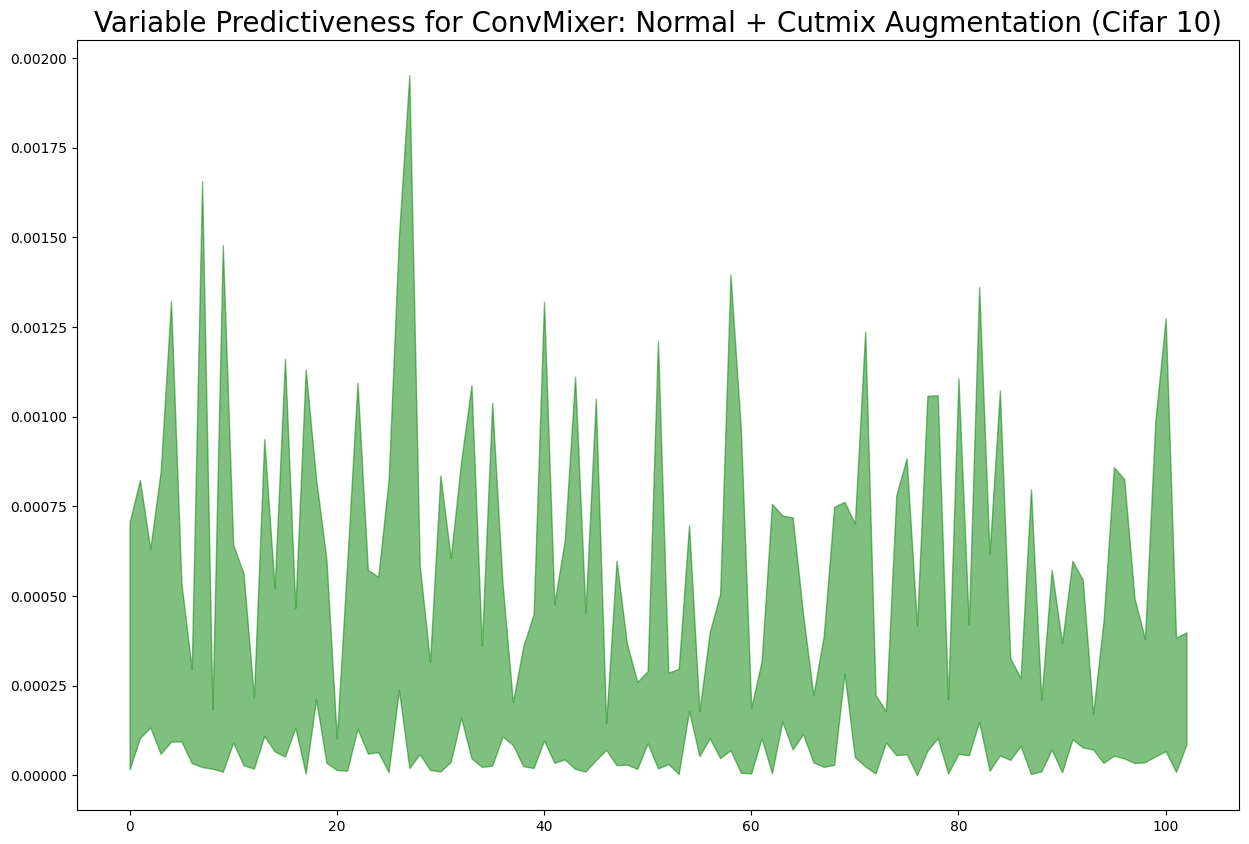

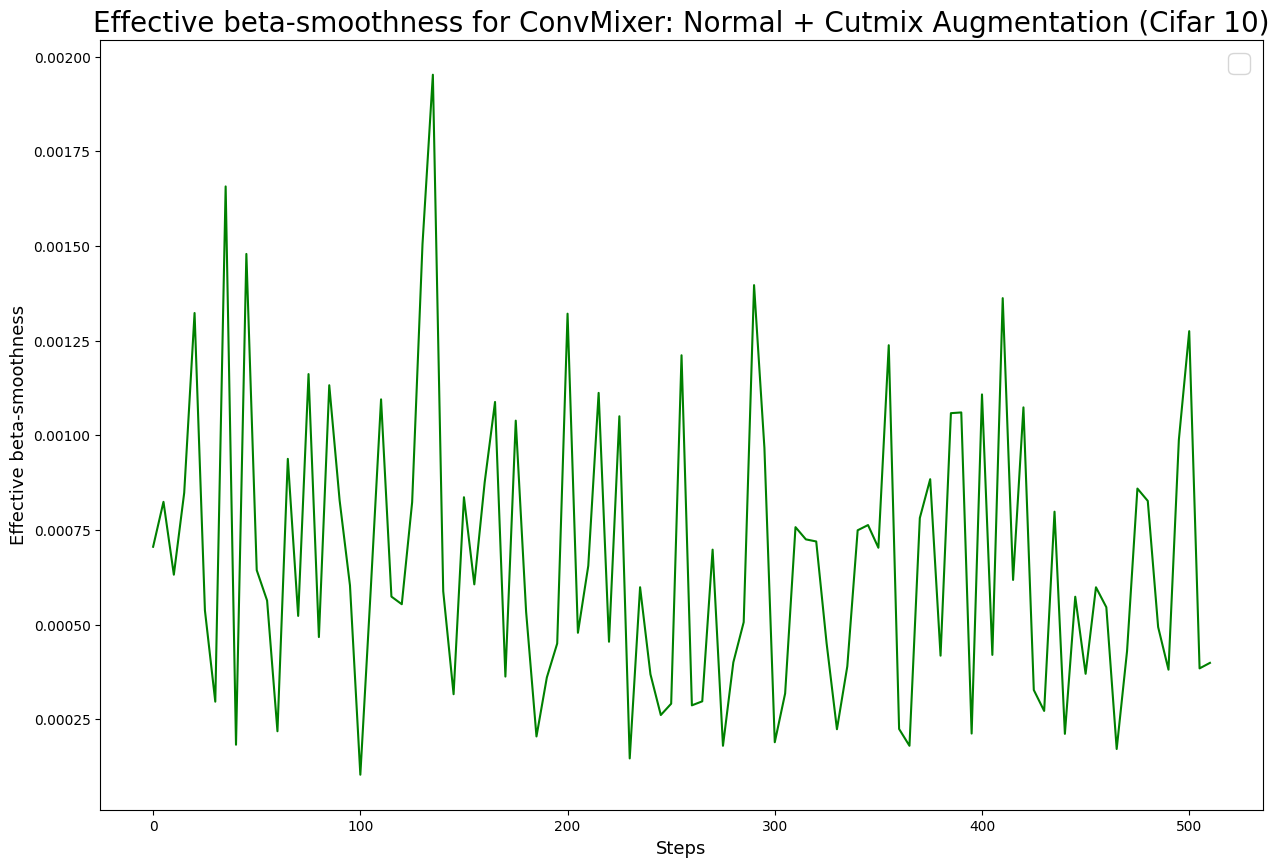

In [15]:
min_curve_cutmix = []
max_curve_cutmix = []
for i in range(len(d1)):
    min_curve_cutmix.append(np.min([d1[i], d2[i], d3[i], d4[i]]))
    max_curve_cutmix.append(np.max([d1[i], d2[i], d3[i], d4[i]])) 


plt.figure(figsize=(15, 10))
plt.title('Variable Predictiveness for ConvMixer: Normal + Cutmix Augmentation (Cifar 10)', fontsize=20)

plt.fill_between(range(len(min_curve_cutmix)//5+1), min_curve_cutmix[::5], max_curve_cutmix[::5], color = "green",alpha = 0.5)

step = 5
steps = np.arange(0, len(min_curve_cutmix), step)
plt.figure(figsize=(15, 10))

# Plotting the smoothness for only one curve (e.g., Standart VGG)
plt.plot(steps, max_curve_cutmix[::step], color='green')

plt.legend(fontsize=19)
plt.title('Effective beta-smoothness for ConvMixer: Normal + Cutmix Augmentation (Cifar 10)', fontsize=20)
plt.ylabel('Effective beta-smoothness', fontsize=13)
plt.xlabel('Steps', fontsize=13)
# plt.savefig(os.path.join(figures_path, 'effective_beta_smoothness_standart_vgg.png'), dpi=500, quality=100)
plt.show()


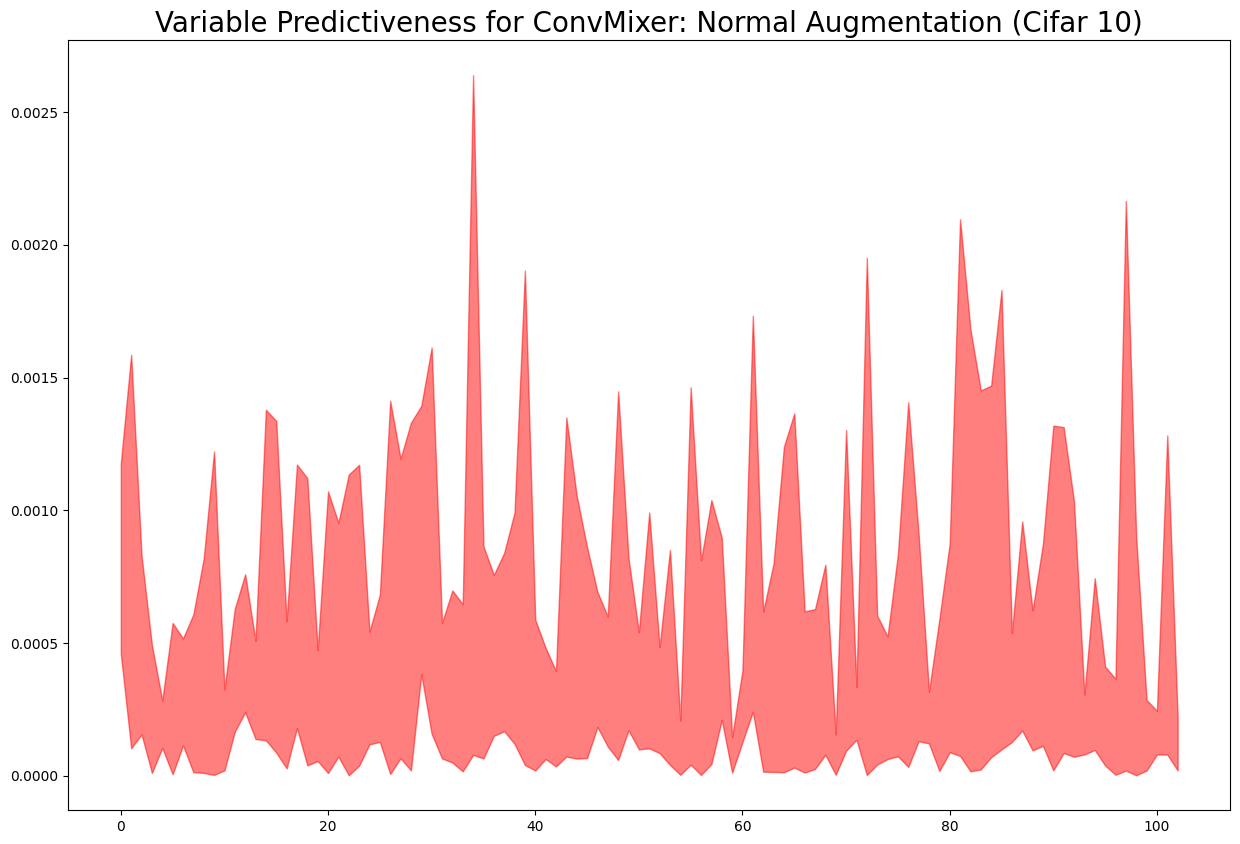

In [26]:
min_curve = []
max_curve= []
for i in range(len(d1)):
    min_curve.append(np.min([d11[i], d12[i], d13[i], d14[i]]))
    max_curve.append(np.max([d11[i], d12[i], d13[i], d14[i]])) 


plt.figure(figsize=(15, 10))
plt.title('Variable Predictiveness for ConvMixer: Normal Augmentation (Cifar 10)', fontsize=20)

plt.fill_between(range(len(min_curve_cutmix)//5+1), min_curve[::5], max_curve[::5], color = "red",alpha = 0.5)


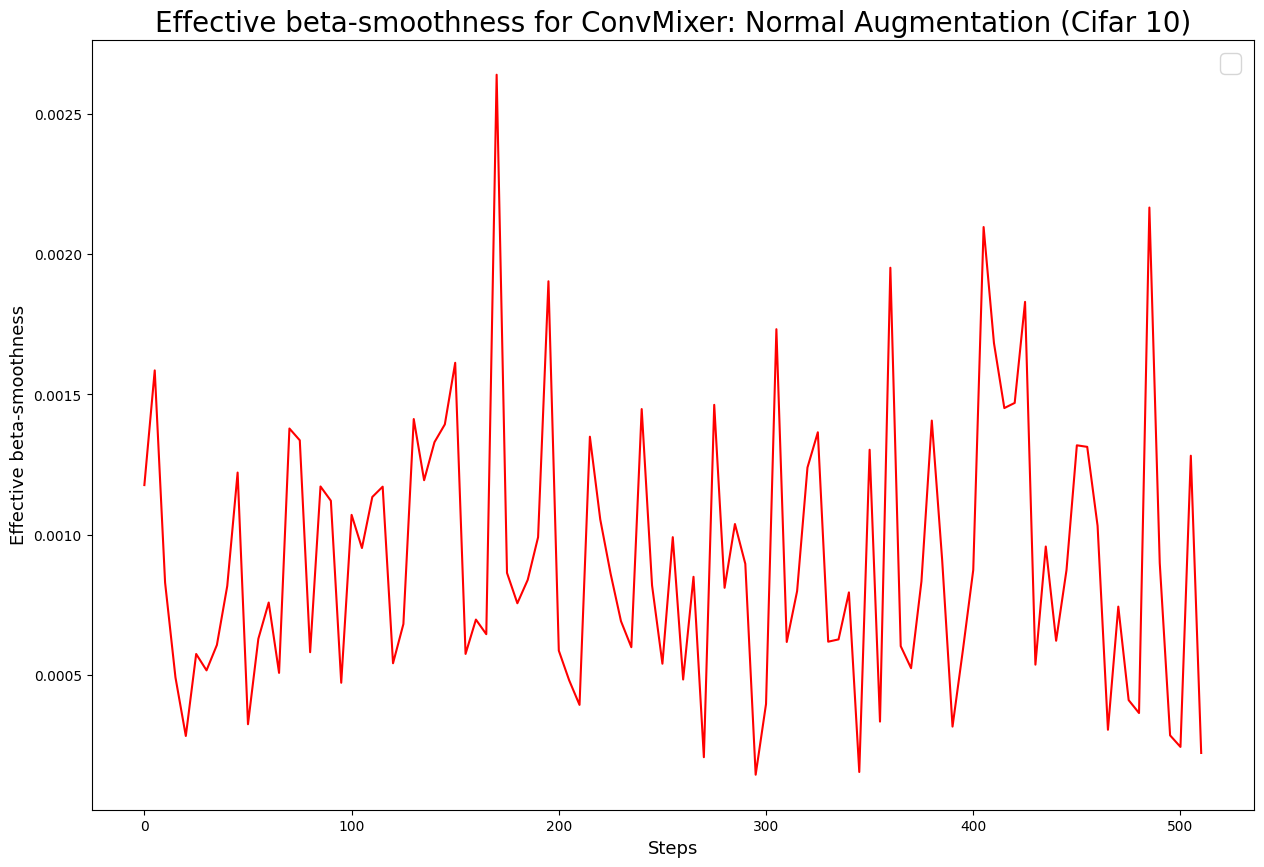

In [27]:
step = 5
steps = np.arange(0, len(min_curve), step)
plt.figure(figsize=(15, 10))

# Plotting the smoothness for only one curve (e.g., Standart VGG)
plt.plot(steps, max_curve[::step], color='red')

plt.legend(fontsize=19)
plt.title('Effective beta-smoothness for ConvMixer: Normal Augmentation (Cifar 10)', fontsize=20)
plt.ylabel('Effective beta-smoothness', fontsize=13)
plt.xlabel('Steps', fontsize=13)
# plt.savefig(os.path.join(figures_path, 'effective_beta_smoothness_standart_vgg.png'), dpi=500, quality=100)
plt.show()

# getting plots together

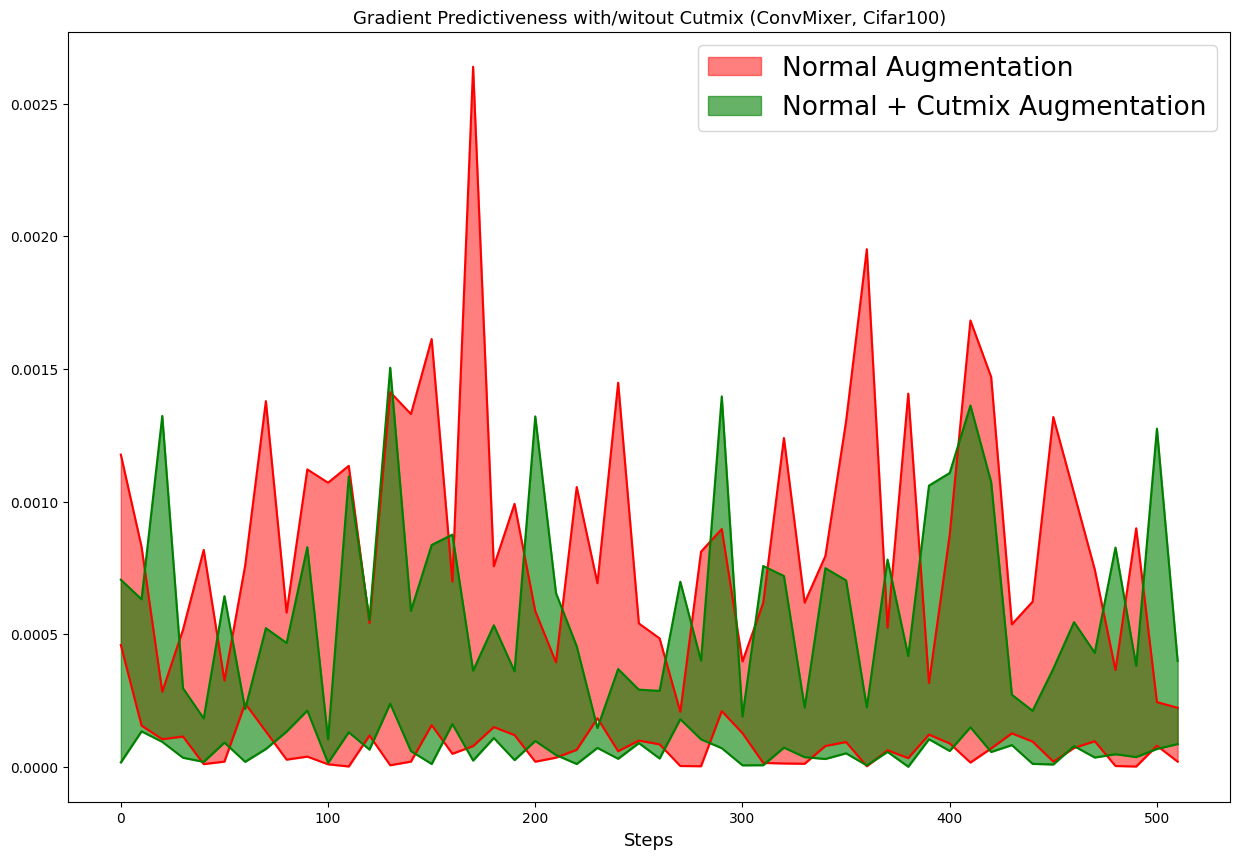

In [28]:
step = 10
steps = np.arange(0, len(min_curve), step)
plt.figure(figsize=(15, 10))
plt.fill_between(steps, min_curve[::step], max_curve[::step],
                alpha=.5, color='red', label='Normal Augmentation')
plt.plot(steps, min_curve[::step], color='red')
plt.plot(steps, max_curve[::step], color='red')

plt.fill_between(steps, min_curve_cutmix[::step], max_curve_cutmix[::step],
                alpha=0.6, color='Green', label='Normal + Cutmix Augmentation')
plt.plot(steps, min_curve_cutmix[::step], color='Green')
plt.plot(steps, max_curve_cutmix[::step], color='Green')

plt.legend(fontsize=19)
plt.title('Gradient Predictiveness', fontsize=20)
 
plt.xlabel('Steps', fontsize=13)
plt.title('Gradient Predictiveness with/witout Cutmix (ConvMixer, Cifar100)', fontsize=13)

# plt.savefig(os.path.join(figures_path, 'gradient_predictiveness.png'), dpi=500, quality=100)
plt.show()

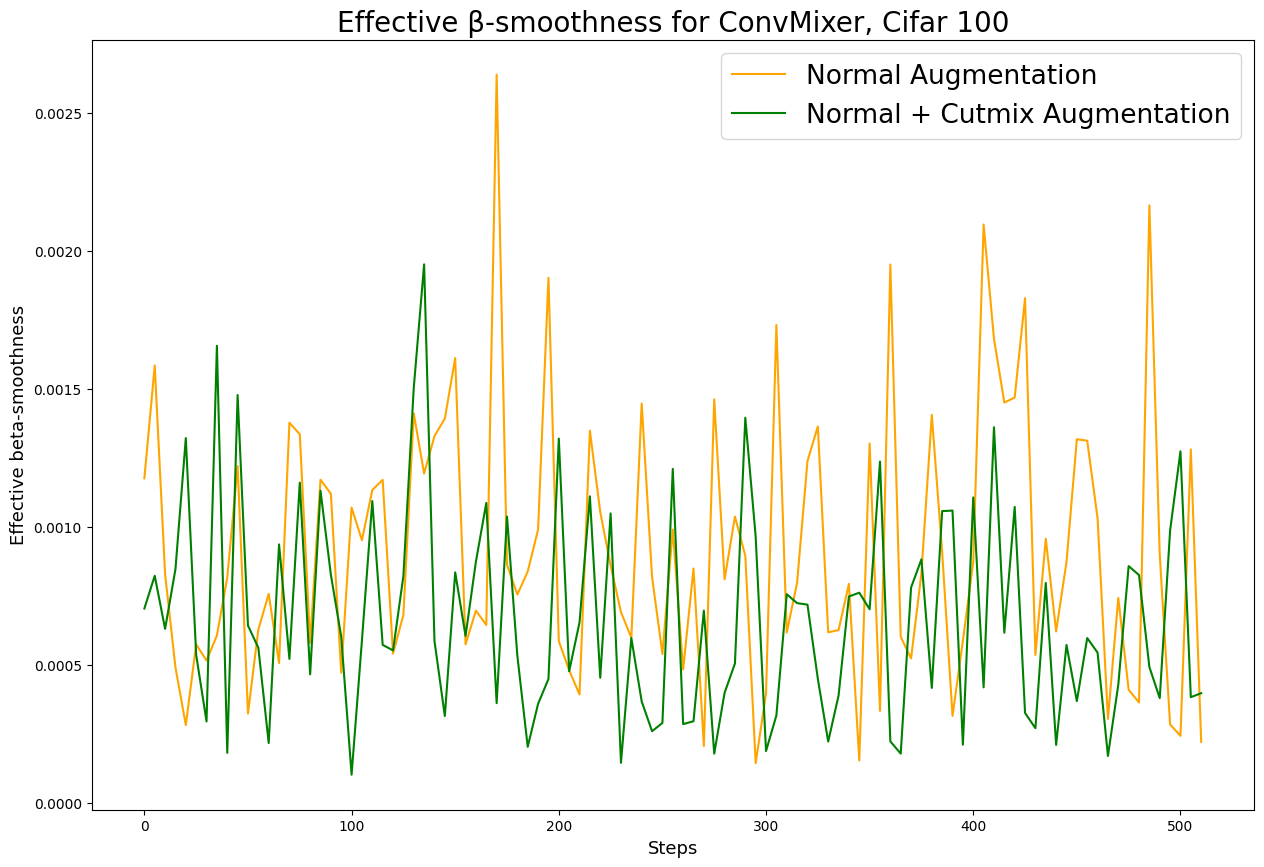

In [29]:
step = 5
steps = np.arange(0, len(min_curve), step)
plt.figure(figsize=(15, 10))

plt.plot(steps, max_curve[::step], color='orange', label='Normal Augmentation')

plt.plot(steps, max_curve_cutmix[::step], color='green', label='Normal + Cutmix Augmentation')

plt.legend(fontsize=19)
plt.title('Effective β-smoothness for ConvMixer, Cifar 100', fontsize=20)
plt.ylabel('Effective beta-smoothness', fontsize=13)
plt.xlabel('Steps', fontsize=13)
# plt.savefig(os.path.join(figures_path, 'effective_beta_smoothness.png'), dpi=500, quality=100)
plt.show() 